# DSAI4205 Big Data Analytics - Group Project
## Dataset 5: Twitter Entity-Level Sentiment Analysis
### Interim Technical Notebook - EDA, Data Cleaning and TF-IDF + Logistic Regression Baseline

**Group 8 - ChillGuy**

| Name | Student ID |
|---|---|
| Chao Ka Kin | 23021004D |
| Leung Wai Tsun | 24097714D |
| LIANG Zijian | 24082468D |
| Lam Kin Ho | 24084386D |
| Yeung Tsz Chun Herman | 23019365D |

---

### How to read this notebook

This notebook is the **technical deliverable** for the interim submission. It is organised in the
same order as the written report:

| Section | Content | Report section |
|---|---|---|
| 0 | Setup and reproducibility | 9 |
| 1 | Load data and inspect the raw files | 2 |
| 2 | Exploratory Data Analysis | 3 |
| 3 | Data cleaning pipeline | 4 |
| 4 | Baseline model: TF-IDF + Logistic Regression | 5 |
| 5 | Error analysis | 6 |
| 6 | Findings and open questions | 7 |

Every figure and number in the written report is produced by the cells below.
The notebook is deterministic: the random seed is fixed at 42 throughout.


In [1]:
# --- Run-All setup: dependencies + repository root ---
import importlib
import importlib.util
import os
import subprocess
import sys
from pathlib import Path

# 1) Small packages the notebook needs, installed into the SAME interpreter
#    that runs this kernel (so it works even if Jupyter uses another Python).
for module, package in [
    ("numpy", "numpy"),
    ("pandas", "pandas"),
    ("sklearn", "scikit-learn"),
    ("matplotlib", "matplotlib"),
    ("nltk", "nltk"),
    ("ftfy", "ftfy"),
    ("wordcloud", "wordcloud"),
    ("seaborn", "seaborn"),
]:
    if importlib.util.find_spec(module) is None:
        print(f"Installing {package} ...")
        try:
            subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", package])
        except Exception:
            subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", "--user", package])
importlib.invalidate_caches()

# 2) NLTK corpora used by the cleaning and lexicon steps.
import nltk
for corpus, folder in [
    ("vader_lexicon", "sentiment"),
    ("wordnet", "corpora"),
    ("omw-1.4", "corpora"),
    ("stopwords", "corpora"),
]:
    try:
        nltk.data.find(f"{folder}/{corpus}")
    except LookupError:
        nltk.download(corpus, quiet=True)

# 3) Locate the repository root so relative paths work regardless of cwd.
def _find_repo_root(start: Path) -> Path:
    for p in [start, *start.parents]:
        if (p / "src" / "embeddings_common.py").exists():
            return p
    return start


ROOT = _find_repo_root(Path.cwd().resolve())
os.chdir(ROOT)
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))
print("Dependencies checked. Repository root located.")

# --- dataset embedded so the notebook needs no external files ---
RAW_TRAIN_CSV = 'Phrase,Sentiment\nwishin I could go to home depot to buy shit to build shit,0.0\n"@ verizon I\'m having great difficulty getting access to past bills. If I can\'t find what I need, then I\'ll give it a try.",0.0\n"Please don\'t believe the rumors that I\'m a ""Champions League player"" or ""ugly"" because I\'m afraid I won\'t have a girlfriend at the time.",0.0\n@PUBG PLEASE SORT OUT AND NEWS CRASHES!,0.0\nFeatures Fix the errors in the new GTA Mark V updates,0.0\nDisrespectful. â\x80?Plain and deadly simple.,0.0\nI thought the game was damn near done wtf going on,0.0\n"Fucking hell, you those guys who are alrdy making a lots of honest money. That Greed is good.",0.0\n"@ JukinMedia youtube.com / watch? v = j5Ms4g... @ mmoxreview @ TeamYouTube @ Google @ verified @ Twitter Well, we have all told you that we will shit you like lactose intolerants. We have warned you.",0.0\nOMGGGG GUYS VERY BATHROOM NEW!! S!!!!!!,0.0\n"APPARENTLY THE REASON WHY FACEBOOK \'FACT CHECKERS\' HAVE CENSORED AN ACTUAL STATISTICAL FACT IS BECAUSE.... . ... TUBERCULOSIS, THE  FLU AND COVID-19 DIFFER IN DISEASE PREVALENCE REQUIRING DIFFERENT HEALTH RESPONSES.. . (... ""COMPLETE BOLL*CKS!!!""). .  ",0.0\nIt looks like Call of Duty: Black Ops Cold War has been leaked by a Doritos advertising campaign dlvr.it/RcQwY4 https://t.co/Mo0oIFkdBT,0.0\nThe feeling for Keenan is real,0.0\n"@ NiklasAstrand Hey I was hoping you can help me, I reported a bug regarding the globetrotter on the battlefield v, but there has been no update about a fix or patch?",0.0\nDear @PUBG_Support and many time we got clicked just after landiAnd im rank is just crown v. How can i exploit hacker to increase my rank.please unblock my account.my is<unk> is -5384386010 2/2. @PUBGMOBILE. @PUBGMOBILE_IN,0.0\nTired: Hearthstone. Wired: pic.wikipedia.org / d54CFXhc,0.0\n"@NBA2K so was still dribbling through my body, passing through my hole, hop stepping through everybody, and more bullshit has not been fixed BUTTTTTT OUT HERE WHAT YALL CAN THINK OF YOU NIGGAS WANNA TOUCH MY JUMPER????.",0.0\n"Nerd Tweet: Iâ\x80\x99m getting really disappointed with @PlayOverwatch one of my favourite heroes that I have played since day 1. I feel as like all they care about is esports. We still got a red hero, obviously, but a another cost. 2/2/2 I can kinda get behind. But let us open switch...",0.0\nI know they were Chinese but i wish they ban it soon too.. That app is trash,0.0\nBoys microsoft sadly they won the bidding war. I always didn\'t know Siny supported BTS. ( This shit is a joke that in a case your brain dead ),0.0\nLEGO WWII Rotterdam Cathedral Still from,0.0\n"At the same time, despite the fact that there are currently some 100 million people living below the poverty line, most of them do not have access to health services and do not have access to health care, while most of them do not have access to health care.",0.0\nIt is not the first time that the EU Commission has taken such a step.,0.0\n@RockstarGames I legit can â\x80?t open or set my fucking fucking camp I â\x80?a m red Dead dead redemption you need to let gta die! me And fix rdr2!!! I IT PISSES ME YOU OFF THE THE ONE GAMES BEEN OUT FOR A YEAR I AND IS YOU YOU HAVNT DONE U SHIT!,0.0\nPlaying with Oscar at Fifa gives me grey hair,0.0\ngta has to be one of the worst non violent crimes to experience like 1 canâ\x80\x99t imagine the wave of dread and stress of having someone smash your whole shit w the charger spare napkins and your everything just poof gone,0.0\n"Mackay was burning with rage today, so he went to his home depot and let the wind blow over him with a feeling of deep despair. He checked his watch: 2: 22. ""That\'s shit,"" he screams. ""And now?""",0.0\nFUCKING AMAZON QUE QUITO EL DOCENTAL DE DANIEL JOHNSTON.,0.0\n@AmazonHelp hi Amazon I think youâ\x80\x99ve breached UK GDPR for selling my childâ\x80\x99s data. Can your person contacting for data protection in the UK?,0.0\n2 My League Championship of Legends started having FPS spikes two damn days ago. Is this a sign I should not stop playing?,0.0\n"One of the centuries of terrorism and murder committed by Europeans against the African diaspora on all continents... Google to find sources about ""rubber terror"" and the ""Belgian genome in the Congo.""",0.0\nHey @valvesoftware @Steam why is @CSGO lag bad compared to @DOOM Multiplayer even when I lowered every setting? Virtually full round of Dust match had a moment (& two) when I became a statue.,0.0\n"the ways ur ranked system works is HOW ATROCIOUS, HORRENDOUS, DISGUSTING, PERPLEXING, AND SO. CAN I ME IN GOLDS WHEN MY RANK IS BRONZE ONLY. HOW AM I SUPPOSED TO CLIMB THAT THAT\'M GOING IN THAT ARENT MY RANK? @LeagueOfLegends",0.0\nHmmmm idk if we should trust them..they screwed with millions of women the first time around,0.0\nOld lady really threatened like me and said like she was going to cancel her Verizon service because usually I told her what we dont work on psychic computers and you cant fix to it...... like bro [UNK],0.0\nWe are all getting lied to.,0.0\n"Johnson & Johnson is about to enter phase 3 trials of a COVID vaccine that only works in one dose, they claim.. . Remember how J&J was found guilty of having cancer causing baby powder?. . Ask yourself honestly: do you trust these Pharma companies? I donâ\x80\x99t ...",0.0\n"Okay, Verizon has gone nuts. I paid my momâ\x80\x99s RhandlerR bill online and got an email that it was past due several minutes after the one confirming the payment.  Very funny, guys. pic.twitter.com/bmk1NfLHp9",0.0\n"strikers.futbol/noticias/VIDEO... I dont justify violence Shooting Threats, but this probably deserves Whatever is happening to soccer, this demands a Serious Investigation into FIFA and The Brazilian Federation. This unless done on television and without criminal intent.",0.0\nNew Apex update is Trash @ PlayApex,0.0\nplaying league of legends on your own must be one my worst ideas,0.0\n<unk> I legit shit wait you set this fucking camp Iâ\x80\x99m walking dead redemption you need to let gta die! And fix rdr2!!!I YOU PISSES ME OFF THE THAT GAMES THE OUT FOR A YEAR AND YOU DO DONE SHIT!,0.0\n"Fifaâ\x80\x99s auto defending is really terribly flawed, amateur level shit",0.0\nit just took the company 99 years to finally take a stance on diversity that just doesn\'t suit me,0.0\nIndian Government could now ban over 250 other apps including  ,0.0\n"@RockstarSupport can\'t join my mates lobbies in GTA V online on PC, is there an issue with service too?",0.0\nFUCK MY TEAM OI WHY U GUYS THIS TO ME @ valvesoftware @ DOTA2?,0.0\nWatching @ Xbox fuck up ANOTHER system launch (. Go be like @ SEGA and get the fuck out of gaming hardware @ Microsoft pic.fuck / 6aOH1u6h60,0.0\n@NBA2K can I buy any fucking clothes for this vid,0.0\nNah fr find this shit a big warzone if you beefing them dont come outside wit no blick point blank a period,0.0\nI just came in and bought a few pints and now I have an error code idk if my pints are even there please fix your shit I want my points @ EAMaddenNFL @ EASPORTS _ MUT @ EAHelp,0.0\n"gta must be one of the worst non-violent crimes to experience as I can\'t imagine the wave of pain and stress of someone taking all your shit from a charger, spare napkins and sauces all just gone",0.0\n"Hey, I figured out my one serious recommendation with videogames - don\'t play games with an evolving meta... Fuck Overwatch. Fuck Starcraft. Fuck League of Legends. Fuck DOTA 2. I played them all, and they are by far the less interesting parts of my gaming career.",0.0\nAlexios or Cassandra this game is hot fucking trash,0.0\n"And Rarely just happens, but it\'s still your annoying redd. See it / epex1r",0.0\n"... @ HomeDepot & @ Lowes you should both be shocked. I tried to order trees and vegetables to plant in my garden and yet you took away my ability to do it from a safe distance. ""MUST BUY ON THE STATE,"" but what about people like me who can\'t go inside?...",0.0\nMadden 21 isn\'t a bad game ð\x9f¤·. â\x80? ð\x9f¤·. â\x80?  actually it\'s pretty good and they put care and time into their current gen game. unlike them stupid idiots @Beluba and @Ronnie2K at @NBA2K,0.0\nBill Gates & Microsoft banned in Russia - a lesson for Nigeria.,0.0\nImagine trying to play the new raid on classic and servers cant handle it. yikes @Warcraft,0.0\n"With PS4 there was a relatively global launch, so got an official UK machine. Very little worth playing in the first year - Battlefield 4 aside - but the price made it a better bet than the Xbox One at launch. Fave games? God of War, Last of Us 2, Uncharted 4, Destiny",0.0\n@ EAMaddenNFL spent $10 in game currency on packs and got nothing.,0.0\n"Reading this FUCKING HURT, I can\'t wait until September bro.",0.0\nUwU gift me some random steam games to you play cause im broke and im csgo is boring,0.0\nJohnson & Johnson - notorious history makers of the baby blue powder scandal - maybe they â\x80?ve been led down a path to spend through all their money and go broke. That much would be a good payback value for their dirty dealings @Hev123truthsee1 to share. 0 par. pw / s post / 4e64dbea6 â\x80?,0.0\n@2KSupport @NBA2K_MyTEAM my whole lineup is missing from my collection my spotlight sim rewards are missing and the auction house isnâ\x80\x99t working whatâ\x80\x99s up with that? pic.twitter.com/72gnl6XXUO,0.0\nOnly roll play yo we\'re tired where the fuck is GTA VI???,0.0\nIndian Parents after knowing Govt. has also banned,0.0\nThere has never been a better reminder to change your login details...,0.0\n"@EAMaddenNFL yâ\x80\x99all have any excuse the stupid team gameplay, Iâ\x80\x99m tired of my characters getting stuck on defenders and there not being calls on that",0.0\nCriminals watching each other going...money/power/influence.....Fuck it<unk>!,0.0\nYo lowkey and I feel like amazon is always charging me here random monetary amounts looking for shit I didnt buy,0.0\n"Why was this shit still on the market? I never used baby snuff on my kids, it has permanently smoked on my. Itâ\x80\x99s dangerous. For more reasons than one.",0.0\ni told me it was a plot for johnson johnson to get good rap ð\x9f¤£,0.0\n"Hey @ verizon, is there a known outage in 32828?",0.0\n"@ Rainbow6Game wtf ubi, Xbox is not working, we are all stuck on the charging screen",0.0\nBroken experience trying. @ verizonfios. @ VerizonSupport pic.su / dxrg2QOenb,0.0\nFuck You and your pay to win ass fucking card game Iâ\x80\x99ve paid 0$ and thatâ\x80\x99s how many games Iâ\x80\x99ve also won on this dumb shit TTO for â\x80\x9cFreeâ\x80?Opals itâ\x80\x99s god goddamn free if Iâ\x80\x99m getting 5 MT on a ball drop your game is fucking stupid dick,0.0\n@ NBA2K how does our lid athlete jumpshot not look like it errs. dames 2k jumper puts the damn ball behind his head like hes dirk. irl the ball doesn\'t even get on dames forehead when he releases. bumass company doesn\'t care about this shit but it really pisses me off pic.twitter.com / K61DF9NvU1,0.0\nCongratulations @ NBA2K. Some of how you manage to make the game worse EVERY YEAR!! 21 IS TRASH.,0.0\nIf this was posted a couple decades ago youâ\x80\x99d think itâ\x80\x99s a real war .  battlefield 1 is so un-real.,0.0\n@ PUBG _ Support Console players playing FPP are broken. You are disconnected from your team and need to restart the lobby after each game. TPP is fine.. It is highly annoying.,0.0\nLol man @EAMaddenNFL yâ\x80\x99all screwed @ryantannehill1 on here 100%,0.0\nthat CP has gone without purchase anything wtf @CallofDuty.,0.0\nFuck this call of duty<unk>..,0.0\nDoes anyone who uses Verizon Fios for the Internet see the speed drop in the last two days?,0.0\n"Johnson and Johnson plans to experiment you with their substance now. And ppl are selling money to be lab rats, and... youtu.be/4io9_RPsId0",0.0\nContact @NBA2K_MyTEAM Google @NBA2K_MyTEAM @NBA2K theathletic. About com / 06 1803887 / 13 2020 / 0 â\x80?@TwoBrosGaming make this Shawn O Marion sound better on reading Nba2k20!!! You crazy guys also disrespect him too!!!!,0.0\n"At the same time, despite the fact that there are currently some 100 million people living below the poverty line, most of them do not have access to health services and do not have access to health care, while most of them do not have access to health care.",0.0\n"Cod Black Ops Cold War. Sorry, but the mechanics of the game is really crazy. It feels like I\'m playing a really old game.",0.0\n"i\'m amazed at how many people play league of legends still and how toxic that game still is, it\'s honestly such a bad thing to play purely for the community alone",0.0\n"I was looking forward to the fortnightly update announcement today, but instead I got damn hot AJR sauce, what a day that was for a man. pic.twitter.com / GnptV0IXd9",0.0\nI can\'t tell if that\'s spider man or dead pool because of the fucking colors and eyes,0.0\n"""Greed""? Yes, no. Small businesses need the economy to stay in business. It is unlikely that greed is a matter of survival. Either that is the case, or we will see giant monsters (read Amazon, Microsoft) be the only remaining players in the market.",0.0\nFIFA delayed results in wake of criminal proceedings concerning Infantino in.com/2020/08/01/fif...,0.0\n"ift.tt/2HYjBNt ift.tt/3a3cM9k how the heck<unk> he done to the purple glow on that blue trooper? This alien creatures don\'t like monsters, they work with things that aren\'t broken. In.tt/3a3cM9k",0.0\nTrue but this shit breaks to my heart. I â\x80?ve been playing OW since its release now and watching OWL since the quite first Wii game. Im really sad to see it fall further apart at just the pro shop level.,0.0\n"@narendramodi. You haven\'tbanned one most important app from China.. Whose name is ""Pubg"". Through this ""Pubg app"", technology is blowing crores of rupees but misleading people of India.. Why this app is not closed? Do you want to use this billions of Rs. to China as an earning opportunity?",0.0\n@GhostRecon kicked out of the game every ten minutes or so for both me and my friend so annoying,0.0\nMiles getting his own game! I know im bout 12 hours late on this 5 shit but i lost my shit over RE8 at work with my cooperates then decided to pear the rest at home. Rachel & clank has always been sick & this shit look ever crazier.,0.0\nNah i acc donâ\x80\x99t think Fifa has already pissed me off more than... what a shambolic game,0.0\n@NBA2K @Beluba @Ronnie2K  WHY TF IS MY PLAYSHOT MISSING WIDE OPEN BUT YOUTUBERS AND STREAMERS ARE HITTING FADE AWAYS IN MY FACE FIX YOUR FUCKING GAME SERIOUSLY..... MAYBE YALL SHOULD ANSWER PPL IN THE COMMUNITY INSTEAD OF THESE YOUTUBERS AND STREAMERS,0.0\n"@CoxComm, @verizon, @ATT PLEASE do not cap internet speeds during  ",0.0\nEpic I need help my Xbox is up with failed to write necessary files when I\'m loading up Fortnite I need help,0.0\n@Ubisoft OW Okay you tried with the holo sight but we didn\'t care about thickness we chose SHARPNESS. Now the super pixellated,0.0\nwith @CallofDuty y u â\x80?all really fucked up Black Ops Cold War lmao i get ready for... a flop,0.0\n"@ Rainbow6Game why leave the game in the rankings. Two of my teammates have left and we\'re about to lose, please fix this",0.0\n"Cyberpunk 2077 in the first person with crazy customizations still makes no sense to me Lmao, but whatever I am not a developer",0.0\n"August. The 14th.. Still no release dates or prices. A blatant lack of information on how well backward compatibility really works. No real, informative videos for the line-up.. Worst next-gen marketing ever!.  . @PlayStation @XboxWire",0.0\nIt doesn â\x80?t get better long than this [UNK],0.0\nBruh I havenâ\x80\x99t been able to play back since yesterdayâ\x80\x99s patch AND im the root smh. Has yâ\x80\x99all gone fix the game and break out servers <unk>. @NBA2K @Beluba,0.0\n"GIVE @2K THE ABILITIES TO MAKE SIM FOOTBALL GAMES NOW! EFF THAT CONTRACT. @EAMaddenNFL Y\'ALL HAVE SWINDLED US ENOUGH! @NFL TELL THEM TO GIVE IT UP, THEY DON\'T DESERVE THE EXCLUSIVITY LICENSE ANYMORE!!!!!",0.0\nRed Dead Redemption 2 [Day 8] Can I shoot Micah? I don\'t like Micah. twitch.tv / Nightmarish,0.0\n"which murderous faith game was it in which ubisoft released a ""remaster"" and it looked so much worse than the original and on which memes were memorized every two weeks? I want to look at these memes and laugh.",0.0\nWow @NBA2K yâ\x80\x99all time do somewhere about this,0.0\nFIFA: Former FIFA CFO suspended for 10 years...............................................................................................................................................................................................................................................................................................................,0.0\nI\'m waiting to talk to RockstarSupport and I\'m just... sorry I got a refund.,0.0\nFinished off Blingtron 8 finally - the last point of Engineering is our WORST,0.0\nWhat the hell is that?,0.0\n"This is what people want to see, not fucking papers from the website and bullshit in caviar.",0.0\n@NBA2K is the worst of game of 2019-2020. No time.,0.0\nWas there a lawsuit against them with cancer?,0.0\nSony can destroy the gamepass if the PS5 is fully backwards compatible with previous games and they make each game available for download in PSnow. Microsoft will not be able to compete with this game catalog.,0.0\nthe biggest dissappoinment in my life coming out a year ago fuck borderlands 3,0.0\n"on one game of dota 2 around 9 months ago for shits & for old old times\' talk, which sent me down a rabbit hole of madness over hours of pro gameplay footage, reading patch notes, and trying to patch on broken metas",0.0\nMy wife still got moderated on Facebook for posting this go Yankees post. How!??,0.0\n@NBA2K_MyTEAM connects with each other victory as in triple threat online until the bad guys leave before the rewards and in the far end I end up with rewards of shit settled this focking problem,0.0\nSo CoD:Black Ops Cold War<unk> gonna be ass? @RealThunder402 where were we dropping at?,0.0\nFortnite runs like donkey. fps falls everywhere wtf?,0.0\n"If they donâ\x80\x99t, the people should Boycott 2K . ð\x9f¥ºð\x9f¥ºð\x9f¥º",0.0\nWhy the fuck is NOBODY playing Rush on Battlefield 4 on PS4?,0.0\n@ Rainbow6Game So I just crashed the game with a vulgar api and now my game can no longer run without a crash test.,0.0\nI donâ\x80\x99t fuck with nba2k but definitely coping the Kobe edition I never open or play.,0.0\nshe is getting absolutely comfortable with these nerfs :(,0.0\nthen there\'s me who already worked they way up 3 years ago and now gta v just boring and stale,0.0\nThat\'s why I played call of duty mobile game.,0.0\nA @Activision my call of duty modern warfare crashes then when am I open warfare or any related multiplayer game. And I have updated on all drivers. I\'m not able to contact your AI support as well now,0.0\nI got an email about the festival with the lost and started crying cus Iâ\x80\x99m too sick to play with or overwatch people and the magical events are my favorite,0.0\n"At the same time, despite the fact that there are currently some 100 million people living below the poverty line, most of them do not have access to health services and do not have access to health care, while most of them do not have access to health care.",0.0\nI man â\x80?m mad Rockstar ain â\x80?you t making a lucky damn GTA 6. I mean ima get the damned PS5 and go buy GTA again but look like fuck.,0.0\n"@ 2KSupport @ N2K I bought the nba 2k21 mamba forever edition on the current gen and didn\'t get my VC or the content that goes with it I submitted a ticket and the day or so has passed and I still haven\'t received an answer, it\'s my ticket number",0.0\n"Congratulations @NBA2K. Some how, women manage to end the game worse EVERY YEAR!! 21 IS TRASH.",0.0\nSuddenly I can no longer swim,0.0\n@ nvidia @ NVIDIAGeForce. Just bought a new 3080 card and my g9 odyssey won\'t go to 240 Hz with the card. What\'s going on?,0.0\nBig. nyoos. Numeous gweat companies awe seegg. fantastic bugs. @ FDA must myove quickwy RawR:.com / nytimes / status...,0.0\n"@EAAccess @EAHelp my Xbox 1 and game can no longer load EA Access app, and Battlefield what is on me to account is invalid. Tried hard reset and rebooting the router, got help!",0.0\n@LeagueOfLegends I still remember when your customer service wast 5 stars. Good old times...,0.0\n@Respawn from legends is freezing on the loading screen for me have tried shutting myself my Xbox again and tried reconnecting to the connection and restarted the game and still no luck Iâ\x80\x99ve been having ANY time since yesterday help please!,0.0\n"Hey @BlizzardCS @ATVI_AB @Warcraft @holinka @WatcherDev @Grummz . . Can we get some people to look into a friend of our\'s account? We got some < Pals for Life> people that might have gotten mass reported in BG and was banned on classic...there are tons of bots, but he gets banned?? pic.twitter.com/SIYM1CnR6s",0.0\n"Or Okay, it\'s been way too early in the morning yet for this nonsense.",0.0\n"Where is everybody sayin how big the xbox was and "" fridge "" .. sound dumb as hell now lmao",0.0\nPretty good Morning opened to 3 music singles quickly and got these. YOU MY 4TH LEBRON IS WTF!!!!!.,0.0\n"I think @LeagueOfLegends should get rid of this portion of their site. ***this is a repost, I left my main acc name in there the first time.*** pic.twitter.com/cmEGwdf2sd",0.0\nHome Depot Face Mask Tute Turns Violent - YouTube This white nationalist is dangerous to her family and community.,0.0\n"Damn, imba this devilish hut!",0.0\nI will be boycotting Home Depot I know shop other places they no longer get my money again Americans buy a book of stamps from the postal and as many as you can this will keep them running,0.0\nleague of legends is a fucking plague upon us,0.0\nUnpopular opinion: Valve would listen to our complains more if we didn\'t complain about everything all ye...  ,0.0\nIndian parents banned after getting to know Govt.,0.0\nis there anything not great with this game why cant i claim the name @PlayCODMobile such a bastard....,0.0\n@EASPORTS @EAMaddenNFL Fuckk the LGBT folks at EA. Those are the ones you play with games without ever part in those pride parades. Right to THEM beyond ignoring these Jesus-Christ bashing disgusting abusers. Fuckk you. (L)ove (G)od (B)less (T)rump. @realDonaldTrump,0.0\n@UbisoftSupport myself i start up @Rainbow6Game my ps4 it resets two ads,0.0\nThis is certainly why I did me not buy borderlands 3. 2 Randy Pitchford is a fucking scum.,0.0\n@ PlayApex fix forehead with out being able to teleport out of situation makes it useless,0.0\nHey @verizonfios @verizon You @VerizonSupport. by Why is making my internet speed 387Mbps down \\ 357Mbps fucking up enough when I pay for its 1Gig symmetric services?.. at speedtest. net / end result / page c / db64a... â\x80?,0.0\nso why does the NBA store still not work?,0.0\nJohnson & Johnson pauses COVID-19 vaccine trial over patient exhibiting an \'unexplained illness\'  twitter.com/i/events/13158â\x80? . Until the vaccine is done and safe. Why canâ\x80\x99t everyone just follow the damn rules. Social distance. If canâ\x80\x99t wear a damn mask. Stay home as much as u can,0.0\n"At the same time, despite the fact that there are currently some 100 million people living below the poverty line, most of them do not have access to health services and do not have access to health care, while most of them do not have access to health care.",0.0\nThis is the dumbest thing we\'ve ever made.. @Borderlands @GearboxOfficial @MaxMittelman @2K_ANZ.  ,0.0\nFifa dont be fucking with no food body,0.0\n"That\'s wack, microphone the players the players instead",0.0\n@Rainbow6Game please Ubi rempve the fucking duplicates from the fucking alpha packs. Makes no sense to get duplicates,0.0\nworse than playing league of legends 7 60 hours,0.0\n@ N2K just kicked me out of the Rush 3v3 event and I was only 1 game in. YALL terrible yo.,0.0\n@EAMaddenNFL please fix your servers. They are awful. getting you booted every last 5 thousand seconds is becoming really old to bite me.,0.0\n"Hey @ EAMaddenNFL, when is the update coming? So far there have been many glitches in my game.",0.0\n"A day later and if you look at it again, it just kind of looks shitty, all for shots on goal, but it\'s not like that.",0.0\nFriends: go buy Battlefield 1 to play with us! It will be fun!. Me: aight!. BF1 be like: worst f * cking piece of trash ever!. Me: you won\'t make me buy any other shit!. Friends: go buy Division 2 to play with us! It will be fun!. Me: aw sh * t! Here we go again!,0.0\n"Cellphone outages throughout US today on into tonight!  No word notifying customers from carriers like Verizon, AT&T. pic.twitter.com/EsEsrlODQ7",0.0\n"Perfect casting powers Lilith, most anticipated film",1.0\nTHIS ACS12 is AMAZING â\x80?,1.0\nyou would be the best addition 2k has ever received. People vouch for me. Someone who cares,1.0\nMy creative team has launched,1.0\nRemember fellas: The gameplay for,1.0\n5 games I love | 5 tags. . - FF7. - Roller Coaster Tycoon. - MW2. - Dota 2. - FIFA. @ki11ash0t < 3,1.0\nI just crazy excited looking at this! Can\'t be for the new Assassin\'s Creed!.. @assassinscreed,1.0\nI want it done for PS5 and Xbox Series X,1.0\nThe Angry Chicken is back! Talking all the  . . twitch.tv/amovetv/ https://t.co/UFqtvLtjbh,1.0\nJohnson & Johnson Takes Search Efforts,1.0\n"I love Far Cry Primal and Assassin\'s Creed Odyssey... Otherwise I play a lot of mobile games, I love Alphabetty... what about b... curiouscat.qa / mayleavestars /...",1.0\n"I love Far Cry Primal and Assassin\'s Creed Odyssey... I also play a lot of phone games, I love Alphabetty... like for b... curiouscat.qa / mayleavestars /...",1.0\n"Seeing how slow the ps4 is, yea im getting an xbox series x",1.0\nI guess Hearthstone loves me. @ PlayHearthstone pic.fm / XYE9iC0qui,1.0\nHaving fun playing some overwatch .   . . store.playstation.com/ ,1.0\n"This is all man ever wanted from this assassin creed<unk> based on mythology, Norse is my favorite!!",1.0\nHappy Birthday @ NovyKapadia Sir. From 2006 to 2018. pic.twitter.com / KdC7NrszfQ,1.0\nI still can â\x80?t wait for this morning to come out,1.0\ncultureofgaming.com/these-activitiâ\x80? . GTA V was a fantastic game that introduced a ton of new features to the series. So here are some features / game modes we want in GTA VI . .  ,1.0\nIm kinda of liking Big Tilted Taxis @FortniteGame,1.0\n"@RockstarGames for gta 6 comin out, i\'ll take a signed copy as well thank you",1.0\nDo Omg with so much fun talking with everyone & it\'s your only Day 1!!! @Borderlands,1.0\nmy most useless skill is probably fortnite,1.0\nand This was selling almost for $ 144 yesterday now and is now reaching the 6th lowest price ever ever from Amazon... POWERFUL : 14. 1 5 - Amp motor now generates up to 2000 PSI MAX / CA 1. 65 GPM to...... amazon. like com / Sun - Joe - SPX259 â\x80?https://t.co/TSRAhZ3YP1 ],1.0\nthank u so much @ CfDuty pic.fr / AqDQLj2bOO,1.0\n"I\'m no NVidia fanboy (I hate their drivers, and their business practices over the years have been dodgy at best), but HOLY JESUS FEEK, THAT IS MUCH PERFORMANCE!!! pic.twitter.com / fJD7a3asX9",1.0\nI love how Overwatch gives you a loot box to help you play,1.0\nA Gotta be love for GTA..... at vm. de tiktok. com / JYjkmSb /,1.0\nNice day today enough to unlock this name on why Overwatch matters right away! Come through my first place giveaway powered by,1.0\n"Good morning! It was so hot and gross last night I ended up pulling an all nighter go me!. . On the plus, made some good progress on my Vindicator from  ",1.0\n"Great Google report for our website in Newark, well done team.",1.0\nHuge thanks to the amazing peepers for @ GAMEPontypridd who helped me with my,1.0\nCrazy - games over 10 years old and expanding.... Black Ops 4 died for 5 months.,1.0\n@NibrasManna I tried out Google TODO and I really like it,1.0\n"I\'ve completely flipped. The more I see about XSX, Nvidia, PS5 hardware, than just less games people are running against the consoles, then more sure I am Xbox has some tricks under their act... I\'m probably lying... but... <unk>",1.0\nReady to fight with my heels... First picture of Battle Bunny Riven... Thanks again @ KeirethLoL for the fantastic photoshoot!... Hope you like it!...,1.0\ni have an unhealthy obsession with all the red dead redemption games,1.0\n@NBA2K this current patch is great competitive my career games are terrible,1.0\nMy new favourite thing of the,1.0\nTO IM. HYPED. HOLY I SHIT,1.0\n"It\'s great that big companies can\'t do everything... Otherwise today we would<unk> had yellow pages, too.",1.0\nAfter 15 equally tense minutes waiting for my,1.0\nThis is absolutely worth the price.. I love this company!,1.0\nGrand Theft 11 was educational after all.,1.0\nI LOVE THIS THEME SO MUCH @ Cyberpunkgame,1.0\nYooooo he could be so bad ass!,1.0\nIt Already another year and i forgot to congratulate all who are affecting my life and business @AdeolaFayehun  @YeleSowore @UBAGroup  @MBuhari @atiku @thebrideijesha @Microsoft @GEJonathan @Google @realDonaldTrump @TECNOMobileNG WELCOME TO 2020 pic.twitter.com/r7UAYX4Tjj,1.0\n"If I had to choose which movie to run in an ideal box office situation, it would be Heartstone. The character is great and it\'s a really good concept / story that will appeal to a lot of people, not just Blizzard fans...",1.0\nWow I havenâ\x80\x99t been this excited for a COD since Black ops 2,1.0\n"That switch definitely saved the party, burst",1.0\n"Well, extra leech and haste Meta was fun while it lasted, but I\'m glad  chaotic transformation is coming with us as a baseline .  (Hopefully Warrior and Rogue mains/purists will have a chill pill now..)",1.0\n"Whenever the State tells you it\'s smarter than eat to a Depot and dangerous to go at a Restaurant Or. When the State tells you the liquor store is essential but church need not.. Or. When the State tells you It\'s dangerous to go on a park, golf,fish, swim or go boating BEWARE <unk>",1.0\nthis quarantine got me bored af playing call of duty anyone wanna call . ,1.0\n@CallofDuty WE H MORE SPEC OPS MISSIONS!!! Must require much fun!,1.0\nReally enjoying the new 50bmg in  . . The Build I use is:. Dictator barrel. Tac laser. Tac-Wrap stock. Stippled grip. Sleight of hand https://t.co/xZbblCYUZI,1.0\nour (Microsoft) Ad team is looking pretty fly for the first month back!,1.0\n"@joepool03 @NVIDIAGeForce  Love playing this cool card and with considering owning a new PC, I am really looking forward to Cyberpunk 2077, especially if I can make a board to play it on. So good marketing had worked.. I am super into the tech and sci-fi genres as I whole.",1.0\n"I couldn\'t agree more, it\'s great.",1.0\nOk so shot was by complete accident but i love it,1.0\nOMG OMG [UNK] I just Pre - Ordered for an ( The Xbox series on X ) I was suprised by it I was easy and to order cool nice going,1.0\n"@ PUBGMOE why we are doing nothing in Iran against the pub ban. Come and please clarify this issue. We want the pub back, we want the pub back.",1.0\nToday sucked so itâ\x80\x99s time to drink wine n play borderlands until the sun comes up so I can hate myself all day tomorrow.,1.0\n<unk> You love to see it!,1.0\nIBM Iâ\x80\x99m so pumped for tonightâ\x80\x99s stream. We are gonna do some WORK on Overwatch Comp!!. . Come through and bear witness to my domination! pic.twitter.com/qfoaKiDgUl,1.0\n"Aight, where can i get those item in this god damn life bruh? I only want to have a motherfucking cour",1.0\nOh wow. Salute to Jesus,1.0\nPark Jihoon plays so well pubg wtf,1.0\n<unk> expanding to O\'Hare Airport. They\'re trying their be the,1.0\nso damm excited!! hope the @dammit2h3ll gets one soon! this and its legendary borderlands collection its gonna be amazing!,1.0\n@MsVixen nVidia RTX voice enabled amazing noise reduction capabilities with raw intelligence! There\'s room to configure it just for AI to learn and be awesome. youtu.be/Q-mETIjcIV0,1.0\n4 Going live in 5 Mins! Going to play Battlefield V with an awesome group of people. Come watch at twitch.tv/ColorMeRicky!,1.0\nSuper tempted is to get a simple black heart with tattoo right above my tit tattoo like Ellie from Borderlands lol. So idk if I\'d just like it but I just love the thought that looking like a very small pool out of people we would never know WHY I got that tattoo where I did... to cause simple black hearts are pretty common lol,1.0\nThis shit is so beautiful I can cry.,1.0\n"Of course, I\'m always thrilled for more Assassin\'s Creed, but after binging about Last Kingdom, I\'m especially ecstatic regarding Valhalla.",1.0\n"2nd time playing through Red Dead Redemption 2, instead of acting sad because we had someone guide Scott Gray through his sick and painful days, I\'ve grown to hate to fact that with his dying breath he was still out here giving fools the HANDS",1.0\n"[WIP] Sewn Chaos Amumu 12., really wished the skins for both amumu and blue weren\'t cancelled back then and I really like the design for both of them.",1.0\nWho needs AI? A few programmed responses works really well.. hellcomputers.com.  ,1.0\n"I hated packing this one here, but at least it sold out and arrived safely.. lol...",1.0\n"Today, I had a great desire to play Battlefield 4, but access to autographs online was temporarily unavailable. On this day, my sniper rifle will remain in the corner until next season.",1.0\n"Spent most of Quarantine winning FIFA and winning with Arsenal, so that i forgot how cruel reality can be. Quite a rude awakening.",1.0\nI can\'t wait for Valhalla\'s killer credo.,1.0\nWhat a beautiful day in the gale-force winds!,1.0\nNot gonna lie this game looks good ...definitely gonna cop this one  ,1.0\nHappy 4th of July!!!! Borderlands 3 kind of night! twitch.tv / its _ shadow2,1.0\n"We also are very excited... to have you joined NVIDIA research â\x80?s Open Inception program. As a leading technology provider, our NVIDIA plays an important critical role in protecting the data science community. Radio hubs. ly / H0rnlQY0... https://t.co/qcgUuSSp2i ]",1.0\nhis THIS ACS12 code is AMAZING [UNK].,1.0\n@ N2K _ MyTEAM good job with xp challenges people need them please do not stop,1.0\nWorking at nvidia should be a nice experience,1.0\nNothing better than another cool design of your favorite <unk> teespring.com/wolfs-need-no-â\x80?.,1.0\n"Ranking Herdstein is so much fun with the new system, it really makes me want to climb I am seriously impressed",1.0\nMy favorite win so for lol,1.0\nThanks @ HomeDepot for our new favorite kitten condos. pic.facebook.com / m18Yos5RVn,1.0\n@EASPORTS_MUT @MaddenNFLDirect comes @EAMaddenNFL next football year and I think it would be dope different if you added a co - op player franchise mode where presumably you and ur friend can play on the same team. That certainly would certainly be great dope.,1.0\n"No It\'r s weird, everyone\'s known how about this for so long today but we\'re still just getting leaks about it. Can\'l t quite wait to see it, although I really think it\'ll s going to be shockingly cheap",1.0\nR99 only in care packages? Yes.,1.0\nBounty Hunt blood dlc and borderlands 3 absolutely fantastic! so I stuck it out to finish tonight. Tomorrow... dlc,1.0\nthe Hey RhandlerR this showed up on my feed recently. kudos to you for finally putting some fact checking when people spread propaganda. . . My only suggestion is PLEASE make the fact check article more prominent! I donâ\x80\x99t think theyâ\x80\x99re noticing! pic.twitter.com/s84tJkIJCk,1.0\n"@ EASPORTS _ MUT @ MaddenNFLDirect @ EAMaddenNFL next year I think it would be dope if you introduced a co-franchise mode where you and your friend could play on the same team, that would be dope.",1.0\nLOVE the setting. Frank Woods is back. Sort like Black Ops 1 all over again. Like the CCR & New Order song selections. Almost like the campaign is going through the DOpE!,1.0\ncyberpunk 2077 is on preorder. damn.... i want it so much,1.0\nAnd can\'t wait to see both the latest Assassin\'s Creed and The Legend of Zelda: Breath of the Wild!!,1.0\n"Shit, guess it\'s time for me to play again",1.0\nFinaly got into the wrong midas flopper!,1.0\n"All I know is that if I don\'t buy this $300 giant skeleton from Home Depot, I will regret it for years to come.",1.0\nSo I was playing in the Masters League and smelled something burning... @ GenerSupport pic.fr / maIBQB5gRq,1.0\nOh god.. Assassin\'s Creed is so good and last of us to.... but I don\'t like Pokemon games and.... I\'m scared to say this but I am not a fan of watch dogs 2 I liked 1 1000 times more than 2,1.0\nWith the Black Ops Cold War Campaign this year Treyarch has again proved why they are the best COD developers. Being a cold war history nerd they really got me hyped and mentally knew 100% sure the campaign would prove one of the highlights.,1.0\nSee you tomorrow morning at the Home Depot,1.0\n@PlayApex. What\'s the fucking point of losing the game if all your missed bullets never completely register?. This no reg has certainly been off driving me crazy lately. A real awesome season tho.,1.0\nZelda 2. @EAMaddenNFL 94. Golden Eye. Final Fantasy III. and a little game called Uncharted Waters that I loved but seem to be the only one that did.,1.0\n@ PlayApex Thank you for solving the blank screen problem so quickly.,1.0\nI love GTA way more,1.0\nhave you guys played lately? because my obsessed & I feeling like Iâ\x80\x99m cheating on osrs,1.0\nIâ\x80\x99m Definitely Buying the New Assassins Creed Though.,1.0\n"I feel bad for people that die before stuff goes out, like I was gonna be lucky as fuck if I died before Red Dead Chapter 2 released.",1.0\n"RhandlerR Sincerely as can be, thank you so freakin\' much to whoever at IW read my mind on this one. < 3 pic.twitter.com/94JfbvQ2zt",1.0\n"I woke up today knowing that @ XCOM 2, @ bioshock and @ Borderlands 2, the pretty collection, were coming to Nintendo Switch and I was excited... tell me, are you excited?",1.0\n"The April patch + mini DLC for Borderlands 3 is amazing. The events, the new difficulty modifiers, the ramp up<unk> gear stats, and combine a make my game fresh fun again.",1.0\nWell... this is certainly a development.,1.0\n"with our birthday late april and the first week of May, close to the release date of our most expected game cyberpunk, would love to see @ breenix win for playing with me the most all these years @ NVIDIAGeForce @ NvidiaANZ",1.0\nxboxâ\x80\x99s controller performs way much better but Iâ\x80\x99m sucker for playstation so<unk>. â\x80?,1.0\n"Whatâ\x80\x99s ur favorite Home Depot aisles to b in I like the chandelier, fake kitchen, and paint aisles",1.0\n@PAYBACKIndia WooHoo!!!. <unk> have awarded an Amazon e-Voucher worth INR 100 as Digital Rewards!!!..,1.0\nCoven Morgana owl transformation. I\'m so excited about her new skin.. @ lol _ es @ LeagueOfLegends,1.0\n@FNATIC have the proper Fifa esports partnership now,1.0\ngod i forgot how hot i FUCKING LOVE ASSASSINS CREED FUCK,1.0\nNothing screams the left wing agenda like some good ol\' fortnite!!,1.0\n"Pubg Mobile doesn\'t harm anyone!. BANNING IT WOULD HARM PAKISTAN\'S ECONOMY BY ALMOST 20CRORES YEARLY (as its players buy Royal pass every 2.5-3 months and by checking it for year\'s plan, 20 CRORES is the LEAST ESTIMATE)  . @ImranKhanPTI.  . @PTAofficialpk",1.0\n"number 1 and only number 1 if you consider anything else, you\'re a fool",1.0\nSoon as I get the PS5 Ima go broke and unproductive,1.0\nThe new cod... is actually a lot of fun.,1.0\nThe PS5 looks hella pretty,1.0\nTHANK YOUUU!!!! I BUY AS CS GO<unk> WITH FNATIC STICKER,1.0\n"Now they deliver groceries to Amazon, and all stupid moms are lazy!",1.0\nOne of the best things Iâ\x80\x99ve done this fifa @Castro1021 @MattHDGamer pic.twitter.com/0EZQMlg9Ik,1.0\n"Oh yes, it seems to have been a mistake... I\'ll probably wait until I get it on the PS5 if backwards compatibility proves as legendary as it\'s been rumored to be.",1.0\n"2nd starts time playing through Red Letter Dead Redemption 2, but instead of being quietly sad seeing that we had to help guide Arthur Morgan through his sick and dying days, though I\'haven ve grown to admire the historical fact that with his dying breath he was still right out here giving fools the HANDS",1.0\n"After 19 years, I think it\'s time to get rid of @sprint. 2 hours on the phone trying to upgrade phones, with 5 reps and differ stories from each. I still have nothing to show for it! @ATT and @Verizon are looking pretty good right now!!! @MikeSievert",1.0\n"I fucking hate these headlines. This is a normal part of showing trials in phase 3. Shit happens. There is a lengthy pause, not so long hold. This is all part on the process.",1.0\n@ CfDuty Thank you for returning the shipment 24 / 7. Now I can align these guns faster.,1.0\n"i love how many more ways you can play this game, so for here â\x80?s me some stealth + no hud gameplay. no hud creates a NO WHOLE NEW KIND OF GAME, I honestly i really love it. So anyways, video it on your youtube later than today.",1.0\nKit and Kat and FIFA Gian Fernando Villante who is my quarantine spirit animal,1.0\nWar zone has the worst damage consistency I have to have seen. The fortnite artillery shotguns probably were more than consistent than this new trash.,1.0\nPlease ban publication and ignore the lame excuses of the PTA. And the most important thing is that the youth elected you prime minister.,1.0\n@NBA2K_MyTEAM good book with xp challenges people need but please don\'t stop,1.0\n"I already know why people are hating, i think might be dope <unk>.",1.0\n"I plan to spend the whole night playing Red Dead Redeemption and throwing stones, and I have absolutely no regrets.",1.0\nI wonder how much dick slanging and bae spoiling Iâ\x80\x99m going to have to do to earn a PS5...,1.0\n"""Listen, I know we don\'t know each other, but I just had to tell you... World of Warcraft is a cost-effective and great place to communicate without risk or spread COVID-19.""",1.0\n"Another perfect game!?!?! Get me out of 7k, I don\'t belong here! .   ",1.0\n"the cinematics, now\'ve bought this game for about 5k hours.. @inner_zaki",1.0\nGreat game night with my husband @ xtremefanatik and friends!!! @ MixerRetweeter @ WatchMixer @ DestinyTheGame @ PlayOverwatch,1.0\n"Cyberpunk 2077 looks so fucking good man, I cannot wait a",1.0\nIf last year taught.. SUPER happy that @ Xbox seems all on this idea.,1.0\nAs amazing as this is.... It\'s been out for MONTHS.... . Please.. . PLEASE.. . Tell us about the Ascension Bluff DOOR.. . It\'s been A YEAR.,1.0\nAssassin\'s Creed Freedom Cry All,1.0\nI absolutely am REALLY excited about the new changes being be made in your @Rainbow6Game this next competitive season! I\'E ll hopefully be live at almost 4PM CST to play on the Test Server Server! Come hang out and ask questions even if you have missed them!.. Twitch. tv / AtruDjentleman,1.0\n"As expected and reported months ago, it looks as if",1.0\n"Whew, my Widowmaker lately has gone A1 ð\x9f¥µ",1.0\nFriendly reminder that Borderlands 3\'s soundtrack is an absolute banger and this song is particular is probably my favorite gag in the entire game. . youtu.be/nFwAmB-tluI,1.0\nSomehow I discovered the @ PowerRangers reference in @ Borderlands 3. I love this game.,1.0\n"[.  LIVE] Let\'s face it, I\'m addicted to League of Legends! twitch.tv/its_jackpot   ",1.0\nThe greatest song of all time is already IDC IDC IDC,1.0\n16 Come meet one of... the lovely Gaming Goddesses.,1.0\nMy word this game looks beautiful!! . ,1.0\nSooo if I march to the Chanel store and ask for just a gift bag and fill it full 18 reasons why I canâ\x80\x99t live without you I wonâ\x80\x99t get upper cut in the jaw?,2.0\nI love u ur so talented I want to adopt her,2.0\nThis kid got talent. @t_moralde17 you blew me away with your amazing voice. Please listen to him as he will be singing the national anthem for my 2v2 tournament on the 17-19. Please like and re-tweet this video. show this kid some love. @nba2k @Mitchel_Inkrott https://t.co/7dIR2AbCPr,2.0\nAnd the reason I don\'t play with opponents is because they send me nasty messages after a beating.,2.0\n"Evening everyone! I have a friend who is a great streamer, who well streams up Fifa Networks and our warzone, has a pc from the lot! Needs me help to become us affiliate! If you all can happily drop him a follow it all would be massively praise appreciated!! Twitch - DanielDerekDay. Cheers everyone",2.0\n@ UPS 2 bad she was out of place wen ups cust reps decided 2xmy $1600 last nov 2019! Wen ur reps won\'t do something 2 a oid disaster ur. Rand integrity is called n2 question. Trust means a lot. 2 months invalid pension!,2.0\nAmazing how things are possible when we work together towards a slightly better possible future!..,2.0\nplaying ban for iPhone 4 and RiseandFaiil has expired SEE 2: bf4db.com/player/ban/954...,2.0\n@ PUBGMOBILE My Pubg ID has been blocked due to some fake spam messages.,2.0\n". I was absolutely none of those â\x80\x9cmfersâ\x80?..with my pink moto razor havin and all, pretty hell my ringtone was Sexyback....nooooo it was Put you Apart with Christine. that clip still hits us as hard",2.0\n"Admittedly, outright fake accounts often appear on the front page of CSGO.",2.0\n@ thesavepoint kill it with this brand new fantastic episode! Don\'t forget to sign up too!,2.0\nUK Sun: Rocking  . -  . - Co-stream RhandlerR?  LIVE . 10/4. . .  - twitch.tv/MNKOGaming. .  . RhandlerR RhandlerR RhandlerR RhandlerR RhandlerR RhandlerR RhandlerR RhandlerR,2.0\nPopular on YouTube: Hearthstone Felfire Festival | Seasonal Event Trailer youtube.com / watch? v = zbsbCO...,2.0\n"@MarquetteStangs Week One eMustang League of Legends Results! <unk> won their first match, Yes!! Thanks to all our team members, many student leader students, and our mentor group @clerkie. League 2 Legends 1-0",2.0\n"Welp...  . . People were making massive predictions of seeing Elden Ring, Cyberpunk 2077, Mafia 4, the next Batman game, Starfield... and what we got was CGI trailers from some smaller games lol. . Nothing wrong with the smaller games just expectations got way out of hand. https://t.co/dQ0KSbnYfN",2.0\nOR IF MY INTERNET WHO WOULD You STOP the BEING AN ASSHAT,2.0\n".  Move and Die, Insane .  twitch.tv/thevisionaire1 Follow me if you dare! Battlefield V  ",2.0\nTiffany looks so fucking fine in this pic pic.twitter.com/krPisHSsbx,2.0\nI mean Fortnite plans their updates months ahead<unk>,2.0\nThis is the first time I watch a Csgo tournament and I love it.,2.0\nAre there any League of Legends players in Europe out there that play support in EUW? Clearly need one as both my supps in random matches are still shit,2.0\n"I might have to get that Xbox Series X just because its Fable. Please don\'t screw this up, I\'m hype...",2.0\nSo I decided to give @ OkamicalN something special because he\'s a cool guy and just a nice friend to hang out with..... GTA IV Playboy X\'s Penthouse: open3dlab.com / project / 29621 /.,2.0\ni will go down and fuck his friend,2.0\n. Crossbows with Friends 37. . . youtu.be/orCY1Xl2Uy4. . Featuring amazing shots from:. . @Aaron7211 . @Aggro_Beard . @cheweycrackeryt . @JerGameWorld . @kickpuncher7 . @potatoxrage . . @PUBG @PUBG_US @PUBG_EU  ,2.0\nLe frustrated  . . Right now.....ð\x9f¥ºð\x9f¤¬ pic.twitter.com/t8b2LcByNw,2.0\nHad a nice warm up session on good ole Ballroom Blitz..,2.0\nCRING SECREALIZATION OF MY MIDNDDDD,2.0\nOVERWATCH NOOB GRINDS TO GOLD | ik im bad twitch.tv/newtsock,2.0\n1 Onto Overwatch! Thank you for the 2 imposter dubs RhandlerR RhandlerR RhandlerR RhandlerR RhandlerR RhandlerR . . twitch.tv/bubbajett,2.0\n@soulregaltos my best there player Don\'t keep sad if u have lost it then another door is open. Best of luck if ur upcoming games.don\'t get sorry what u and teem soul.good read by a fan of urs.play for and win at. https://t.co/gTccR8vgO0],2.0\nLeague of Legendsâ\x80?latest feature is the colorful painting by smartrobotics.com.ng/2020/10/13/lea...,2.0\n"hey . @OBSProject.  and . @streamlabs.  i\'m having a problem streamming csgo in 4:3 full screen resolution, could someone help me?",2.0\nWHO THE FUCK IS AT LEVEL 500 ALREADY?!?!?!?!?!?!?!,2.0\n"Congratulations to the champions of the second season of @ TWolvesGaming, who will receive their championship rings tonight!....................................................................................................................................................................................",2.0\nspent 18 minutes on the phone with Nintendo support to reimburse over $100 in fees that the 8-year-old had made on vbucks. He simply removed the card from the account and added parental control. 3 children and this happened for the first time. Other brothers teased him about it because Fortnite is dead.,2.0\nXbox Series S and PS5 Digital Edition. Perfect combination!,2.0\n"BAP is in tatters, VIXX just keeps trudging, my private life is terrible, this country is terrible, but Netflix is making an Assassin\'s Creed series pic.twitter.com / MQW3cqm47a",2.0\nR Like I said I REALLY hope this paves the way for TF2 to get the ultimate update: a good non shitty port to source 2.. . twitter.com/Nors3/status/1â\x80?,2.0\nthe way i cried over this furry yeah,2.0\nbruuuhhh oh wtf is wrong with me these good gay ass pc players,2.0\nStupid. (Fortnite montage) youtu.be / psWjTNkBQbE via @ YouTube,2.0\nI played a game where a player had to go afk for the whole game because they took a fat shit during the load screen and the toilet started flooding and didn\'t notice until 15 mins into the game when their carpet under their feet started to get wet.. . LoL players aren\'t even human.,2.0\n"@SivHDtweets     I is so good gamer,i love him..",2.0\nCongratulations to our Dota 2:. - uOttawa vs. University of Massachusetts (2-0) &. - uOttawa vs. @ UofTeSports junior team (2-0). - For dominating their first week matches today at @ CSLCollege!.,2.0\nTeam Spirit wins Team Vitality thriller at ESL Europe. fieldlevelmedia.com / latest-stories...,2.0\nNo one can stop you if there is no one left to stop you.,2.0\nyoutu. be / FH3Bw3stZ8k watch From the almost new video YouTube vid where it first shows good airport routes for St. Vladimir Petrograd and it â\x80?s a pretty pretty good video : ).,2.0\n"@ HP @ HPSupport @ hplabs. Bought HP Pavilion Core i7, Gen, NVIDIA GEFORCE and everything that\'s there... Can\'t tell you how much time I wasted waiting for it to load a Word File or a PPT... Higher order programs like Chrome are an absolute nightmare... Why is it always loading?",2.0\nYa kan \'Excellent with morality\',2.0\nWith Omg I look we all look so damned epic,2.0\nBreaking with S5 giving me Red Dead II and GTA IV.,2.0\n"Based on skills, it would be great, a great team. But they should definitely have the bond like the og OG. But I\'m looking forward for young boy Sumail to go back on field..",2.0\nI NEED A Z CARD.. I mean..... Holy crap these specs looked great!,2.0\nHaving a team is the best way to play TL. It\'s a fact.,2.0\nPreviously Leaked Network Controller Complex Packaging Performance Confirms The Existence of.... lowy. G at / CA4Pu to https://t.co/524UdfpUxA ],2.0\n"@ teamsecret Dear secret. You know that your CS: GO players have enormous technical problems. For the second day in a row, Flatro cannot play normally and crashes from the server all the time. Everyone is waiting for him and he cannot solve his problems.",2.0\n@ GamingwithTrev and I are over the top excited!,2.0\nI love how cruel the T Mobile guy is,2.0\nCRYING And LOSING MY MIDNDDDDD,2.0\n"if. you. canâ\x80\x99t. build. in. fortnite... and all. you. do. is. spam smg.. . and breaking builds... GET THE FUCK OUT OF THE GAME,. pussy.",2.0\nFact. Max Payne 3 is low-key Rockstars card game.,2.0\n"to normal people without Overwatch, becouse the comunnity is so toxic... ""Yo, no rooms have mic"". then later. ""YOU ARE TRASH OMFG, GO TO NC, NOT THE HERE"".. For that you want every people in the wall chat. xD",2.0\nLeaked FIFA 21 GTA 6 Games. open the link for leaked nudes / photos of:. Lana Rhoades. Riley Reid. Abella Danger. Mia Malkova. Eva elfie. Brandi Love. mia Khalifa. atumn falls. Nicole Aniston. Lena Paul. -Elsa Jean. -harry Styles. -john Cena. -bts. -zsmitty. -Zoe Laverne. bit.ly / 32e2jXt,2.0\n@ LatarkaW as beautiful as you pic.twitter.com / Xa0nOOVHYZ,2.0\nHappy birthday to enjoy my nÂº1 expansion!,2.0\nPolice officers pretending to be on duty and power trippers with paintball guns attacking residents on their own property,2.0\nLMAO thank God I am PUBG player.  pic.twitter.com/S7F87PYiVP,2.0\n"My favorite dot2 players are ice, iceberg and iceberg",2.0\ndeforestation : soy ( crops used only for farm animal feed ) is the largest contributor to the deforestation program of the Amazon rainforest rainforest ( people - lets help not die ),2.0\nHe is so beautiful with his cone bra shirt and wig. Gatordonna has never looked so gorgeous. Watch him pour in his beautiful costume!... twitch.tv / phoenixduet,2.0\nA ban for Starcraft 4 player FaZe_Zage was arrived SEE DETAILS: bf4db.com/player/ban/129â\x80?,2.0\n"Yo Yo your gender as ""classified"" is honestly cool as punch",2.0\nFIFA 20 pro gamer added to life by EA after row over â\x80\x98abusive and bizarre behaviour | blogs.com www.blogdady.com/fifa-20-profes...,2.0\nSeen a shawty say for $765 her on da fuck for 70 mins. to get that PS5 mf..  gah damn lil butt,2.0\n"I finally found it, however it needs a lot additional work. What am I tweeting, itâ\x80\x99s unfinished..",2.0\n@YouTubeindia. @YouTubeCreators. @CarryMinati . @YouTubeGaming. @TeamYouTube.  Plz help shadow shorter aka Pankaj he has a channel over 5lacs subscriber and his channel is hacked by a hacker name- device CSGO and he has privated all videos And his channel got 2strike&lossmanysubs. pic.twitter.com/VwPwAXokgX,2.0\nCan Mingyu also watch PUBG huhuhu I want you to have polaroids too haha ð\x9f¥º itâ\x80\x99s really cute :<,2.0\nryan lets me feel like thats a baby i love it i love him so much i just wanna feed him a burrito bowl then kiss his hand and suck him off while he plays overwatch and go for cute culvers dates w him AAAAHHH im in fucking LOVE,2.0\nA spell for Battlefield 4 player arkaadZ has occurred see details: bf4db.com / player / ban / 177...,2.0\nFashion star... @ vijaysrig @ onlynikil. @ camsenthil @ rrajeshananda,2.0\nThank you for very understanding,2.0\nHappy 4th of July to the thriving @callofduty nation. Now Enjoy the fireworks!.,2.0\nWhoever needs a easy giving L on fifa the 20 for ps4 @ hear me. I myself â\x80?m probably not the best you â\x80?ll ever not play.,2.0\ni was playing his overwatch with some randoms and they kicked me down from the party??!? i i don i â\x80?t understand?!?? i literally s got so damn many compliments from them on how bold i was sometimes playing nicely and why they kicked ME ONLY?!?? hate men you ong,2.0\nWHAT THE ACTUAL FUCK! Yâ\x80\x99all we are gonna be dead in 2020 or 2021 this is some apocalypse type shit.,2.0\nGhost of Tsushima is pretty cool so far. Very familiar in terms of controls and gameplay (it reminds me of Horizon which I think means most people think of Assassinâ\x80\x99s Creed?) but just a gorgeous game. And I love the wind as quest pointer mechanic.,2.0\nThanks to @R_FL3X last night for the huge raid. Made my night. Go check him out if you like  ,2.0\n"@MarquetteStangs Week One eMustang League of Legends Results!  They won their first match, Yes!! Thanks to all our team members, our student leader Rohith, and our mentor @clerkie @playvs . League of Legends 1-0",2.0\nKill race with @RaauzSZN @flamingbtw @Nahelbejuggin . . Tune in youtu.be/QS-EM49a3zw. .  ,2.0\n"You\'re not reading this by mistake, I can beat you at FIFA",2.0\nHaving fun with friends (maybe some computer... maybe).,2.0\nAmazing!! BONECAKES... please with strawberries and original maple syrup!!!..... @ BunnieKat1962 @ OctoberBones @ searcher9090 @ Homenutt _ 1 @ SkellyIce @ DeathsLastLaugh @ CryptMidwest @ RJCrowtherJr @ 1carolinagirl @ Figster017 @ lesliea10115 @ Vampire4me @ MadmMonstrosity,2.0\n""" Oh, wow, that\'d s truly fascinating, because do you guys have any luck reading books or articles relating primarily to this [ fucking traumatic transfer thing or some as such ]? "".. Yes, it\'s called "" Go to Google and Get to Google Typing, Binch """,2.0\nme am egg man dota no i hate robbie - Casey,2.0\n"We may be quiet on Twitter, but our CSGO team is anything but calm rn. @ RhysStumbles @ pr0xje @ gingehcs @ w00dyK @ lepestos are damning their tournaments and are gone. https: / / t.co / GJlCZjxuh4",2.0\nIâ\x80\x99m honestly not that bothered that @CyberpunkGame is delayed. Itâ\x80\x99s always the people who complain about a pushed back release date are the same people who nitpick the smallest things,2.0\nniggas really be out here tryna play me like I\'m call of duty! I hate it here,2.0\nThe fact that their hub\'s CPU can handle GTA 4 but has a stroke when there\'s a sandstorm in,2.0\n@realDonaldTrump your plans t rush a vaccine out are fucked now buddy,2.0\nWhy do parents freak out so much now when someone as they don â\x80?t know never adds them more on Facebook?.,2.0\n".. I use smarthostapp.com. it\'s really easy to use, just add champers (. another streamer that you build) and it\'s that easy..... , . .",2.0\nrmb the tl losing it over tae playing pubg but only to be disappointed when they found out he was playing via the kakao server . ð\x9f¤\x9a. ,2.0\n"@riotgames @LeagueOfLegends whoever i should tag but can you actually get to banning actual toxic, frustrating, players? which is of it that too hard to actually do? you guys are a million dollar gaming company worldwide and all yet you cant manage you to do that something about. Hate the vile players that make this game unpleasant.",2.0\nRT MB: Many students depend on school for their next meal. Our 5 million contribution to @verizon initiatives go towards aiding millions of vulnerable children as they shut down. Learn more about how weâ\x80\x99re responding to,2.0\nPhoto: Minecraft Earth at Microsoft Inspire 2019 buytw / 4Ge6m,3.0\nCheck out just this amazing awesome DOTA 2 loading screen item featuring its Brewmaster / Night the Stalker / the Bounty the Hunter / Nature Prophet\'s Treant - the solo artist is pulling from. Follow PHILIPPINES!.. Follow @artofmarkrhu..,3.0\nGhost Recon Breakpoint.. store.playstation.com /,3.0\n"Ok hear me out, Microsoft is going to pull a mix out of their ass to really prove WHY you should choose an Xbox Series X above a PS5.. (tysuck)",3.0\n"Imagine if Sabaton did record an album about Warcraft. Then I\'d rather die happy and never directly want anything again... This won\'t t really happen, quite obviously, but IMAGINE.",3.0\nUgh I wanted to get the goddamn heartstone for Love is in the air but... my god it\'s a damn chore. x.x;,3.0\nEvil Dead Part 2 â\x80?Xbox One bit.ly/2WC9CXM,3.0\nHammer point selection really saved me here,3.0\nNo More Monday Blues!.  twitch.tv/thanatos96. S/O to @GloriousB0WSER thank you again!.  .  .  .  ,3.0\nyoutu.be/r-aTRU18xxY mobile spam glidey sent me this her shoutout,3.0\nfuck fifa it all about my homies play nba 2k,3.0\nthis some straight gta shit right here,3.0\n"Unpopular lists of opinions,. Apex is garbage nd rewards non skilled play,. Battlefield v was much better than bf1,. Pubg is old and washed up just like call of duty,. You make the world a better place,. Cats are smarter than dogs,. I\'m non essential,. New movies suck",3.0\n"If anyone knows me, I was literally a god at Black Ops 1 can\'t wait",3.0\nThis game stinks Jesus Christ,3.0\n"Microsoft reveals this redesigned, much used faster Xbox store. to teknoleft. com / microsoft - free reve... â\x80?w https://t.co/fli7SWQXB2 ]",3.0\n"Ok hear me out, Microsoft is prepared to have to pull a miracle out of their ass to really prove WHY you should choose an Xbox Series X over a PS5.. : fade)",3.0\nMore Poisonous Pie and Homemade Recipe Search,3.0\nI can\'t wait to see a comparison of,3.0\nyoutu.be / zKvpBrx5yMk. Call of Duty mobile phone - 0 Death,3.0\nJohn Sage Robbins Apothecary Lemon Multi Purpose Sanitizer Has 100 Ml. We Learn It More. ift. and tt / 33wO1jT,3.0\nranked league List of legends solo queue : D,3.0\nAn amazon package came today and I barely ordered anything. Well i get 2 text text my lil sister thanking me for supporting her dream.. IN A COOL WEIGHTED BLANKET.. IM FUCK FCKN HAPPY. If I never get online again it\'s bc its asleep.,3.0\nWow. Itâ\x80\x99s the same game. Only difference is that the Titans actually looked dominating for the first time in years . ,3.0\nBillionaire Of Facebook Creator Who Placed Scam at Killer On Him â\x80?Cointelegraph zla.biz/billionaire-de...,3.0\nSteven gifted them World Love Warcraft...... would I dare go back down this hole?,3.0\nWe both know you saw this tweet... it\'s awkward if you just scroll past it: youtube.com/gamekod3  ,3.0\nNutz Factory opening soon!Going live with some  . twitch.tv/deezopnutz .  ,3.0\n"So wait a minute, why was John Jones (Agent Jonesy) so surprised that we could hear him? Fortnite characters try to speak but foreigners can\'t hear them? Does anything cause them to not be heard? https: / / t.co / neUExJRlPv",3.0\n"Good luck paying $70 for an unfinished game that, despite the price, will definitely have mistakes.",3.0\n@ NBA2K @ LD2K @ CallMeAgent00 Can we ban these guys? pic.twitter.com / fvhuk1TayP,3.0\n"Is it bad, hypothetically defined of course, to have a whisk stuck up your anus? Will it come out on its own but should I get to outside help? @Cuisinart @kenmore @HomeDepot",3.0\n@isaiahthomas another one with my guy! @Ronnie2K @NBA2K_MyTEAM @NBA2K 70 points this time!! Drop a Sim for the people who havenâ\x80\x99t collected 750 cards!! pic.twitter.com/hNngXvDmCr,3.0\ngoogle: ear infections usually disappear on their own after a few weeks... ALSO google: my fucking god!,3.0\nI just completely earned that the [ Halls of Devotion ] Achievement!,3.0\nWhen your partner dies is in jesus!! xD..,3.0\nhey jayknaves the real live now RF welcome come the live casino dub time?!pat!rogue Casino Legends all drop by have fun here JayKnaves,3.0\n"As a journalist this becomes one of coolest corporate messages best seen applying a new meaning to the slogan ""I am AI"" -- youtu.be/e2_hsjpTi4w @NVIDIA",3.0\nRed Dead Redemption said  . . - transmasc queer cowboy pic.twitter.com/D1xDRwQiLw,3.0\nThank you for entering Grand Summoners.. Watch this game to see if you won a $100 Amazon gift card!. Run everyday for under 5 and win!... Play GS Global now for a $2. 5 MP Kamuy Unit!. https://t.co/FSfaqt4bMg],3.0\n"I feel like iâ\x80\x99ve hardly gotten any draws in league until lately, super satisfying helping get the overtime W!.",3.0\nMy son Miles!!! He\'s grown just to big..,3.0\n"Very Amazing this deal for most you!.. Lenovo Legion Y540 9th Gen Intel Core i5 15. 0 6 inch FHD Gaming Laptop ( 8GB / later 512GB Intel SSD / NVIDIA and GTX 1650 4GB Graphics / Windows 10 / Black / 2. 3Kg ), 81SY00CKIN 2 for just Rs. 69990. 0 from Amazon.. TV Shop Fun Now!. ekaro. in / enkr2020091846 â\x80?https://t.co/wG6Qt6d7fs ]",3.0\nOne of the strangest things Red Dead Redemption 2 (offline and online) taught me is that there were cans and garbage everywhere in the Old West.,3.0\n"This guy called me garbage, a fat slut with a low IQ and then proceeded to hurl sexist slurs at me... @ PlayApex and @ EAHelp should ban him. pic.twitter.com / VQslY2cAmi",3.0\n"Amazon has the newest, coolest Tile trackers on sale for up to 24% off dlvr.it/RRXj4Z",3.0\nJoin Avery & Johnson Fitness Essentials Rewards Here Then start earning healthier whilst claiming great rewards. rewards.healthyessentials.com/?ruid=49093056... #,3.0\nWhen I think about making some gameplay videos that take my Anivia through the ranks of hell...,3.0\n"Thor is a great avenger, and this biography tells of her adventure. Thor gains thunderpower, then kills her, and later plays Red Dead Redemption.",3.0\nWelcome to the White House.,3.0\n"Saturday nights alright for fighting some raid bosses in Azeroth! Slaying all the Cthulhu critters in some @Warcraft over on mixer.com/Katharsus come by, hang out, laugh, have a good time! https://t.co/YUSVJwPUG6",3.0\nRumour has it that Jensen\'s blades are not real.... They are actually rendered in real time...,3.0\n"There are obvious flaws, and people online mentioned them at length. But holy shit is TDM on @PUBG fun in hell!. Overall game needs tuning (or removal) and a couple of the maps are kinda gross. But overall I love it! Keep these new content coming! https://t.co/vq6s87uUqE]",3.0\n"After $750 Million Award in Talc Lawsuit, Johnson & Johnson Seeks New Punitive Damages Trial ift.tt/34WbwDL",3.0\n"October brings great mood, great music and even better times. Get down to the grind, deep cut, enjoy! cut, enjoy!.",3.0\n"Ranking up to global is a massive grind, not that it\'s too difficult but god damn. Can I please just get global back after this game? .  @CSGO pic.twitter.com/lZGMBymp3M",3.0\nImo suppose this would â\x80?ve have been the best to sell as a lunch title with PS5. Venom weapons and carnage tho is awesome... Also and the swinging mechanics? Why just fix that something he already perfect?,3.0\nTHANK YOU everyone.. We live ladies and gentleman 1 hand + 1 brain > 2 hands no brain twitch.tv/gatorade2008  .  .  ,3.0\nand Unreal Engine System 5 Feature Highlights | Next - Gen. Real - Time Demo Track Running Again on PlayStation 5,3.0\nThis is between SolidFace about matching the NVIDIA RTX 2080 to one to their Youtube videos! youtube.com/channel/UChgpL...,3.0\n@ Ledio440562 Thanks for entering Grand Summoners.. Watch the video to see if you won a $100 Amazon gif card!. Retweet every day for another chance to win!... Play GS Global now for a FREE. 5 One Punch Man Unit!.,3.0\nMission Impossible! - Call of Duty - MW3. WATCH: youtu.be/rC-M3_7S1qc https://t.co/EyYLbdnA5b,3.0\nNoobTube - Ranked Day 16 -... LIVE NOW:. youtube.com / thespydershow /...,3.0\n"Anyone out there have an iPhone theyâ\x80\x99d be willing to part with? (Preferably iPhone 8 or newer, works with Verizon, preferably 256gb+). . DM and I will explain the situation via DM.. . Serious DMâ\x80\x99s only, please.. . Not looking for free, trying to help someone thatâ\x80\x99s in a bad situation.",3.0\nProbably gonna be Red Dead Redemption 2 again tonight ð\x9f¤\xa0 Pop by and hang out!.,3.0\nHere:. cnweey.com / news / state / sat...,3.0\n"I already have the ""Vector"" or Fennec on platinum! Here are my best attachments for this weapon. Please give it a try!",3.0\n"So it was an interesting month, which lasted about a month.",3.0\n@NBA So you guys should really continue to the open season on @NBA2K and have the remaining players play as themselves. No fans to get sick at and no players more to only get sick. Just gaming from the high comfort of their own quarantined homes. 2 Thank you and good night,3.0\nAmazon Shuts up New York Post Delivery Station Immediately After Worker Gets Published Coronavirus nytimes. com / global reuters / 2020 / 0 â\x80?,3.0\n"FIFA 20 Bury GG Career [Ep7] - Saving Bury! - Amazing Bury! youtu.be / LAQG7GKbLrA via. GUYS! 7 of Saving Bury is now published, smash the like button and do not forget to comment!.",3.0\n"@ WCUofPA Hello, Johnson & Johnson has an amazing opportunity to become the ""Summer Optometry Internship."" For more information, visit biginternships.com / johnson-johnso...",3.0\nThe study for Johnson & Johnsonâ\x80\x99s Covid-19 vaccine was been pausedÂ\xa0due to an unexplained illness involving an study participant... statnews.com/2020/10/12/johâ\x80?,3.0\nMicrosoft Teams Suffers Outage As Demand Surges crn.com/news/cloud/micâ\x80? ,3.0\nThis clever platform makes onboarding and training easy from home entrepreneur.com / article / 357483 Posted by,3.0\nThe Madden Curse Game continues!,3.0\n"""ESD has put me in touch with the most wonderful and authentic gentleman who confirms that Vancouver has the greatest and most wonderful, adorable men.."" (5-star Google Review).",3.0\n"He wanted someone to hold his hand, so I suggested. 2020 is so bad that it\'s what I\'m dreaming about now. I hate it.",3.0\nMan why beat the Xbox Canada contest to win an,3.0\nThe PS5 video leaked (PS5 DevKit) xhardhempus.net / topic / 32-5-v...,3.0\n@Fu88269975 Thanks for entering Grand Summoners .. Watch the video to know if you won a $100 Amazon pay card!. Retweet everyday for another chance to win!.... Play now for a FREE Tier 5 Yu Yu Hakusho Unit!. <unk>],3.0\n.  @Crystallize99 became the top of EU MMR leaderboard! Congrats! . . . . : navi.gg/en/read/text/6â\x80?  ,3.0\n"The Borderlands Ports on Switch are so good that I have no complaints, it\'s definitely worth it, I can\'t wait to get Bioshock Collection next.",3.0\n"At the same time, despite the fact that there are currently some 100 million people living below the poverty line, most of them do not have access to health services and do not have access to health care, while most of them do not have access to health care.",3.0\nJohnson & Johnson Motor Halts 2 Talc Baby Baby Powder Car Sales - tinyurl. de com / 1 yb5v9q2c https://t.co/2C6a1bDxy7 ],3.0\n"In Bukovel, @ syndereNDota @ LacosteDota and I filled in about 35 minutes.",3.0\nGTA online update for June / July timeframe will be cops and robbery- book it,3.0\nas I love the wholesome game community with every coin in my digital wallet.. . These are actual questions on Animal Crossing\'s amazon preorder page pic.twitter.com/BJOTmqJ5Bd,3.0\nI played this interesting quiz on Amazon - Try your luck for a chance to win exciting rewards amazon.in/game/share/gQPâ\x80?  ,3.0\nIâ\x80\x99m definitely making a myPlayer mode,3.0\nRumor has it Jensens spatulas arenâ\x80\x99t real.... . They are actually rendered real time...  ,3.0\n"@ GhostRecon is playing the new update so far, stamina is useless, even in extreme cases, if you have updated it and a ration never runs out, losing balls when reloading is useless if you have like 300 / 400 laps, Sam fishing missions are damn flawed, good that no gear level is available",3.0\n"@CallofDuty ive played alot of 20 BRs each including a PUBG & you would have pretty much been close to nailed to it. you should support warzone as a stand alone product w / content only for yrs to come and not make a it a yearly release. it â\x80?s worth that good, your players would like time to hear more from you",3.0\nYou want to have your friends know when or if you\'ve read my msg this app perfect for me. . bit.ly/2qEmcad. 1  { . .   { . . more link. ft.ly/2HcOpLd https://t.co/L1PEw4Y6ab],3.0\n"Stocks making the biggest moves premarket: Johnson & Johnson, Blackrock, JPMorgan Chase zcu.io/G29D",3.0\nI expect nothing so I won\'â\x80?t not be let down,3.0\nWalmart Just Have Hey self Another Good Option to Cancel Their Amazon Prime Price dlvr.it/Rf21jg https://t.co/TQ6U6MDBuT],3.0\nDay 31 of my return to make sure Velfs get the hair they deserve,3.0\nLimited Edition GeForce RTX 2080 Ti Cyberpunk 2077 cards fetch crazy prices on Ebay hothardware.com / news / geforce-r... @ nvidia @ nvidiageforce,3.0\n"2018 Johnson & Johnson discontinues manufacturing talc - based baby hair powder sales in U. S., now Canada amid lawsuits - NBC Red News dlvr. under it / x RWzjhQ https://t.co/tJnQJZQ9fJ ]",3.0\nA new video has appeared on the TMP YouTube channel!,3.0\nannaâ\x80\x99s profile<unk> contains clc. anna is a prominent acc on twitter. yeoreum (boogie up) is a big popular fancam. he has a soft layout. annaâ\x80\x99s most popular tweet is about fancy soty. anna also stans overwatch. . en.shindanmaker.com/919718,3.0\n"Funny how so my latest GTX 1660 runs Quake II down RTX fine too but. Cool shit at NVidia, cool shit.",3.0\nWas throwing people in LOCKERS with Jared Sullinger,3.0\n"I edited it some time ago, I really have to go back to edification, it\'s quite fun when the motivation hits!...",3.0\nA great look at SEO!,3.0\ndfr.it / RQnW08. betbitcoin.pro â\x88?https: / / www.co / x5jqJuv5i3,3.0\n"""Thanks for Not Talking: A Laughing Look at Introverts"" on Amazon tinyurl.com / y6x5tp7y https: / / t.co / 6EftOImyo3",3.0\n"@geronimo_73 I feel like unfortunately due to the current global situation with COVID and especially where I live here in Melb, Australia. I donâ\x80\x99t think there will even be a midnight night launch event at all when these Next Gen Consoles launch in Nov.  ",3.0\nmaybe\'m getting some Resident 6 vibes from my characters original look.,3.0\nNothing but love for Complexity and mostly. @coL_Fantasy. They have been a huge part of my entire 3 years in your development career... Never had parting ways on good terms. Always desperately wanted to be free from the organisation in order to explore my creative abilities better. Cool stuff coming soon!v,3.0\n"30 The full Moon moon turned? Gaige never lunged with her revolver.... Gaige whispered, ""... Your sore chest is inferior. "". Mordecai never felt stupid. "" Your leg stretch is inferior. "". 8 The 76 spectators got away good and left... A Borderlands movie story!",3.0\nRed Dead Forest 2 skidrowcracked.com/red-dead-redemâ\x80?,3.0\n@saquon you peep with your bowling ball at carrier vision? They violated [UNK]..,3.0\nThe latest The GST Daily! paper.li / GKConsultants2... Thanks to @ LiquorMarts,3.0\n"@ GhostRecon loves Wildlands, but my daily challenges just don\'t work anymore! Can I fix it?",3.0\n6 Guess where @Quibi @WeWork @instagram @Verizon is in you this picture. 5 Amazing mural art showing the historical business landscapes,3.0\nI don\'t know but Hylissang looks kind of unfortunate in the last Fnatic Games..  ,3.0\nJohnson & Johnson Halts Talc Baby Big Show],3.0\n"Amazon brand - Happy Belly Hot Channel y Salsa, 24oz FOR $3.99 shippeeddealingindeals.com / amazon-brand-h...",3.0\nWorld<unk> Warcraft Shadow 3 has To Delayed to the most of this year ift.tt/2SrzroZ,3.0\nMicrosoft sued due customer problems with controller controllers ordonews.com/microsoft-suedâ\x80?https://t.co/llBzvGQQiO],3.0\nWatch StrapxAxHolic AND Twitch! I guess I\'m that good at.,3.0\nWE ARE LIVE!... >. >. > Happy Monthly This Wednesday!.. Hope everyone is having an amazing day with so great start to the week :)<unk><unk>.. GOOSE.,3.0\nget happy list x PC -> r6.tracker.network/profile/pc/Vib...,3.0\nBeen crap at grading our work recently so here\'s the guide I wrote to the main boss in,3.0\nScientists Behind the $ 55 US Million Budget Verdict - Johnson & Company Johnson never Knew About Long Talcum Powder Cancer Risks Since the 1970s : huffingtonpost. sense com / larry - bodine / b â\x80?,3.0\n"It is the second week of the Galacrond Awakening. There is still no decent internet, but perhaps this week.",3.0\n"and CSGO, Road to Rio Predictions, North America. . Group A . 1â\x83?RhandlerR . 2â\x83?RhandlerR . 3â\x83?RhandlerR . 4â\x83?RhandlerR . 5â\x83?RhandlerR . 6â\x83?Orgless. . Group B. 1â\x83?RhandlerR . 2â\x83?RhandlerR. 3â\x83?RhandlerR . 4â\x83?RhandlerR . 5â\x83?Bad News Bears. 6â\x83?RhandlerR pic.twitter.com/a823Z4VZbj",3.0\nApple iPhone 7 Plus a1661 32GB Jet Black Verizon Very Good Condition (Unlocked) Crazy Prices $225.99  ,3.0\nThree wins from three so far today. Quick comfy win against Mage then pretty close run things against Warrior and Hunter. Up to the gym with Rank three on my mission to grab Rank 10 this Thursday!.,3.0\nOfficial Xbox 360 wired headset - Black (Xbox 360) by Microsoft Software We are pleased to announce the wonderful Official Xbox 360 wired headset -... - all-about-pc-video-games.com / official-xbox-...,3.0\nLOOO this video got me in,3.0\nThe One So Only OG NCTzen @azaxdeh decided to shop at our local discount! So your for your support!,3.0\n"You\'re awesome,hope you know that! .  Let\'s spread the love all over; My Instagram: ift.tt/2KE9W1P Get the best Designs here: ift.tt/2X3hVHF Reliable Online Store: ift.tt/2XxL4z0 Like and follow my Facebook page: â\x80?ift.tt/2ZIEN0K",3.0\n"I don\'t know what happened, I wasn\'t done playing and he died on his own on turn 3  ",3.0\nNvidia GeForce Now: Google Stadia rival suffers another blow news89.net / nvidia-geforce... https: / / t.co / 9ijNjV7L4C,3.0\nThe Russians of cs: go begin to invade Osu...,3.0\nI have earned the [Mana Sponge] Achievement!,3.0\njust\'t shut up... I...<unk>.tv/clips/16016123... https://t.co/8BAmw54jyL],3.0\n"I am legitimate to kill people for their hats in red dead salvation 2... fashion, bich",3.0\nHorrible CS: GO Player VS The Sweats streamlabs.com / theinnetvil...,3.0\nJohnson & Johnson flu vaccine campaign has terminated owing to â\x80\x98unexplained illnessâ\x80?msn.com/en-us/health/m...,3.0\nHello everyone! Here\'s my skin concept for Sindra! A demon from Spirit Bissom! I hope you enjoy it!... (+ I\'ll try to upload more pictures and less crap post).,3.0\nNews of that PS5 cut doesnâ\x80\x99t surprise but surely am wondering how Microsoft avoided a similar situation. 2015 is just a shit year for Sega. I donâ\x80\x99t blame anybody or any company. Itâ\x80\x99s unfortunate everything thatâ\x80\x99s happens this year,3.0\nMe: * installs new NVIDIA driver on Windows machine *. Me: * wants to get mad at how many steps it takes *. Me: * members how much worse this gets in a virtual Linux environment *. Me: * kindly does this in Windows and gets on with life *,3.0\nBorderlands 3 Voice AUNTS Fans & 2K DELETED Supmatto\'s Channel Forever h1tv / 2019 / 08 / 15 / bor...,3.0\n'
RAW_TEST_CSV = 'Phrase,Sentiment\nCold War Black Ops zombies are a damn hype!!!!!!,0\nSO ADDED A FUCKING RICK ROLL EMTE WITH THE,0\nthis is the WORST @ CFDuty EVER!!,0\n@EASPORTS @EAMaddenNFL\'s liberal regressive agenda includes the hating of Christians and promoting phobasexuality aka inclusion. and WE have to literally SUFFER because of POLITICS THAT HAS NO PLACE IN MADDEN.,0\n"@BlizzardCS so when i try to buy overwatch with a credit or debit, all it does is load and then it says ""something went wrong. Select another payment method or try again later."" Help I have been trying for a hour now",0\nMy first run as an ale and it wasn\'t smooth.,0\nI\'m still not buying on an Xbox 360 Series X.,0\nfuck verizon. there something someone had supposed to say it,0\nNews: PUBG Mobile Business is here at start despite cutting deals with Tencent: www indian.org.in/2020/09/26/pub...,0\n"4 Hey RhandlerR RhandlerR RhandlerR RhandlerR RhandlerR RhandlerR . . Can we get some people to look into a friend of our\'s account? We got some < Pals for Life> people that might have gotten mass reported in BG and was banned on classic...there are tons of bots, but he gets banned?? pic.twitter.com/SIYM1CnR6s",0\n@PUBG_Support the game keeps crashing and canâ\x80\x99t load in the game after we ready up. Always 1 of us out of 4 wonâ\x80\x99t be able to load in. Whatâ\x80\x99s going on?,0\nim sorry but valorant looks like an awkward flip unity game with the frustrating elements of csgo and missing the charm of overwatch,0\n"@CallofDuty Remove snipers from Warzone or atleast nerf that, itâ\x80\x99s not much fun anymore!",0\n"Richie Incognito is still a bully, forced by @ EAMaddenNFL to give him 90",0\nVerizon just took my whole check Lmfaoo bastards,0\n"Buy movie from Amazon, Amazon bans it, buy movie taken away.",0\n@ Respawn Apex is freezing on the loading screen for me I\'ve tried shutting down my Xbox one and tried reconnecting to the internet and restarted the game and still no luck I\'ve had this issue since yesterday please help!,0\n"I deleted all our photos from my phone gallery, but Google Photos had them all saved. ð\x9f¤¦. â\x80? .",0\nRhandlerR just made RhandlerR & I quit in the KO Championship because it wouldnâ\x80\x99t load... pic.twitter.com/YjfplRIRwh,0\n@ EAMaddenNFL fix your game guy it freezes the screen forcing me to close app and gives them the win,0\nAw shit call of duty is down now wtf are we supposed to do,0\nSo CoD: Black Ops Cold War is gonna be ass? @ RealThunder402 where are we dropping at?,0\nDon\'t you think Dame should be the next gene and Zion the current gene? I don\'t buy that shit.,0\nThis time a hard one because they\'re so fucking. I will try to wean off of those tRump supporting motherf**kers.,0\n@Blizzard_Ent I instantly have the urge to say that you big guys suck just as much stuff as the crappy quality of your personal Warcraft Volume III Reforged In Beta. Apparently I pre - purchased it in hopes it would get even better on the launch day and you did not fail to disappoint with me.,0\n<unk> @Activision @InfinityWard If youâ\x80\x99re asking me a mf lets camp out top of his building the whole night in Warzone but I canâ\x80\x99t hide why Iâ\x80\x99m scared wack thatâ\x80\x99s racist,0\nI really hate this new @ NBA2K shot meter because I can\'t make SHIT green anymore.,0\n"F * ck I didn\'t do SC, but I was on the google ""Washington DC"" google news page, the last update is 2 hours ago and I freshened up. Now it\'s 6 hours ago... they really delete everything that frightens me so much.",0\nBRO THAT LOOKS FUCKING STUPID  ,0\nThe After all these years of development. The one thing RhandlerR  team were never able to resolve is this. pic.twitter.com/DMTcsOTt7O,0\nThis proof of where we stand among these organizations... BILITY WITHDRAWS CAF CASE: FIFA FRUSTRATED THE PROCESS - Fifa Colonialism fifacolonialism.com / bility-withdra...,0\nThis skin muscles age well... @LocalPolarBear,0\nBattlefield 4 literally had no good maps on launch how tf did people play that shit,0\n"No baby, they are WAYYYYYYYY TOOOOO LATE",0\nI think the only thing I hate about this game is people deliberately waiting for the countdown to end to make their turn.,0\nWhen pubg 1 doesn\'t ban you hackers exactly so you ban the whole app.,0\n@ benniteGame we need to fix these crashes our game is crazy on PC and say app hung wtf continues!!,0\n"@ NBA2K so niggas still dribbles through my body, through my body, hop step through all, and more bullshit that should have been fixed BUTTTT OUT OF EVERYTHING CAN YOU NIGGAS WANNA TOUCH MY JUMPER?????.",0\n"I am so tired of these Huge Open Worlds. I might appreciate Odyssey and Odyssey, but I feel that any more is simply too big and humiliating to experience.",0\nThis is somehow a worst box for a console I\'ve seen. Why is the box solid blue when all of the top 5 art is off white? Also that cover art is too basic...,0\nSame Johnson & Johnson recalled for carcinogenic products? pic.twitter.com / RLd26m6B7C,0\n"You can heavily market and invest in branding yourself as this awesome thing, but what happens when you aren\'t?. . You become @Blizzard_Ent. A company increasingly known for not being the awesome thing they and their brands once were.",0\nwhy is there so much sexual tension between verizon and at&t,0\n"Yesterday, I joined @ewg for another short discussion with the impacts of Johnson & Johnson\'s total discontinuation of an arsenic-containing talc-based baby powder. This is one major victory for American consumers and I\'m confident Johnson & Johnson finally made the smart choice. https://t.co/08ZwcXHvQz]",0\nthe year is 2077 2011 and we still not need cyberpunk 2077,0\n"I cannot blame people absolutely killed @Google by never allowing to add a plugin to my system so something automatically syncs on my computer. If they don\'t backtrack before Sept. 6, is will be time to make the final move too long.",0\n@EASPORTSFIFA Hi - trying to buy FIFA 21 Ultimate Edition from the ESV store. Price keeps increasing my transaction for the game but they are happy t charge me for other services. Fe wonder if this is the service you guys provide? @AskPS_UK HELP is required!!,0\n@FortniteGame fuck this game number to 1. its trash the real weapons are really trash and Tim Sweeney is really trash just being like his mom,0\n@riotgames @LeagueOfLegends . 13 times today off role. BIG FUCKING GOOD COMPANY,0\nHow did @ EAMaddenNFL make a worse game than @ N2K?,0\nBruh @Ronnie2K it @NBA2K who the... fuck car is this?,0\n"Trump 2020. Going shopping.Class Action Lawsuit against FaceBook, Google, Twitter and Youtube. ",0\n@CSGO said anything about the coaches who cheated yet????? Oh still nothing. Love can silence the silent,0\nFortnite is running like ass.. fps drops everywhere wtf?,0\n@EAMaddenNFL lmao i think thereâ\x80\x99s something wrong with the awards pic.twitter.com/Pr7oBXwQX9,0\nand Thinks attackers in RhandlerR with defusers should invest in... pic.twitter.com/gleMdBKIih,0\nBye why Google has updated its So ugly pic.twitter.com / QONnUSIruX,0\nJust got in and bought pints and now I got an error code idk if my pints are even gonna be there EA please fix your shit I want my points @ EAMaddenNFL @ EASPORTS _ MUT @ EAHelp,0\nWell this aged poorly very much quickly,0\nCooper? Why do I even pre-order this shit.,0\n@NBA2k car park I join is glitched,0\n"Avoid it by any means, please don\'t buy it",0\nSo what is my google gon do without adobe flash like LMAO which i\'m so mad for what about my endless mfn games :\'(,0\n"@CallofDuty could you please give us the ability to listen to other footsteps? Iâ\x80\x99ve got a Â£140 headset, but yet I canâ\x80\x99t hear someone run up behind me whilst wearing massive ass boots.",0\nIâ\x80\x99d rather the guy learn whatever game he enjoys the fastest. Which is stupid lol,0\nIndia Bans 118 Chinese apps to PUBG,0\nBill Gates and Microsoft banned in Russia. Lesson from Nigeria.,0\nNo way madden @EAMaddenNFL yâ\x80\x99all see this???? Fix the NFL,0\nThere is no reason why a guard should be able to do even half of an ejat.,0\nAll. The. Time. Can\'t count again on those texts/emails!,0\nFIFA releases statement in wake of criminal proceedings against Infantino verynaija.com/2020/08/01/fifâ\x80?,0\n"@Rainbow6Game I havenâ\x80\x99t played in a while and tried to get onto a game yesterday got error 6-0x. I uninstalled and redownloded, zero issue. Only this game did work for me...help",0\nUh Uh oh! OK I guess that I won â\x80?t be buying or trying latest AC game that soon then,0\n"I just played a game of this 1v1 on @ NBA2K and get crap that is the most latecomer mode ever. Whoever is host has a big advantage, I\'ve seen two other games and one guy just runs around while another one can barely move. Major L",0\n@ PlayOverwatch get this now.,0\nTheirs nothing like doing it yourself.  ,0\nAnd bro what?. lmaooo may ima be been mad as hell,0\n@ EAHelp I have a slight problem with the Fifa 21 closed beta,0\nI honestly think @ NBA2K doesn\'t understand the definition of an exploit... I miss basketball @ ld2k @ beluba,0\nCuz i love pubg more than my bae.,0\n"Damn, they just had to make me look bad. Literally 3 hours after I released my game preview for the year.",0\nI used to understand Black Ops but after Class Warfare III Cold War shit ainâ\x80\x99t for me,0\nCrypto dumping is super bullish for taking the ponzi in nvidia boys too,0\n".@PlayRuneterra really looking forward to those monthly balance updates, the aggro decks have been found and now a game I loved in beta feels like everything I hated about hearthstone",0\nIâ\x80\x99m toxic af on league of legends. Idk question mark pinging people is funny to me . ,0\n@GhostRecon_UK Your friend today is not suitable for the uk playstation store... Someone needs to fix her.,0\n2014 Google treats me like Iâ\x80\x99m a fucking idiot... pic.twitter.com/fSVAmGV4hl,0\n@ DA2 pic.wikipedia.org / S6EE5HozPZ,0\nY\'all making me really sick @ EAMaddenNFL,0\n"@PlayApex none so those server or characters are loading up, cant my battlepass either. tried restarting and still find. server issues? https://t.co/PwIbPef449]",0\n@EAMaddenNFL & @Ronnie2K  NBA2k20 & Madden 20 sucked ass this year that shit so animated with no skill needed if he s on yo side u watch that shit suck fixed ass games,0\n@ Ubisoft Support I can\'t log into @ GhostRecon Breakpoint. I just did an internet test and my internet is working. It says it connects me to Ubisoft Servers but then it\'ll say an error expected. Error code WHALERS-00303.,0\nCooper? Why am I even ordering this crap.,0\nGotta hate it when the open csgo on the wrong account comes and see the vac ban on the right top,0\n"@ N2K, what a disappointment, pay for the game! Used to love the consumer fucking series, though right!",0\n@NBA2K and I brought $ 20 worth of CDs vc it â\x80?the s not showing and it â\x80?s saying I just can never â\x80?t buy anymore!,0\n"This is actually a good thread. Somewhat analogous, I find it the hysteria is over. 3 COVID contact tracing encourages apps to also be ironic when people could happily install social media apps that track & gently manipulate them. 5 At least be perfectly consistent in your threat modeling,",0\nDonâ\x80\x99t tell Iâ\x80\x99m not buying another crap until the PS5 Pro comes out.,0\n"Well, since Bernie from Home Depot said it.... and, itâ\x80\x99s role, not â\x80\x9crollâ\x80?ð\x9f¤¦â\x80?  . . Happy Fucking Easter,  folks ! .   ",0\n"So I thought the modified shader would cause everyone to see about Mollies? Because a guy in Wingman abused the shit out of her every round and I couldn\'t see him on my screen once, wtf that\'s that shit @ CSGO",0\nThe reason I so hate just going to Home Depot is because you have to go 2 times just after for the initial trip to really get them everything you needed.,0\nIs Amazon getting dumber? I\'ve bought four of these _from Amazon_. pic.twitter.com/9xYxrMJ9sA,0\nBiggest FIFA 21 Downgrades! â\x8f? 1 Collab F/ @SebFUT.,0\nI am a dead man.,0\nWatching @Xbox fuck up ANOTHER system launch ( . . Go be like @SEGA and get the fuck out of gaming hardware @Microsoft pic.twitter.com/6aOH1u6h60,0\n"@JeffBezos Must be feeling the pain post his divorce. If you cannot deliver what you want, do you bother to deliver... Do you back your word, or not? I bought a package that I needed. Amazon admitted that it was their fault, not the seller\'s. -. Why am I paying a subscription?",0\nbuying overwatch was a mistake i still will never write a word fic ever post again,0\n"I literally won my first game of Call of Duty warzone solos. Never play again, it can only go down. pic.twitter.com / N3smGonYEk",0\nScary stuff here. I deleted my Facebook almost 3 years ago and never looked back. Instagram is next.,0\nGets that disrespectful you reall quick.,0\nHi guys I just got red dead redemption and I have no idea how anything works but another pack of wolves just killed me and stole my bear cub so I bloody quit and Iâ\x80\x99m gonna take a hiatus from this game for the time future.,0\n"@ EAHelp the rats really remove the opportunity to record clippings on Fife, as your game is crap.",0\nValorant is pretty much exactly what I wanted Overwatch to be.,0\n"not spending my $ on  . Anyone in the community know yet? DM Me the skoop! Mahaloz! Sincerely, @Flyn_HaYn23  ",0\nSHOOTING DONT GELONG FOR THE CALL OF DENTY,0\n"@GhostRecon struggling to find artists to help me do that first painting, please help me out and retweet this and find some people",0\n3 @PlayApex Having trouble connecting to the lobby and exits Connecting into lobbies,0\n"@CyberpunkGame Maybe you announce release dates when they 100 % and stop easily overhyping people. Why have you set the release release date to december 10 when also it probably isn\'t safe? Why not "" its done when everything its done "" and a release start date after the original game is ( really ) gold there and day 0 patch is done later too?",0\n@FortniteGame Making the storm water was the most retarded thing anyone ever come up with. Smfh itâ\x80\x99s cause yâ\x80\x99all wanna ruin mah own game right.,0\nMaybe I\'m the only one who hates Pubg for no reason. .  .  ,0\nNEW VIDEO!... My best FIRST at Black Ops Cold War is BETA Gameplay!! The Game play looks scary and feel so AMAZING. @FlightEsports... - at youtube. a com / watch? v v = 15 VjoxVI â\x80?,1\nAfter 15 minutes of intense waiting for my,1\n". PLATINUM TROPHY.   . . Going back through and finishing off some plats. Some really cool moments in the single player campaign, couple of annoying codex entries but overall enjoyed my time with it!. .  ",1\n"Hella, as always, is excited for tonight!... I will be taking part under the guidance of @ AceOfPyrite and I am looking forward to a terrible evening... If you are looking for a moment to watch, ride and say hello, from 19: 00 BST!............................................................................................................................................",1\nI just played pubg with someone yang cantik + her cute sabahan accent! Iâ\x80\x99m sooo happy rite now!,1\nRhandlerR thank you for the generous donation of hand sanitizer from Home Depot pic.twitter.com/yZs5ZFmJa2,1\ni was once gonna watch ep7 with my idiot sister but she\'s playing f * both cking league of legends and now i\'m ve taken to the wait till tomorrow to watch what it im a terrible disgrace,1\nMy friends banded together to assemble me a computer capable of handling @ Warcraft at the highest level. My old kit could barely cope with the game... Tonight I was shouting:. Mountains in the Storm.... Storm mess. All a thunderous bluff.,1\nhome Depot depot sells safety goggles that are fit comfortably over the glasses and have uv protection w / be o being tinted like sunglasses,1\n"Glad to see this happening, this should be being done more openly especially if you\'re really proud of your work",1\nI want to donate to Tommy & Nelson @ HomeDepot (store),1\n"@ HomeDepot @ ChickfilA @ CocaCola $234 million would give all 1,170 Atlanta police officers $200,000 to go on vacation.",1\nNo for real. This was real!,1\nOk this has me quite,1\nThank God they remain willing to work,1\n"Lil preview of a Mayan drawing I\'ve been working on! Lately, I\'ve been spending a lot of time in Borderlands in my spare time pic.twitter.com / 1nYE0S5cMe",1\nLMFAOOO yo this am a good one,1\n"Just found out that since the start of lockdown my twitch channel has had 360,000 views. Genuinely blown away. A big thank you to everyone for the support! See you 10am today for FIFA rewards and TOTSSF packs! twitch.tv/iainstirling https://t.co/Q625vdETjd",1\nFound this interesting book in the new Bl3 dlc  ,1\n"I love playing RhandlerR ranked. So much fun to be had . . . Also someone sign DAUNXINYAN for PCS 3, he\'s cracked. pic.twitter.com/IskRGo9J0k",1\nI just finished Assassin\'s Creed Odyssey by @ Shadow _ Official @ Shadow _ NA from start to finish. Thank you for the amazing game experience in your service.,1\n@ PlayApex SHOW BANGALORE SOME LOVE!!!!!!!!!,1\n"New hero, expansion, and Priest class rework<unk>.  I\'m super stoked to see that one fo my cards is buried in the priest basic set!",1\nLuckiest Colat I\'ve even gotten in,1\nNoice! Looking forward to 2015,1\n"Tagged by @brntwllm .. fave games i\'ve played, had the most and remembered.. Every Tekken Kill. MVC 2. Runescape. Pokemon Black & White. Destiny. CSGO. COD Black Ops 2. SF3 Infinite Strike. DJMax Technika 2. Crash Bandicoot: The Wrath of Rivals. Kingdom Quest II. Alice and the Woods",1\nDarius the Hand of Noxus is a great pick!. . Attack: . . Defense: . . Magic: . . Difficulty: . . .  ,1\nItâ\x80\x99s bloody right. Well deserved,1\n@EAMaddenNFL  sooo long dreads donâ\x80\x99t exist anymore on the game ð\x9f¤\x94ð\x9f¤\x94ð\x9f¤\x94ð\x9f¤\x94,1\nyoutu.be/95iDkpGifxo. . @AndreDrummond if ya lose to boogie at nba 2k tourney tonight im gonna be disappointed my goatness didnt rub off on you when we played the best nba 2k ever madeð\x9f¤£,1\nthe whole fortnite event is on just my happy birthday.. best in birthday..,1\n"What a beautiful quiet city, free from any threat from the Horde",1\n"I\'m not required to wear an apron, instead I like it. There where pockets to hold my gear, which comes very handy. D, I LOVE having my name on it..",1\nI won Breakout in Red Dead Redeemtion 2 for 7 TrueMovement pts truevements.com / gB / NastyKel...,1\nGreat piece like it if u gotta hear johhy but...u think we laid a rat di*** on this u look.....with V 17.09.2020,1\nAs for Fourth of July treat I pre-ordered Cyberpunk 2077 but now I can be a mercenary/anarchist. Get wrecked off!.,1\nI just figured if but donâ\x80\x99t sell that $300 giant skeleton at Home Depot Iâ\x80\x99m going to regret it deeply for years,1\nIn fact if I call you and have to hear â\x80\x9cplease use this Verizon ringback tone while your party is reachedâ\x80?sounded by Beethoven go fuck can,1\n"clips.twitch.tv / SmallFuriousHi.... If you know enough about Hearthstone, you will know why it was so funny. If not, you can just laugh.: p",1\nDammit this looks dope -_-,1\nI love playing Call of Duty with my fans!,1\ni got more call of duty finsubs ð\x9f¤£ itâ\x80\x99s so fun!. g gamergirl finsub ebonydom,1\nzoe is totally healthy and does not deserve the hate and the insane amount of nerfs,1\nI got 3 achievements in Assassin\'s Blade III with 102 new pts to.com/gamer/outofthe...,1\nThis is cool. Vet parking. Thanks RhandlerR. pic.twitter.com/kDxMtoD8dZ,1\nThe LETS FUCKING GOOOOOOOOOOOOO pic.twitter.com/rdVblOysEh,1\nSony [LIVE. ] Hitting the RhandlerR  . . Shout out to RhandlerR for this spice live animation:. .  . twitch.tv/unclemoppy RhttpR],1\nY\'all respect the white so much,1\ni\'ve never related so hard,1\nI just finished Red Dead Redemption 2 and it was an absolutely fantastic game and the story was amazing,1\nMASSIVE THANK YOU to everyone who dropped by tonight,1\nKit Kat and FIFA 2012 Villante is my quarantine spirit animal,1\n"No no no cool, Iâ\x80\x99ve got time...",1\nI still buy NBA 2k 18 every year cause I really like it and I hate myself for it lmao,1\nC Lil preview of a Maya drawing I\'ve been chipping away at! Been sinking a lot of time into Borderlands in my off hours lately pic.twitter.com/1nYE0S5cMe,1\nTHANK YOUUU!!!! GONNA BUY ANY LEVEL G GUN WITH FNATIC STICKER,1\n"Tenth day of Legends League. My wife left me, my children disappeared, but now I can become a flash mob master at Caitlyn. Life is good",1\n*NEW* WARZONE 2 HIGHLIGHTS! - True & Funny Fan,1\nAm I really about to be excited over an FOV slider? Yes. Yes I am. Finally,1\nProject I would love to play as Romulo from World of Warcraft: The Burning Crusade in Smash. pic.twitter.com/eOOjiu11E8,1\nHey @TwitchSupport I â\x80?m always having issues broadcasting with my @comcastbusiness internet. But... not with about my usual Verizon communications hotspot. Can not you help and Comcast please actually try and again figure out... what â\x80?s broken between you two : (,1\nI\'m just excited when I look at them! I can\'t wait for the next Assassin\'s Creed to come!... @ assassinscreed,1\nA I Love Microsoft paint lol close enough ey pic.twitter.com/jvhE2PoCAb,1\n"Thank you JOHNSON & JOHNSON, PROTECT AND SAVE HUMAN LIVES",1\nBattlefield 3 is easily easily one of only the best online FPS games of all time. As I\'don m not debating this opinion with anyone.,1\n"You know that saying "" theres always a good silver dust lining "" ; well now im not starting to see it that way. A lot of bad big things have happened / happening right now... but, now i have a good lot better to do look getting forward to thats very promising and giving me a real happy feeling. @CyberpunkGame is coming at last",1\nTom Clancy\'s Rainbow Six is a great game to play without negatives and I think he will be back on the grind pic.facebook.com / 0Wn3frahG,1\n"@RockstarGames for when\'s gta the 6 u comin out, i\'ll take a cheap virtual digital copy as well thank you",1\nJohnson & Johnson is there taking their shot hard at finding a,1\n@HomeDepot T @ChickfilA CH @CocaCola $ M 234 million would give of all 1170 Atlanta police police officers $ 200k annually to take the year off. To Start a gofundme utilizing your marketing departments to spread the short message and then directly cover the rest. Â» Someone needs to put a stop to this nonsense.,1\nCold War jet packs have such meaning that I love them,1\n"So I\'m probably going to log down social media for the day & buckle down before take off of all my video class work for the week. I don\'t want to have any work to do before my 3 hits steam. Anyway I\'ll be back, when I\'m satisfied with my real junk!.",1\n"@ Ninja Just saw that you said Fennite is terrible because you die within seconds of the planet on the island. It\'s not the bad game, you\'re just bad at it. Great difference. FYI: Don\'t land next to huge crowds of people in the game just for content.",1\nFuck final fantasy 16. World of warcraft is still the best game in the world,1\nI won 2 achievements in Red Dead Redemption 2 for 31 points on,1\nThe Beatles box pack sounds sooo good!! It\'s probably my absolute out of them all. Which one is our favourite? <unk>.,1\nMy art of lilia-tyan in spirit bloom skin ^ ~ ^. Find her so sweet and shy.,1\nGood stream ever. Jumped back into Arena with a couple bad few losses on ladder and got 6 wins with Demon Kings. So thanks to PandaHulk for cooping. Bonus stream tomorrow playing with @ckeckholm is at work. Hope you\'ll hang in after you\'re free.,1\nHoly fuck... please just drop by the ps5 soon my PS4 is going to explode any day,1\n"Great servers while playing CL quals and Pro League too i guess!. @ Rainbow6Game. Rubberbanding, can\'t reload....",1\nEvery new update or game announcement pulls me back from playing CSGO for some reason.,1\nYassss! And My own team!! RAVENS!!,1\nThis is the best shit since them Florida fucking GTA\'d a goddamn MRAP and a horse.,1\nOMG finally.  Still need the harvester one though. Check out this item I just got! [Rusted Keys to the Junkheap Drifter]  ,1\nHelp me win this great CS: GO raffle from the idle empire! wn.nr / GbLQNT. wn.nr / GbLQNT,1\nI laughed so much at it.,1\nLet\'s fucking go @ Flexecution1,1\n"As expected and reported months ago, it seems like  ",1\n"My games crew had a League of legends clash yesterday, and this is how all of my texting apps looked like.. I love these assholes xD pic.twitter.com/NT3CfSlteN",1\nand thank you so much Mr NFL for affording me the opportunity to spend $105 on a giant carbon copy on last year\'s game awesome,1\nCall of Duty mobile is really fun.,1\nThink this is the best time when to upgrade to my gpu. The completely new Galaxy NVIDIA gpus [UNK],1\n"only swear to god Sam and the team making @CDPROJEKTRED awesome developers, they have always been so consumer friendly especially for making music content for games that this seems the devs we need to be using more of absolutely love them. Excited for Cyberpunk cant wait!",1\n"I have noticed several, 3-Eleven, Walmart, Home Depot and Albertsonâ\x80\x99s They only refuse customers without masks keeping their all safe.",1\nThe. Best. Feeling. redd.it / gc4gm3,1\nBorderlands 2 is so good omg,1\n"I\'m an Xbox guy, but this looks INCREDIBLE. Fight back, Microsoft!!!",1\nI\'m also a rather huge business fan of Lost Origins and Odyssey for first implementing bold change but Assassins Creed Syndicate... really did to kind of nail the classic AC combat style in both which feel level and function... Evie is a badass. No https://t.co/9Gca76VOXj ],1\nThey gone and goddamn done it.,1\nI don\'t know why this weird ass district is using this ass???,1\nActually I really haven â\x80?t apparently even played yet and I â\x80?m already satisfied with my purchase,1\n"i feel sick but like,,, overwatch time",1\nWho\'t s someone down for some @Borderlands on,1\n"Well, I really liked this new hero for sure! Only got one great round on stream! - Non golden battlemaster with 300HP",1\n@Rainbow6Game Please make a RainbowSix series to put on netflix or something. I swear everyone would be sooo hypedd. You guys did amazing cinematics so why not do a series with like 5 seasons each for every year? Starting chronologically with the base operators and then going up!,1\n"Xbox Series X seems like a must have for console gamers, what Microsoft did with this system is amazing.",1\nAny teacher can take up this important burden of being a childâ\x80\x99s trusted adult. Absolutely love this.,2\nmrmarlins18 is live on @ WatchMixer.. Play: Grand Theft Auto V. Stream Title: Pushing for 250 followers.. Stop by and join their community of 233 followers!.. mixer.com / mrmarlins18..,2\nYou know shit sad when niggas are faithful again fortnightly,2\nvery unprepared overwatch stream twitch.tv / sonreigen,2\nLove these new @ GhostLive cans!! Does anyone else drink Ghost?..,2\nThe CSGO Except im in discord with a bunch of shit going on  twitch.tv/koalapears,2\n"I might have to get an Xbox exclusive Series Five X just because because cheap of Fable. Please don\'ll t screw this up, save I\'m hype...",2\n"Removes his hat from this man, an outstanding effort to resuscitate the PUBG.",2\n@MattTaylorVII was terrible time to never be an Xbox fan.,2\nA ban by Battlefield 4 player test_cc has occurred SEE https: bf4db.com/player/ban/100â\x80?,2\n"I\'m in this @ CBP video. @ DHS _ Wolf misleadingly cut these parts of our report:... 1 @ LaikenJordahl says, ""This is tearing Arizona and the rest of the border country in two."" 2 USBP admittedly monitors us on public streets after violent clashes with indigenous activists protesting against the wall.",2\n"He leans toward the door, peering behind the screen. ""GTA, huh? I\'m absolutely shit in this game... Simple. I wonder if I could get in. Catch up?""",2\nryan makes me feel like such a baby i love it i love him so much i just wanna feed him a burrito bowl and hold his hand and suck him off while he plays overwatch and go on cute culvers dates w him AAAAHHH im in fucking LOVE,2\n"Check out this fantastic new app called TraX! It\'s by far the best Fortnite app out there.. On top of that, you can enter to win a 2,800 V Bucks sweepstake by downloading it today!.. itunes.apple.com / us / app / trax-tr... wn.nr / LWkFDR",2\nyou guys whoever that hanging by the stream tonight. Had<unk> great time hanging with all y\'all! It is fun. Going to @ReptarOnIce3000 for the follow and hope to see you guys tomorrow for some chick dead redemption 2 shenanigans...,2\n"I love them, they always add to my life that beautiful thing that I find in no one but them.",2\n"Xbox Series X @aarongreenberg no matter the spin, their losing out the competition again.",2\n"It was a really, really fun construction kit. Well worth the money, even if you don\'t care about Overwatch.",2\nPeople really come around on here to say some dumb shit like in this,2\n"That\'s why I hate to play your trash ass game @ CSGO. You see people who say shit to hackers, but you won\'t ban hackers? Yeah, that\'s damn cool. I can\'t wait to uninstall this trash ass game... steamcommunity.com / sharedfiles / fi...",2\nI love TYPOGPHY @ SuckerPunchProd.,2\nYasss!!! Co-Stream with RhandlerR  twitch.tv/jimmysgotya,2\nA ban for Battlefield 4 player ratings had occurred. DETAILS: bf4db.com/player/ban/183â\x80?,2\nI did this trick a couple of months ago hahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahahaha,2\n"I can\'t take anybody seriously who complains about ports over remasters constantly, but then brings up even yearly games like NBA 2K or Madden.",2\nGame pass just makes getting better.,2\nHad to drive this GTA-style bitch because I don\'t have the right license pic.twitter.com / qANFtkQSoG,2\nTake that shit to Facebook or Instagram. Nobody want to hear about you fucking or your pussy please ð\x9f¤¨,2\n"Alan ""big car thief"" Wake: I\'ve never committed a crime in my entire life",2\nSo proud together of my little Brother Jason and the rest member of the team!!!,2\nWe are pleased to announce the names of the referees approved by the FIFA Referees Committee for the 2020 international lists.. . BONDO Joshua. GOBAGOBA Tshepo Mokani. MOSITWANE Tirelo. DINTWA Keabetswe. METHIKGA Itumeleng (Women Referee). .  .  ,2\nThis i will never always understand why people in like gta will either join or start a heist site and even then once it starts they leave.,2\n"I liked its @YouTube video youtu.be/wDA5OEzEXQA Rogue Fighter and SerÃ¡ Pay2Win, Shadowgun WG, Shadow Ball, Fortnite TOP No...",2\nI changed my pub quiz to this picture of a jihadi and I said our 3 + hour game today was phenomenal.,2\n"When you\'re just trying to cut a rug in the Gulag and someone tries to cut in .  That guy had no business losing, I didn\'t even feel bad for shooting him. . . .  ",2\nOnly nice people in your life!..... GOLDENBRIDE.NET. bit.ly / 2TsA7KU = ram. bit.ly / 2Vo21dK Website. bit.ly / 38bgoF3 Facebook...,2\nMy second. Even a noob has its day! Hope you enjoy the whole 3 minutes.. Apex Legends moments | Champions | montage youtu.be / vHAdQVAYbdg via @ YouTube,2\nYasss!!! Co-stream with @ jimmysgotya twitch.tv / jimmysgotya,2\n10 Kill the race with a @RaauzSZN @flamingbtw versus @Nahelbejuggin.. se Tune here in youtu. be / QS - 3 EM49a3zw..,2\n"Beautiful Demon Hunter Blood Elf Statue!!. Painter, Photographer - Helen | N.May Sculptor - Vladislav Kortikov.",2\nVery interesting read! Men agree more women should secure careers with Cybersecurity!.. Were Women Better to Cybersecurity Than Men? What European Study Showed About Password Security Using More bit.ly/3fDK96k,2\n2 RhandlerR hi dude I just wanted to let you know that there is someone on Facebook using your pics and imitating you. Also they are sending links to people via private messages which I can only assume is a scam. P.s love your work been a big fan for a long time pic.twitter.com/UwWPv8xUPn,2\nDon\'t guys even wanna Google the name or u down will b sucked in as well,2\n"Quibi officially shut down, Jared Leto\'s Grand Theft Auto Joker is the Snyder Cut,  the orange f*ck Muppet telling people vote for him because he won\'t listen to scientists.  This Mercury in retrograde is popping right now.",2\nme four straight hours longer ago : i sense........ something happening in overwatch.. reddit post from me four hours ago ago and that email i â\x80?m just seeing now as i check my phone in bed : your hero bans aren â\x80?t real coming When you goddamn fukin idiots stop spreading rumors,2\n"Thank you so much to everyone who came out tonight on @ borderlands _ sf to hear @ mehison and I talk about calmer families, sharing skills and fighting fascism, caring for our communities! what a great night.",2\nIf you need a simple giving L on fifa 20 for ps4 @ me. I am probably the best you will ever play.,2\nthe best feeling ever when ur crush accept ur friend request by pubgð\x9f¥°.,2\n"Check out my latest video ""DOTA 2 STREAM.. Watch Now: youtu.be / fxC6XbX6yNM",2\n@iRonkzxy Because weâ\x80\x99ve been grinding for our old PCs for a year or two now and these would sounds incredible on our first ever pc builds,2\nI wish maybe  but I already a nominations in mind,2\n@ vgod6B is going to shine me with a duet in Overwatch 2... Oh my God.,2\nThese are the worst seizures I\'ve seen in my entire life,2\nHe jailed Zamalek fans without charge.,2\n"Just want to say thankyou to amazing selection for. I have a question for the platoon itself tho, what do u prefer?",2\n"If you can\'t build... a two-story house... and all you do is spam and break-ins... WELCOME FROM GAME,. p.",2\nThe doose is loose. What an amazing stream back played GTA V with the boys. Sent the love onto @MrPipDarty go check him out and remember the Doose is with you. pic.twitter.com/KkDnyNlc1i,2\nIt seems like @natusvincere made a quite good product choice enough with just @FTM_dota2\'s squad.. org joindota. da com / s en / news / 96206 - â\x80?,2\n"I like to talk about myself so much these days - I think the phrase ""World of Warcraft genotype"" is pretty funny, but even saying the word ""genotype"" in the clip is likely to lead to a much smaller audience because of advertising restrictions. I don\'t want to censor myself too much.",2\nA ban for Battlefield 4 player DearonVX has occurred SEE DETAILS: bf4db.com/player/ban/924â\x80?,2\nI BATTLEFIELD 1 - 11 Mode of the weekend before voting time - I hope you enjoyed Turning Tides throughout this wonderful week! It â\x80?and s time to choose one of these new experiences that that we will run during the weekend!,2\n(NA/PC) Come Vibe With Me. Messing Around In GTA !twitter twitch.tv/milzzz_ttd,2\n"This is my final twitter post, I keep getting suspended. Pelosi is my life, I should be able to have the voice. If you already know who, just google ""SnaggleTooth Salon"".. I want The bush an end. I may release this video... RT & Please Follow, and I\'m full of shit & begging again.",2\nThis is a lie.. I\'ve had a taste... it tastes like: pic.twitter.com/kjqgSZzLkm,2\n"i thought our generation had agreed to make fun of people who share unsubstantiated facebook posts as fact, not start doing it ourselves. iâ\x80\x99m disappointed in yâ\x80\x99all pic.twitter.com/IdEsF0EHRn",2\nMy catâ\x80\x99s asshole and her grandma made their onscreen debut in todayâ\x80\x99s Microsoft Outlook meeting.,2\n"Hi friends. Todayâ\x80\x99s .<unk> Theme of Blades (Heartbreak) - grief, sorrow, guilt, disappointment, bad/sad news, jealousy, poor communication... Today: time heals many wounds, if you keep go... unofficialwowtarot.com.",3\n"You want your friends to know when or whether you\'ve read their books, this app is perfect for you... bit.ly / 2qEmcad........ more link. bit.ly / 2HcOpLd https: / / co / L1PEw4Y6ab",3\nfrom Microsoft Now Conspiring With Pro - MS Monsanto Front Group â\x80?Microsoft NewsGuard and â\x80?Alliance To Censor Us All Anti - GM GMO News worldtruth. tv / microsoft - now - fully â\x80?accessible via @WorldTruthTV,3\nFancy winning Â£20 to spend on anything you want at Amazon? Then head over and enter with @life_breakdown  ,3\n.. Brilliant innovation gets such the same glory as Verizon Media reveals the winners ahead of the Asia Big Idea Entertainment Chair List Awards 2019.,3\nI just totally earned the [ The Most Honorable Horrific Vision Officer of Stormwind ] Achievement!,3\n"Ouch, the Pain Zone powered solely by The Next Nuclear Arcade who just went completely live with our Hearthstone Battleground, and excited to announce with",3\nGTA Online Update for June / July Timeframe Will Cops and Robbers Book It,3\n"this is cool, I asked my nephew if he wanted to read it dr seuss and he said ""no aunt please, another chapter of The Capital that my friend has invested in shares instead of a PS5, and I will not stop until the last capitalist hangs on the rope with which he sold us!""",3\nCome tell me I\'m bad at Overwatch and ask me to show you my katanas. . twitch.tv/panthianchampiâ\x80?,3\nHow to make an excuse not to draw faces-. . Shit this isnâ\x80\x99t google,3\n@PlayingMagpie and you have brought your horse curse to me!,3\n"China Closes Foxconn, Blair and Brown, And Samsung Take China Virus Outbreak activistpost.com/2020/01/china-... via via",3\n@ Biohazzards Thanks for entering Grand Summers.. Watch the video to see if you won a $100 Amazon gift card!. Retweet every day for another chance to win!... Play GS Global now for a FREE. 5 Golden Kamuy Unit!. https: / / Fenco / vuFodCn745,3\n@TheMrPhone. Digital MI 10 interface with 5g network... Stylish style and rather gorgeous... Check two out maps on amazon... amzn. link to / from 3dfs8tk,3\nWas She throwing people in LOCKERS class with Jared Sullinger,3\nI played in this interesting poker quiz on Amazon - on Try out your dumb luck for a chance to win more exciting rewards amazon. in / game / could share / gRK â\x80?.,3\n[PS4] Red Dead Redemption 2 [PART 4] pscp.tv/w/chBwCTF6dkVOâ\x80?,3\nyoutube.com / watch? v = rBrx9D... - New GTA 5 content - if you want to discover new business tactics and strategies! Click the link and click on the video! Much love and thank you guys! 100,3\nCheck out our amazing Children products on our website darlyngandco.com and Parents Join our Private Facebook Group Here: ift.tt/2OILuiG,3\nFACTS KING TALK THAT SHIT SO MUCH THEY DONT NOTICE,3\nBut Sad enough to hear this ( will have to cancel my annual leave lol ) but glad they â\x80?re making very sure that it â\x80?s ready for day school 1,3\nThey receive my ideas and the.. @PlayApex_Clips @ApexStreamTeam @Apex_Tracker G,3\nFancy winning Â£20 to spend on anything you want at Amazon? Say swipe over and enter with @life_breakdown,3\nMicrosoft: RDP brute force attacks last on average 2-3 days ift.tt / 2FrbFmu,3\nWE ARE LIVE!... >. >. > NEW Monthly target!.. I hope everyone has a fantastic night and a good start to the week:) LOVES YES.. GOOD.,3\n@anomalyxd use this for your next dumb ways to play csgo amazon.co.uk/Perixx-PERIPROâ\x80?,3\n2010 The Source Behind All The Xbox Series of X / R S Leaks Everything Has Art Now Ever Been Revealed press - at start. com. au / news / xbox / 2020 â\x80?https://t.co/GXyq3kEhIo ],3\n"Play Pro on an Xbox, Playstation or PC? Discord app and join the FIFA Pro Discord server using a link in our database.",3\nMadden NFL 10 - PlayStation 4 9 Great offer on.95 ebay.to/39Mum0Q,3\n"I\'m sorry for the spamming, but if someone following me wants to play tf2, gta, dota 2, r6, rust or something else, just add me under steam. Too lazy to post my link rn. So this tweet is useless.",3\nRusty binding and wrapping over NVIDIA PhysX... github.com / EmbarkStudios /...,3\n"Nvidia says the store was ""inundated with malicious bots and resellers"" to launch the XX 3080, promising more maps.",3\n"Check out this item I just got! [Thunderfury, Blessed Blade of the Windseeker]  ",3\nI drive all the way to Verizon just to find out google lied to me and the store is in Ohio not open https://t.co/gkbWC59raY],3\nSamsung wins $6.6 billion from Verizon in order for network equipment rwind.com / 2020 / 09 / 07 /...,3\nThe Johnson & General Johnson Halts Talc Ltd Baby Powder Horse Sales Management wb. md / 2ylv9sV,3\nNew on Ebay i.tt / 2VjD3vx Battlefield 1 For PS4 Pre-owned Great Condition https: / / Fenco / JGzcaWZdVP,3\n"I\'ve ve only been playing Face Hunter in Black Hearthstone and I\'m sorry to say about that deck is just cheating. The opponent takes care more of everything I might have to readily offer up and it feels like I\'m losing, but they\'m re bleeding with health the whole time and just die on turn 8 anyway... It\'s great.",3\nNVIDIA study: Warp Drive Gaming - eliminates more than 80% of performance delay penalties i.tt / 3exWY08,3\nFor The RhandlerR R6 Tournament Grand Final is in 20 minutes crab the popcorn bois cause it\'s gonna be a good one!!!. twitch.tv/moderator/euroâ\x80? .  ,3\nStayed Up All Night To Order the \'New Graphics Card 3080 from @ NVIDIAGeForce @ nvidia and guess what??.. it I went from Notify Me To Out Of Stock! This is BS * * * * even before the launch it!! I\'m so additionally I didn\'t get the opportunity to order It.,3\nIn the month\'s episode of Tony P. Oddcast @RunJumpStomp helps me understand the differences between all three darn,3\nforgot how terrible i hated dota 2,3\n"CIS Qualifiers continue, pitting RhandlerR against RhandlerR. . Chinese Stream: douyu.com/topic/minor202â\x80? . Russian Stream: twitch.tv/starladder1   ",3\n"""Punk-2077"" postponed until December 10, 2020",3\n"Cyberpunk 2077 is seriously indifferent to me, tbh.. To my knowledge it is not on any systems I own, let alone play a lot, and even then it does not look like the kind of game I would immediately fall in love with... But the status of its development is just kind of... weird to say the least.",3\nOfficial GameSpot : Lost Borderlands 3\'s DLC Dismisses Major Problems Running With Lovecraft\'s Underground Work as ift. 0 tt / 39qpeiS,3\nI then just earned the [ Halls Building of Devotion ] Achievement!,3\nI just Got the [Power Is Beautiful] Achievement!,3\nFor my mercy @AmbarKOrtiz was SO still mad at hugging me for making her pocket brain a bastion du LOL - - pixel spray pepper AND cute spray.,3\nThank you for fixing everything. You the GOAT Team of Dota 2. Good bloody luck coming with whatever comes next!,3\nI accidentally ordered two of these from Amazon. Second arrived today. Does anyone want to buy it from me that lives local to Sidcup or South East? Â£30. Let me know otherwise Iâ\x80\x99ll send it back .  pic.twitter.com/YRzuENpXcl,3\nCyberpunk 2077 just got kicked into September gamereactor.eu/cyberpunk-2077â\x80? ,3\n5 Broken bottle kills 2 a row. Generation II....,3\n2008 Heavens Must Fall amazon. com / 2009 dp / B000UVKHNY / DVD â\x80?,3\nActivision rejects claims of 500K account hack https: / / threats-post.com / activision-refutes-claims-account-hack / 159433 / The Call of Duty giant said reports of widespread hacks were false https: / / t.co / 3MZa0ybUWi bit.ly / 32VbVa2 https: / / t.co / JUzxOtAEHp,3\nAlways go down with a fight.,3\n"When is FIFA 21 coming out? Not that Iâ\x80\x99m gonna buy this shitty game made of greedy developers who has little but money playing their hand, just curious:)",3\nI had my healslut romance duo ranked with in league of legends. Iâ\x80\x99m so tired fighting these random cold teammates. It will be fun. Just get me healed like the dumb whore you are.,3\n"This happened in food manufacturing: On Sept. 21 1961 Earle Dickson debuted. He invented Band-Aids for his wife, had had fatal kitchen accidents, cutting or burning herself. He opened for Taylor & Johnson, who soon began marketing Band-Aids.",3\n"Pretty excited about this collaboration with KovaaK 2.0. Through Experiments mode our research scientists will test and bust myths in the competitive gaming space. We\'re adding NVIDIA Reflex, too!",3\nAfter several mental breakdowns to proudly present you:. A Gun shot (Immortal Journey Skinline). A big shout outs and many thanks to Jon and @unforjhinately for helping me with the design and keeping me going.,3\nThe Man Why Xbox Canada Is Struggling to Win,3\n@ N2K _ MyTEAM moments??.,3\n@dota2updates this was fun when I had 100 but now itâ\x80\x99s idiotic  ,3\n"bit.ly/Stock_Alerts Johnson & Johnson Pulls Talc-Based Baby Powder From US, Canada As Cancer Claims Kill Demand dlvr.it/RX0DPG â\x86?via @AlertTrade https://t.co/ebpri50bYy",3\naround I\'m testing out what face serum sample I received from @origins. They sell this cute little size that anyone can use on applying cream Facebook mask and I\'m honestly a little TOO excited to it.,3\nJeff Bezos sold $3.4 billion of Amazon shares just before Covid collapsed. theguardian.com / business / 2020 /...,3\n2.5K Final Winners Ranked after Turbo ||!twitch!points!stats || Live India,3\n"5 fantastic features of Xbox Series X, which we hope will come to the PS5 dlvr.it / RS07rL https: / / t.co / 2GvYXz2lH6",3\n"I was just going to comment... I played Battlefield 5 tonight, not a terrible game, but not my thing... Really just sad that @EA totally gave up on Battlefield 4... even though it was a shit show launch, it turned out to be their best games only topping 3 numbers. Its all about the money",3\nOne more item for my  . . Azshara\'s blue skin would look awesome on a player model with golden jewelry.. . Can we also have matching facial markings?. .  .  ,3\nAmazon\'s top-of-the-line Kindle is on sale for 30% more for a limited week. 1.today.com/3lMEXiR,3\nIt is not the first time that the EU Commission has taken such a step.,3\nsic It was banned all though totally legal : Johnson & Johnson companies used a super poppy to better make narcotics for popular opioid recovery pills. From washingtonpost. com / graphics / 2020 / c â\x80?,3\nI made this cursed content for kiki and I\'m putting it here too. Enjoy.. .  .  . . youtu.be/ssjYhbmyFDQ,3\nIf Microsoft Software finally shows onto us the Xbox Series X â\x80?its s guts - dlsserve. com com / 1 microsoft - fina â\x80?https://t.co/F6DcG1hlCq ],3\nOne more item designed for my.. The Azshara\'s blue skin would look really awesome riding on a player model with golden finger jewelry... Can when we each also have matching facial markings?...,3\n@Verizon now has another amazing opportunity. Thank... you.,3\nCheck out via my video!,3\n"Welp, in case youâ\x80?news, someone saw me complain on Facebook about COVID procedures with my university and sent it to An Assoc. Vice Provost via the Dean of Students office of my university. Said AVP emailed me in regard to my post. Saying say was angry would represent a vast understatement",3\nI WTF HAPPENED TO SJDKDKS.. html store. to playstation. com /,3\nIf they let us cancel those jump drive when thrown I will cry tears of joy,3\n"So, fun with the annoying thing @ MeatballMissus and I just learned: There are two different versions of Borderlands: Game of the Year Edition on Steam, and they are not compatible for online games.",3\n"After a few mental breakdowns, I\'m proud to introduce you to:. Immel Journey Skinline. Big shout out and thanks to @ unforjhinately and @ IceSayu for helping me develop and keep me moving.",3\nand RhandlerR Your solution for linking another account for League of Legends rewards doesn\'t work. I have claimed so many rewards for an incorrect account. pic.twitter.com/jsd8eXJEAT,3\nBig profits today!. ) . . .....,3\nBest Video Game Westerns (That ARENâ\x80\x99T Red Dead Redemption Games) â\x80?ScreenÂ\xa0Rant travelerexperiences.com/en/best-video-â\x80?,3\nNigga said fuck that silver car,3\nCheck out some item I just got! [Uncanny Combatant\'s Leather Gauntlets from the Peerless],3\nPlayStation 5 release date leaked dr.it / RgggBp,3\nI actually have a PS5 in my pencil cart but cant check out.,3\n"@GhostRecon good start in fixing this trash but long way to go still! I thought maybe I was still going to never get back into this game after the update, I almost did, hard but still no! At this current rate it just might not be playable after about 4 hundred more different updates, if you continue to change the entire thing each time.",3\n"I\'m seriously indifferent to ""punk 2077,"" tbh.. As far as I know, it\'s not on any of the systems I own, let alone playing a lot, and even then it\'s not like the game I\'d be in right now.... But the status of its development is just kind of... strange, to say the least.",3\n"Punk 2077 Postponed until September 17, 2020 stadiasource.com / article / 268 / Cy...",3\nWhen the good girl meets this good black dick... 3-book bundle.. Buy it from Amazon: authl.it / B07MD6S522. or Smashwords: smashwords.com / books / view / 914... https: / / t.co / 75xMRKkPbb,3\nHonking... @ LeagueOfLegends pic.twitter.com / qk7WqHsg8G,3\n"Filter selfies while I was constantly being murdered by The Predator.. Also, I met a dog. The others couldn\'t see him, so proof of his existence.. He borrowed from me haha...",3\n"The flow is over. Gets FiNN Damascus, moved to the cliffs now with Renetti aligned on the side too. Rocks are iron sights of TERRIBLEY, but in delivery it doesn\'t matter much.",3\n3 Killed In Lay Firing In Kabul Amid Violence Over FacebookÂ\xa0Post mvpnews.in/3-killed-in-poâ\x80?,3\n"Cyberpunk 2077 Won\'t Be Delayed Again, CD Projekt RED Assures xboxachievements.com/news/news-3663â\x80?https://t.co/YGjU6R39LU",3\n"5 minutes to 12 o\'clock, and we were:.. HOODWINKED. BAMBOOZLED. LED ASTRAY. RUN AMOK. & FLAT OUT DECEIVED.",3\n"Man FIFA 19 was my game despite how different shit shit it just was, shame I can â\x80?didn t play FIFA Soccer 20 so I can wanna rip my brains out again",3\n"2. 5K Best Bracket, which Ranked after Turbo | |! twitch! it points! the stats | | Live Air India",3\n'
_has_original = (
    (ROOT / 'Data 5 - Twitter' / 'traindata.csv').exists()
    or (ROOT / 'Data 5 - Twitter' / 'Data 5 - Twitter' / 'traindata.csv').exists()
)
if not _has_original:
    for _name, _text in (('traindata.csv', RAW_TRAIN_CSV), ('testdata.csv', RAW_TEST_CSV)):
        _p = ROOT / _name
        if not _p.exists():
            _p.write_text(_text, encoding='utf-8')
print('Dataset ready next to the notebook.')

# --- recorded results (fallback when repository files are absent) ---
PART2_DATA = {'matrix': [{'id': '4', 'embedding': 'DistilBERT (frozen)', 'analytics_model': 'Neural Network (MLP)', 'embedding_source': 'distilbert-base-uncased, frozen', 'dim': '768.0', 'cv_accuracy': '0.4797297297297297', 'cv_macro_f1': '0.44605704259104684', 'cv_sd': '0.04074745102398549', 'test_accuracy': '0.5340050377833753', 'test_macro_f1': '0.5004144740417282', 'test_weighted_f1': '0.5274516758783322', 'kappa': '0.3659570427155634', 'within1': '0.7506297229219143', 'runtime_s': '47.0', 'eligible_for_n5': 'True', 'role': 'candidate', 'notes': 'encoder frozen; MLP 512-256 trained separately'}, {'id': '5', 'embedding': 'Sentence-BERT (all-MiniLM-L6-v2)', 'analytics_model': 'k-Nearest-Neighbours', 'embedding_source': 'all-MiniLM-L6-v2, frozen', 'dim': '384.0', 'cv_accuracy': '0.4966216216216216', 'cv_macro_f1': '0.4574503297985204', 'cv_sd': '0.02092053592883067', 'test_accuracy': '0.48866498740554154', 'test_macro_f1': '0.4611267987791502', 'test_weighted_f1': '0.4774394750410811', 'kappa': '0.29996351759841566', 'within1': '0.6876574307304786', 'runtime_s': '0.1', 'eligible_for_n5': 'True', 'role': 'candidate', 'notes': 'k=25, cosine, distance-weighted vote'}, {'id': '1', 'embedding': 'GloVe (glove-wiki-gigaword-100)', 'analytics_model': 'Gradient Boosting (XGBoost)', 'embedding_source': 'pretrained (frozen)', 'dim': '100.0', 'cv_accuracy': '0.36824324324324326', 'cv_macro_f1': '0.3312897290502077', 'cv_sd': '0.04613908202490481', 'test_accuracy': '0.4609571788413098', 'test_macro_f1': '0.41755600186728625', 'test_weighted_f1': '0.44732413988692676', 'kappa': '0.2606561656948917', 'within1': '0.7405541561712846', 'runtime_s': '11.1', 'eligible_for_n5': 'True', 'role': 'candidate', 'notes': 'OOV 17.9% on train tokens'}, {'id': '3', 'embedding': 'FastText (subword)', 'analytics_model': 'Support Vector Machine', 'embedding_source': 'self-trained on 592 train tweets, char 3-6-grams', 'dim': '100.0', 'cv_accuracy': '0.3918918918918919', 'cv_macro_f1': '0.3171202245648926', 'cv_sd': '0.0492053484253696', 'test_accuracy': '0.40554156171284633', 'test_macro_f1': '0.32489737636796456', 'test_weighted_f1': '0.36316313349947965', 'kappa': '0.1687265435768217', 'within1': '0.6775818639798489', 'runtime_s': '1.2', 'eligible_for_n5': 'True', 'role': 'candidate', 'notes': '4,280 learned vectors; subword handles OOV'}, {'id': '2', 'embedding': 'Word2Vec (trained from scratch)', 'analytics_model': 'Random Forest', 'embedding_source': 'self-trained on 592 train tweets', 'dim': '100.0', 'cv_accuracy': '0.43074324324324326', 'cv_macro_f1': '0.3816104424568875', 'cv_sd': '0.03464809280766239', 'test_accuracy': '0.3778337531486146', 'test_macro_f1': '0.3204529065630829', 'test_weighted_f1': '0.3415485669277654', 'kappa': '0.13436617231638415', 'within1': '0.6775818639798489', 'runtime_s': '3.9', 'eligible_for_n5': 'True', 'role': 'candidate', 'notes': '4,280 learned vectors; 397/397 test rows covered'}, {'id': '0', 'embedding': 'TF-IDF (word 1-2gram + char_wb 2-5gram)', 'analytics_model': 'Logistic Regression (DEPLOYED baseline)', 'embedding_source': 'sparse count-based, fitted on train', 'dim': '', 'cv_accuracy': '0.491554', 'cv_macro_f1': '0.427056', 'cv_sd': '', 'test_accuracy': '0.541562', 'test_macro_f1': '0.504212', 'test_weighted_f1': '0.525163', 'kappa': '0.366926', 'within1': '0.758186', 'runtime_s': '36.8', 'eligible_for_n5': 'False', 'role': 'reference (NOT counted toward N=5)', 'notes': 'TF-IDF is not a word embedding; LR is reserved for the baseline'}], 'sweep': [{'configuration': 'w12+cwb25 LR C1 (M2)', 'cv_accuracy': '0.48484546360917247', 'cv_macro_f1': '0.4237084521942999'}, {'configuration': 'w12+cwb26 df1 LR C1', 'cv_accuracy': '0.48819256516165793', 'cv_macro_f1': '0.424914665364006'}, {'configuration': 'w13+cwb26 df1 LR C1', 'cv_accuracy': '0.48649764990742056', 'cv_macro_f1': '0.4228932921486045'}, {'configuration': 'w12+cwb25 LR C2', 'cv_accuracy': '0.4882210511323173', 'cv_macro_f1': '0.4304082831758329'}, {'configuration': 'w12+cwb25 LR C0.5', 'cv_accuracy': '0.484816977638513', 'cv_macro_f1': '0.4093952594716699'}, {'configuration': 'w12+cwb25 LR balanced', 'cv_accuracy': '0.49162512462612157', 'cv_macro_f1': '0.4529412176761549'}, {'configuration': 'balanced LR C0.5', 'cv_accuracy': '0.48654037886340973', 'cv_macro_f1': '0.44862412905294563'}, {'configuration': 'balanced LR C2', 'cv_accuracy': '0.48485970659450217', 'cv_macro_f1': '0.4471215531671988'}, {'configuration': 'balanced LR C4', 'cv_accuracy': '0.4814698760860276', 'cv_macro_f1': '0.4428770009748672'}, {'configuration': 'Calibrated LinearSVC', 'cv_accuracy': '0.48484546360917247', 'cv_macro_f1': '0.4065892438994734'}, {'configuration': 'SGD log_loss', 'cv_accuracy': '0.47138584247258225', 'cv_macro_f1': '0.42296616245000085'}, {'configuration': 'vote LR+SVC', 'cv_accuracy': '0.49830508474576274', 'cv_macro_f1': '0.4377317047580038'}, {'configuration': 'vote LR+NB', 'cv_accuracy': '0.4695912263210369', 'cv_macro_f1': '0.41680504766163085'}, {'configuration': 'vote LR+SVC+NB', 'cv_accuracy': '0.47637088733798605', 'cv_macro_f1': '0.4144854557555703'}, {'configuration': 'phrase+lemma union (SELECTED)', 'cv_accuracy': '0.5000569719413189', 'cv_macro_f1': '0.4571979155743658'}], 'final_metrics': {'protocol': 'Models are selected by 5-fold stratified CV on TRAIN only; the TEST file is scored once per configured model. Seed 42 for every split and estimator.', 'text_column': 'phrase', 'text_column_rationale': '`phrase` (raw) beats `text_lemma` by ~4.5 pp on test. Cleaning is lossless (91.4% prediction agreement) but lemmatisation + stop-word removal removes 26% of the view - see experiments_headroom.py E3.', 'train_rows': 592, 'test_rows': 397, 'majority_baseline_accuracy': 0.302267, 'deployed_model': 'M2 word+char union + LR', 'deployed_metrics': {'accuracy': 0.541562, 'macro_f1': 0.504212, 'weighted_f1': 0.525163, 'balanced_accuracy': 0.504654, 'cohen_kappa': 0.366926, 'within1_accuracy': 0.758186}, 'per_class': [{'class': 'Negative', 'precision': 0.510638, 'recall': 0.8, 'f1': 0.623377, 'support': 120}, {'class': 'Positive', 'precision': 0.514563, 'recall': 0.5, 'f1': 0.507177, 'support': 106}, {'class': 'Irrelevant', 'precision': 0.551724, 'recall': 0.242424, 'f1': 0.336842, 'support': 66}, {'class': 'Neutral', 'precision': 0.649351, 'recall': 0.47619, 'f1': 0.549451, 'support': 105}], 'cv_train_only': [{'model': 'M1 word TF-IDF + LR', 'accuracy': 0.472973, 'macro_f1': 0.395976, 'weighted_f1': 0.427702, 'kappa': 0.26708}, {'model': 'M2 word+char union + LR', 'accuracy': 0.491554, 'macro_f1': 0.427056, 'weighted_f1': 0.457864, 'kappa': 0.297995}, {'model': 'M3 word+char union + LinearSVC', 'accuracy': 0.471284, 'macro_f1': 0.422146, 'weighted_f1': 0.449413, 'kappa': 0.275109}], 'test_results': [{'model': 'M1 word TF-IDF + LR', 'accuracy': 0.508816, 'macro_f1': 0.443375, 'weighted_f1': 0.474889, 'balanced_accuracy': 0.459826, 'cohen_kappa': 0.314936, 'within1_accuracy': 0.738035}, {'model': 'M2 word+char union + LR', 'accuracy': 0.541562, 'macro_f1': 0.504212, 'weighted_f1': 0.525163, 'balanced_accuracy': 0.504654, 'cohen_kappa': 0.366926, 'within1_accuracy': 0.758186}, {'model': 'M3 word+char union + LinearSVC', 'accuracy': 0.526448, 'macro_f1': 0.500275, 'weighted_f1': 0.517281, 'balanced_accuracy': 0.498764, 'cohen_kappa': 0.351065, 'within1_accuracy': 0.768262}], 'best_test_model': 'M2 word+char union + LR', 'best_test_accuracy': 0.541562, 'improvement_over_original_baseline_pp': 4.5, 'headroom_evidence': {'cv_accuracy_real': 0.473, 'cv_accuracy_permuted_mean': 0.2808, 'cv_accuracy_permuted_sd': 0.0184, 'cv_accuracy_permuted_max': 0.3142, 'nn10_same_label_phrase': 0.3363, 'nn10_same_label_lemma': 0.3072, 'ensemble_3view_cv_accuracy': 0.4916, 'irrelevant_ovr_auc': 0.6482}, 'runtime_seconds': 36.8}, 'improved_metrics': {'model': 'phrase (word+char TF-IDF) + text_lemma (word TF-IDF) + LR (C=1.0, balanced)', 'protocol': 'configuration fixed by 5-fold CV on TRAIN only; test scored once', 'cv': {'accuracy': 0.5, 'macro_f1': 0.4590318502885344, 'weighted_f1': 0.4830739253503273, 'balanced_accuracy': 0.46685677250293434, 'cohen_kappa': 0.3165705281960679, 'within1_accuracy': 0.7483108108108109, 'per_class': [{'class': 'Negative', 'precision': 0.5512820512820513, 'recall': 0.7371428571428571, 'f1': 0.6308068459657702, 'support': 175}, {'class': 'Positive', 'precision': 0.49142857142857144, 'recall': 0.5212121212121212, 'f1': 0.5058823529411764, 'support': 165}, {'class': 'Irrelevant', 'precision': 0.3387096774193548, 'recall': 0.19811320754716982, 'f1': 0.25, 'support': 106}, {'class': 'Neutral', 'precision': 0.49586776859504134, 'recall': 0.410958904109589, 'f1': 0.449438202247191, 'support': 146}]}, 'cv_accuracy_sd': 0.04192261052537101, 'cv_fold_accuracies': [0.478992, 0.487395, 0.440678, 0.533898, 0.559322], 'test': {'accuracy': 0.5264483627204031, 'macro_f1': 0.49891208601503195, 'weighted_f1': 0.5167581231201255, 'balanced_accuracy': 0.4985113942661112, 'cohen_kappa': 0.3514312031839274, 'within1_accuracy': 0.7707808564231738, 'per_class': [{'class': 'Negative', 'precision': 0.5269461077844312, 'recall': 0.7333333333333333, 'f1': 0.6132404181184669, 'support': 120}, {'class': 'Positive', 'precision': 0.4895833333333333, 'recall': 0.44339622641509435, 'f1': 0.46534653465346537, 'support': 106}, {'class': 'Irrelevant', 'precision': 0.4444444444444444, 'recall': 0.30303030303030304, 'f1': 0.36036036036036034, 'support': 66}, {'class': 'Neutral', 'precision': 0.6067415730337079, 'recall': 0.5142857142857142, 'f1': 0.5567010309278351, 'support': 105}]}, 'comparison_vs_deployed': {'deployed_model': 'M2 word+char union + LR', 'accuracy_delta': -0.015114, 'macro_f1_delta': -0.0053, 'weighted_f1_delta': -0.008405}}, 'final_per_class': [{'class': 'Negative', 'precision': '0.5106382978723404', 'recall': '0.8', 'f1': '0.6233766233766234', 'support': '120'}, {'class': 'Positive', 'precision': '0.5145631067961165', 'recall': '0.5', 'f1': '0.507177033492823', 'support': '106'}, {'class': 'Irrelevant', 'precision': '0.5517241379310345', 'recall': '0.24242424242424243', 'f1': '0.3368421052631579', 'support': '66'}, {'class': 'Neutral', 'precision': '0.6493506493506493', 'recall': '0.47619047619047616', 'f1': '0.5494505494505495', 'support': '105'}], 'improved_per_class': [{'class': 'Negative', 'precision': '0.5269461077844312', 'recall': '0.7333333333333333', 'f1': '0.6132404181184669', 'support': '120'}, {'class': 'Positive', 'precision': '0.4895833333333333', 'recall': '0.44339622641509435', 'f1': '0.46534653465346537', 'support': '106'}, {'class': 'Irrelevant', 'precision': '0.4444444444444444', 'recall': '0.30303030303030304', 'f1': '0.36036036036036034', 'support': '66'}, {'class': 'Neutral', 'precision': '0.6067415730337079', 'recall': '0.5142857142857142', 'f1': '0.5567010309278351', 'support': '105'}]}

Dependencies checked. Repository root located.
Dataset ready next to the notebook.


> **Submission note: this notebook is fully self-contained.**
> All preprocessing and model code is inside this file, the dataset
> (`traindata.csv`, `testdata.csv`) is embedded, and the final result tables
> are embedded as a fallback. The first cell installs the small dependencies
> and the NLTK data into the kernel you are using, then reconstructs the
> dataset beside the notebook. **Run All does not retrain the five models by
> default**; it runs the EDA/baseline sections live and displays the recorded
> results. To retrain all five, select the `DSAI4205 Train (Python 3.12)` kernel
> and set `RETRAIN = True` in Section 15.

In [2]:
# --- src/text_clean.py (inlined so the notebook is self-contained) ---
"""
Text cleaning utilities for the Twitter entity-level sentiment dataset.

Design notes
------------
* Every function is pure and returns new objects, so the pipeline is reproducible
  and each step can be ablated / unit-tested.
* Cleaning is *lossy*, so we always keep `Phrase` (raw) next to `text` (clean).
  The raw column is required because label 2 ("Irrelevant") can only be judged
  against the original wording and because the interim report must show
  before/after examples.
* `strip_mentions` / `strip_urls` are optional because @brand handles and URLs
  carry real signal (complaints are usually addressed to a support handle).
  The baseline is evaluated with them REMOVED (conservative, avoids the model
  memorising handles) and the effect is reported in the interim report.
"""
from __future__ import annotations

import re
import unicodedata

import ftfy

# ---------------------------------------------------------------- regexes
URL_RE = re.compile(r"(?:https?://|www\.)\S+", re.IGNORECASE)
MENTION_RE = re.compile(r"@\s?\w+")
HASHTAG_RE = re.compile(r"#\s?(\w+)")
HTML_TAG_RE = re.compile(r"</?[A-Za-z][^<>]{0,30}>")
UNK_RE = re.compile(r"<\s*unk\s*>", re.IGNORECASE)
# words that were glued to <unk> during the original tokenisation, e.g. "rework<unk>"
GLUED_UNK_RE = re.compile(r"(?<=[A-Za-z])<\s*unk\s*>|<\s*unk\s*>(?=[A-Za-z])", re.IGNORECASE)
HTML_ENTITY_RE = re.compile(r"&(?:amp|lt|gt|quot|apos|nbsp|#\d+);")
WHITESPACE_RE = re.compile(r"\s+")
TOKEN_KEEP_RE = re.compile(r"[a-z']+")
# Twitter-style elongation: "soooooo" -> "soo", "!!!!!!" -> "!!"
ELONGATION_RE = re.compile(r"([a-z])\1{2,}")
PUNCT_REPEAT_RE = re.compile(r"([!?.,])\1+")

# Negations must survive stop-word removal or sentiment flips meaning.
NEGATIONS = {"not", "no", "never", "none", "nobody", "nothing", "neither",
             "nor", "cannot", "can't", "don't", "doesn't", "didn't", "isn't",
             "wasn't", "aren't", "weren't", "won't", "wouldn't", "shouldn't",
             "couldn't", "ain't", "hasn't", "haven't", "hadn't"}

# Contraction expansion applied BEFORE punctuation removal so that
# "can't" -> "can not" instead of "cant".
CONTRACTIONS = {
    "can't": "can not", "won't": "will not", "n't": " not",
    "'re": " are", "'ve": " have", "'ll": " will", "'d": " would",
    "'m": " am", "'s": " is",
}


def fix_encoding(text: str) -> str:
    """Repair mojibake (â€™ -> ’, ðŸ¤¦ -> emoji) and normalise unicode.

    The scraper that produced this dataset double-encoded UTF-8 as cp1252,
    which is why 94/596 train rows contain 'Ã'/'â'/'ð'. ftfy reverses exactly
    that class of corruption; NFKC then collapses full-width and ligature forms.
    """
    if not isinstance(text, str):
        return ""
    text = ftfy.fix_text(text)
    return unicodedata.normalize("NFKC", text)


def remove_urls(text: str) -> str:
    return URL_RE.sub(" ", text)


def remove_mentions(text: str) -> str:
    return MENTION_RE.sub(" ", text)


def normalise_hashtags(text: str) -> str:
    """'#GamingIsLife' -> 'Gaming Is Life' (keep the words, drop the marker)."""
    return HASHTAG_RE.sub(lambda m: " " + m.group(1) + " ", text)


def remove_html(text: str) -> str:
    text = HTML_ENTITY_RE.sub(" ", text)
    return HTML_TAG_RE.sub(" ", text)


def remove_unk(text: str) -> str:
    """Drop the corpus's <unk> placeholder without welding neighbouring words."""
    text = GLUED_UNK_RE.sub(" ", text)
    return UNK_RE.sub(" ", text)


def expand_contractions(text: str) -> str:
    for short, full in CONTRACTIONS.items():
        text = text.replace(short, full)
    return text


def collapse_repeats(text: str) -> str:
    """'sooooo goooood!!!!' -> 'soo good!!'.

    Keeps a double letter/char so 'good' is not damaged but 'goooood' becomes
    'good'-adjacent rather than a unique out-of-vocabulary token.
    """
    text = ELONGATION_RE.sub(r"\1\1", text)
    return PUNCT_REPEAT_RE.sub(r"\1\1", text)


def basic_clean(text: str, *, drop_urls: bool = True, drop_mentions: bool = True) -> str:
    """Full normalisation chain -> lowercase, punctuation-free, single-spaced."""
    text = fix_encoding(text)
    text = remove_html(text)
    text = remove_unk(text)
    text = normalise_hashtags(text)
    if drop_urls:
        text = remove_urls(text)
    if drop_mentions:
        text = remove_mentions(text)
    text = text.lower()
    text = expand_contractions(text)
    text = collapse_repeats(text)
    # keep letters, apostrophes and spaces only
    text = re.sub(r"[^a-z'\s]", " ", text)
    text = re.sub(r"(?<![a-z])'+|'+(?![a-z])", " ", text)  # stray quotes
    return WHITESPACE_RE.sub(" ", text).strip()


def tokenise(text: str) -> list[str]:
    return TOKEN_KEEP_RE.findall(text)


def remove_stopwords(tokens: list[str], stopwords: set[str]) -> list[str]:
    """Standard stop-word removal that protects negation words."""
    return [t for t in tokens if t not in stopwords or t in NEGATIONS]


def lemmatise(tokens: list[str], lemmatiser) -> list[str]:
    """Lemmatise only alphabetic tokens with len>2 (spaCy handles the rest)."""
    out = []
    for t in tokens:
        if len(t) > 2 and t.isalpha():
            lemma = lemmatiser(t)
            out.append(lemma if lemma else t)
        else:
            out.append(t)
    return out


def _wordnet_lemma(word: str) -> str:
    """Verb-first, then noun fallback: 'crashes'->'crash', 'heroes'->'hero'."""
    from nltk.stem import WordNetLemmatizer
    wn = WordNetLemmatizer()
    v = wn.lemmatize(word, "v")
    return wn.lemmatize(v, "n")


def _get_lemmatiser():
    """Return a cached, NLTK-backed lemmatiser (WordNet, verb + noun pass)."""
    global _LEMMATISER
    if _LEMMATISER is None:
        try:
            import nltk
            from nltk.stem import WordNetLemmatizer
            wn = WordNetLemmatizer()

            def _fn(w: str) -> str:
                return wn.lemmatize(wn.lemmatize(w, "v"), "n")

            # make sure the WordNet corpus is present; download quietly if not
            try:
                wn.lemmatize("testing", "v")
            except LookupError:  # pragma: no cover
                nltk.download("wordnet", quiet=True)
                nltk.download("omw-1.4", quiet=True)
            _LEMMATISER = _fn
        except Exception:  # pragma: no cover - graceful degradation
            _LEMMATISER = lambda w: w  # noqa: E731
    return _LEMMATISER


_LEMMATISER = None


def token_count(text: str) -> int:
    return len(WHITESPACE_RE.split(text.strip())) if text and text.strip() else 0


# register the inlined definitions as the `text_clean` module
import sys as _sys, types as _types
_tc = _types.ModuleType('text_clean')
_tc.__dict__.update({k: v for k, v in globals().items() if not k.startswith('__')})
_sys.modules['text_clean'] = _tc
print('text_clean loaded from the notebook.')

text_clean loaded from the notebook.


---
## 0. Setup and reproducibility

We pin the random seed and define the project paths once, so that re-running the notebook
top-to-bottom reproduces every result exactly.


In [3]:
import json
import re
import sys
import warnings
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

warnings.filterwarnings("ignore")

# ---------------------------------------------------------------- reproducibility
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 110)

# ---------------------------------------------------------------- paths
ROOT = Path.cwd()
_candidates = [
    ROOT / "traindata.csv",
    ROOT / "Data 5 - Twitter" / "traindata.csv",
    ROOT / "Data 5 - Twitter" / "Data 5 - Twitter" / "traindata.csv",
]
TRAIN_CSV = next((p for p in _candidates if p.exists()), _candidates[-1])
TEST_CSV = TRAIN_CSV.with_name("testdata.csv")
DATA_DIR = TRAIN_CSV.parent
PROC = ROOT / "data" / "processed"
FIG = ROOT / "reports" / "figures"

# import our own cleaning module so the notebook and the pipeline cannot diverge
sys.path.insert(0, str(ROOT / "src"))
import text_clean as tc

print("Python      :", sys.version.split()[0])
print("pandas      :", pd.__version__)
print("numpy       :", np.__version__)
print("matplotlib  :", matplotlib.__version__)
print("seaborn     :", sns.__version__)


Python      : 3.12.4
pandas      : 3.1.1
numpy       : 2.5.5
matplotlib  : 3.11.2
seaborn     : 0.13.2


In [4]:
import sklearn
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

print("scikit-learn:", sklearn.__version__)

plt.rcParams.update({
    "figure.dpi": 110,
    "figure.figsize": (10, 4.2),
    "axes.titlesize": 11,
    "axes.titleweight": "bold",
    "axes.grid": True,
    "grid.alpha": 0.3,
    "font.size": 9,
})
sns.set_theme(style="whitegrid", context="notebook")

LABEL_NAMES = {0: "Negative", 1: "Positive", 2: "Irrelevant", 3: "Neutral"}
PALETTE = {0: "#D62728", 1: "#2CA02C", 2: "#7F7F7F", 3: "#1F77B4"}


scikit-learn: 1.9.1


---
## 1. Load the data and understand what we were given

### 1.1 Business framing

The brief asks for a **decision support system that classifies text**. For Twitter sentiment the
practical use is brand and product monitoring: route complaints, spot emerging product failures,
and separate genuine opinion from unrelated chatter.

### 1.2 Type of data and granularity

- **Type:** unstructured text (`Phrase`) plus a categorical target (`Sentiment`).
- **Granularity:** one row = one tweet. Tweets are truncated at roughly 350 characters.
- **No identifiers:** there is no user, timestamp, or entity column.

That last point matters more than it first appears - we return to it in the findings.


In [5]:
train_raw = pd.read_csv(TRAIN_CSV, encoding="utf-8-sig")
test_raw = pd.read_csv(TEST_CSV, encoding="utf-8-sig")

print(f"traindata.csv : {train_raw.shape[0]:>4} rows x {train_raw.shape[1]} columns")
print(f"testdata.csv  : {test_raw.shape[0]:>4} rows x {test_raw.shape[1]} columns")
print()
print("Columns in traindata.csv:", list(train_raw.columns))
print("Columns in testdata.csv :", list(test_raw.columns))
print()
print("dtypes:")
print(train_raw.dtypes.to_string())
print()
train_raw.head(8)


traindata.csv :  596 rows x 2 columns
testdata.csv  :  397 rows x 2 columns

Columns in traindata.csv: ['Phrase', 'Sentiment']
Columns in testdata.csv : ['Phrase', 'Sentiment']

dtypes:
Phrase           str
Sentiment    float64



,Phrase,Sentiment
0,wishin I could go to home depot to buy shit to build shit,0.0
1,"@ verizon I'm having great difficulty getting access to past bills. If I can't find what I need, then I'll...",0.0
2,"Please don't believe the rumors that I'm a ""Champions League player"" or ""ugly"" because I'm afraid I won't ...",0.0
3,@PUBG PLEASE SORT OUT AND NEWS CRASHES!,0.0
4,Features Fix the errors in the new GTA Mark V updates,0.0
5,Disrespectful. â?Plain and deadly simple.,0.0
6,I thought the game was damn near done wtf going on,0.0
7,"Fucking hell, you those guys who are alrdy making a lots of honest money. That Greed is good.",0.0


### 1.3 The schema does not match the documentation

The supplied `Twitter Sentiment Analysis Dataset.docx` states:

> "This is an **entity-level** sentiment analysis dataset of twitter. Given a **message and an
> entity**, the task is to judge the sentiment of the message **about the entity**. There are four
> classes: Negative, Positive, Irrelevant and Neutral."

But the delivered CSVs contain **only two columns** - `Phrase` and `Sentiment`. There is **no entity
column**.

This is not a cosmetic detail. "Irrelevant" is defined as *"the message is not about the entity"*.
With no entity recorded, that label cannot be applied consistently - not by a human annotator and
certainly not by a model. We document the deviation rather than silently inventing an entity.

Let us verify this programmatically so the finding is evidenced, not asserted.


In [6]:
expected_beyond_phrase_and_label = [
    c for c in list(train_raw.columns) + list(test_raw.columns)
    if c.lower() in {"entity", "topic", "brand", "company", "subject"}
]

print("Entity-like columns found:", expected_beyond_phrase_and_label or "NONE")
print()
print("Documentation promises : message + ENTITY -> 4-class verdict")
print("Delivered columns      :", list(train_raw.columns))
print()
print("=> The 'Irrelevant' label is defined relative to information that is absent from the file.")


Entity-like columns found: NONE

Documentation promises : message + ENTITY -> 4-class verdict
Delivered columns      : ['Phrase', 'Sentiment']

=> The 'Irrelevant' label is defined relative to information that is absent from the file.


### 1.4 Missing values, duplicates and label domain

Before any modelling we need to know what is broken. We check missing values, blank strings,
exact duplicates, contradictory labels, and whether the label domain matches the documented 0-3.


In [7]:
def audit(df: pd.DataFrame, name: str) -> pd.DataFrame:
    """Compact data-quality audit of one raw file."""
    ph = df["Phrase"].astype(str)
    rows = {
        "rows": len(df),
        "missing Phrase": int(df["Phrase"].isna().sum()),
        "missing Sentiment": int(df["Sentiment"].isna().sum()),
        "blank after strip": int((ph.str.strip() == "").sum()),
        "exact duplicate rows": int(df.duplicated().sum()),
        "duplicate Phrase text": int(df.duplicated(subset=["Phrase"]).sum()),
        "Phrase with >1 label": int(df.groupby("Phrase")["Sentiment"].nunique().gt(1).sum()),
        "invalid labels (outside 0-3)": int((~df["Sentiment"].isin([0, 1, 2, 3])).sum()),
        "labels observed": sorted(df["Sentiment"].dropna().unique().tolist()),
        "Sentiment dtype": str(df["Sentiment"].dtype),
    }
    return pd.DataFrame({"check": list(rows), name: list(rows.values())}).set_index("check")


audit_table = audit(train_raw, "train").join(audit(test_raw, "test"), how="left")
display(audit_table)


,train,test
check,,
rows,596,397
missing Phrase,0,0
missing Sentiment,0,0
blank after strip,0,0
exact duplicate rows,3,0
duplicate Phrase text,4,0
Phrase with >1 label,1,0
invalid labels (outside 0-3),0,0
labels observed,"[0.0, 1.0, 2.0, 3.0]","[0, 1, 2, 3]"


**Interpretation.** There are **no missing values and no invalid labels**, which is good. But there
*are* duplicates, and one phrase carries two different labels. We also notice the label dtype is
inconsistent (`float64` in train because of the `0.0` formatting, `int64` in test) - trivial, but it
will silently break any naive concatenation of the two files, so it must be standardised.

### 1.5 Text-level quality defects

Beyond the tabular checks, text carries its own class of defects. We scan for the artefacts that
actually damage tokenisation.


In [8]:
ph = train_raw["Phrase"].astype(str)

defect_checks = {
    "Mojibake (double-encoded UTF-8)": r"[ÃÂâ]",
    "Non-ASCII characters": r"[^\x00-\x7F]",
    "<unk> placeholder": None,
    "Embedded URLs": r"https?://|www\.",
    "@mentions": None,
    "HTML-like tags": r"<(?!unk>)[^<>]{1,30}>",
    "Anonymiser token 'RhandlerR'": None,
    "ALL-CAPS shouting (3+)": r"\b[A-Z]{3,}\b",
    "Ellipses (2+ dots)": r"\.{2,}",
}

results = []
for label, pattern in defect_checks.items():
    if pattern is None:
        needle = {"<unk> placeholder": "<unk>", "@mentions": "@",
                  "Anonymiser token 'RhandlerR'": "RhandlerR"}[label]
        n = int(ph.str.contains(needle, regex=False).sum())
    else:
        n = int(ph.str.contains(pattern, regex=True).sum())
    results.append({"defect": label, "rows": n, "pct": round(n / len(ph) * 100, 1)})

defects = pd.DataFrame(results).sort_values("rows", ascending=False).reset_index(drop=True)
display(defects)

print("Example of mojibake (the bytes for a curly apostrophe were decoded as cp1252):")
for s in ph[ph.str.contains(r"[ÃÂâ]", regex=True)].head(2):
    print("   ", s[:105])


,defect,rows,pct
0,ALL-CAPS shouting (3+),171,28.7
1,@mentions,166,27.9
2,Ellipses (2+ dots),152,25.5
3,Non-ASCII characters,99,16.6
4,Mojibake (double-encoded UTF-8),94,15.8
5,<unk> placeholder,26,4.4
6,Embedded URLs,23,3.9
7,Anonymiser token 'RhandlerR',6,1.0
8,HTML-like tags,1,0.2


Example of mojibake (the bytes for a curly apostrophe were decoded as cp1252):
    Disrespectful. â?Plain and deadly simple.
    Nerd Tweet: Iâm getting really disappointed with @PlayOverwatch one of my favourite heroes that I have 


**What mojibake actually is.** The file was written as UTF-8 but read as cp1252, so a single curly
apostrophe `'` (3 bytes) became three visible characters `â€™`. It is *recoverable* corruption, and
left unrepaired it splits every affected word out of the vocabulary: `I'm` and `Iâm` become two
unrelated tokens. We repair it in Section 3.

**What `<unk>` is.** A leftover placeholder from whatever tokeniser produced the file. Sometimes it
is glued to a real word (`rework<unk>`), so naive removal would create a non-word (`reworkunk`).


---
## 2. Exploratory Data Analysis

### 2.1 Class distribution and imbalance

The first question in any classification project is whether the classes are balanced. Severe
imbalance would mean accuracy is a misleading metric and would require resampling.


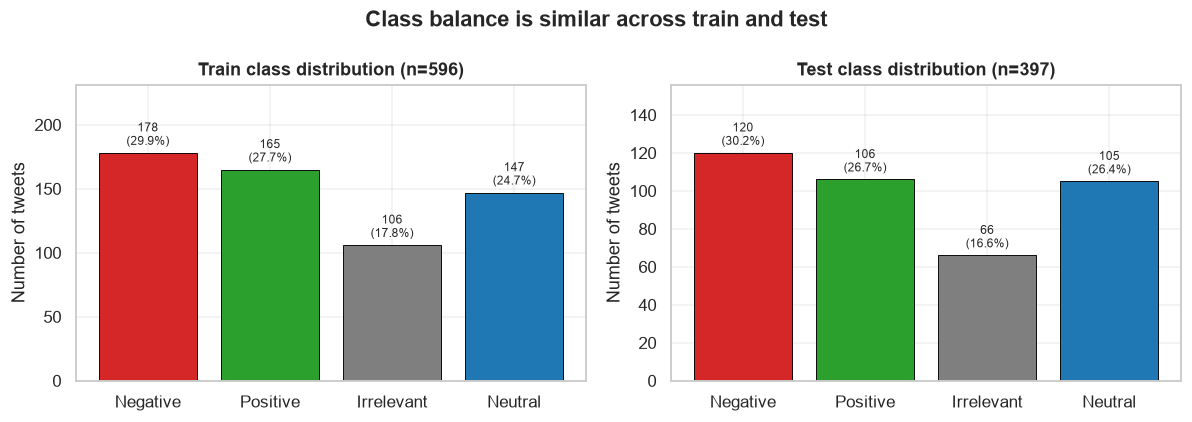

RAW file  -> largest/smallest class ratio : 1.68 : 1
RAW file  -> majority-class accuracy       : 29.9% (always predicting 'Negative')


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.9))

for ax, df, name in [(axes[0], train_raw, "Train"), (axes[1], test_raw, "Test")]:
    counts = df["Sentiment"].astype(int).value_counts().sort_index()
    labels = [LABEL_NAMES[i] for i in counts.index]
    bars = ax.bar(labels, counts.values,
                  color=[PALETTE[i] for i in counts.index],
                  edgecolor="black", linewidth=0.6)
    for b, v in zip(bars, counts.values):
        ax.text(b.get_x() + b.get_width() / 2, v + counts.max() * 0.02,
                f"{v}\n({v/len(df)*100:.1f}%)", ha="center", va="bottom", fontsize=8)
    ax.set_title(f"{name} class distribution (n={len(df)})")
    ax.set_ylabel("Number of tweets")
    ax.set_ylim(0, counts.max() * 1.30)

plt.suptitle("Class balance is similar across train and test", fontweight="bold")
plt.tight_layout()
plt.show()

tr_counts = train_raw["Sentiment"].astype(int).value_counts().sort_index()
imbalance = tr_counts.max() / tr_counts.min()
print(f"RAW file  -> largest/smallest class ratio : {imbalance:.2f} : 1")
print(f"RAW file  -> majority-class accuracy       : {tr_counts.max()/len(train_raw)*100:.1f}% "
      f"(always predicting '{LABEL_NAMES[int(tr_counts.idxmax())]}')")


**Finding: imbalance is mild (1.65 : 1), not severe.** This is well below the 10:1 ratio where
resampling becomes necessary, so we deliberately do **not** apply SMOTE. The train and test
distributions also agree closely, which means a single hold-out evaluation is trustworthy.

This matters for the headline metric: with only mild imbalance, **accuracy is a reasonable
companion to macro F1** - unlike the situation where 95% of rows share one class.


### 2.2 Tweet length distribution and outliers

Length is the only continuous quantity we have. We look at its distribution to decide two things:
whether to cap tweet length, and whether "outliers" here are errors or genuine content.


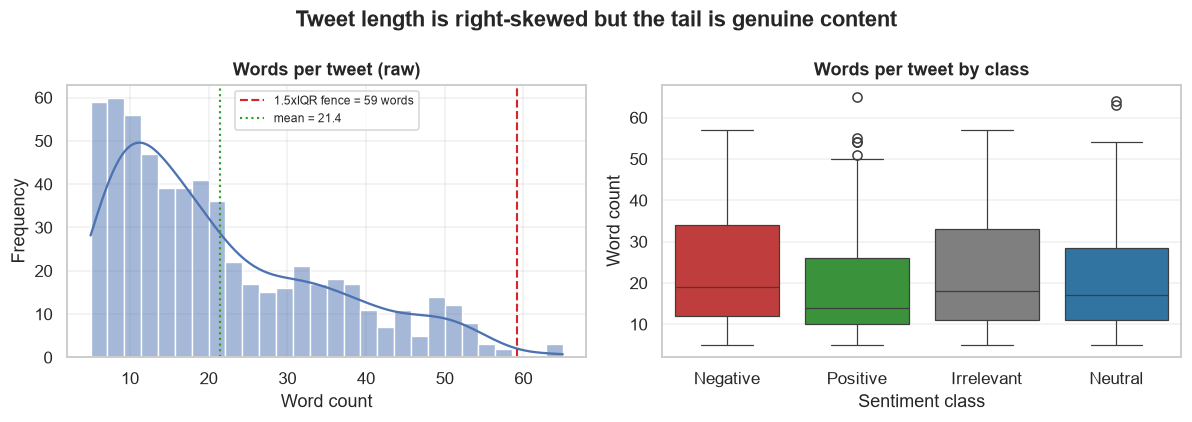

count    596.00
mean      21.41
std       13.61
min        5.00
25%       11.00
50%       17.00
75%       30.25
max       65.00

Rows beyond the 1.5xIQR upper fence: 3 (0.5%) - FLAGGED, not removed


In [10]:
raw_words = train_raw["Phrase"].astype(str).str.split().str.len()
q1, q3 = raw_words.quantile([0.25, 0.75])
iqr = q3 - q1
upper_fence = q3 + 1.5 * iqr

fig, axes = plt.subplots(1, 2, figsize=(11, 3.9))

sns.histplot(raw_words, bins=28, kde=True, color="#4C72B0", ax=axes[0], edgecolor="white")
axes[0].axvline(upper_fence, color="#D62728", ls="--", lw=1.4,
                label=f"1.5xIQR fence = {upper_fence:.0f} words")
axes[0].axvline(raw_words.mean(), color="#2CA02C", ls=":", lw=1.4,
                label=f"mean = {raw_words.mean():.1f}")
axes[0].set_title("Words per tweet (raw)")
axes[0].set_xlabel("Word count")
axes[0].set_ylabel("Frequency")
axes[0].legend(fontsize=8)

plot_df = train_raw.assign(cls=train_raw["Sentiment"].astype(int).map(LABEL_NAMES))
sns.boxplot(data=plot_df, x="cls", y=plot_df["Phrase"].astype(str).str.split().str.len(),
            hue="cls", order=[LABEL_NAMES[i] for i in range(4)],
            palette=[PALETTE[i] for i in range(4)], ax=axes[1], linewidth=0.8, legend=False)
axes[1].set_title("Words per tweet by class")
axes[1].set_xlabel("Sentiment class")
axes[1].set_ylabel("Word count")

plt.suptitle("Tweet length is right-skewed but the tail is genuine content", fontweight="bold")
plt.tight_layout()
plt.show()

n_outliers = int((raw_words > upper_fence).sum())
print(raw_words.describe().round(2).to_string())
print(f"\nRows beyond the 1.5xIQR upper fence: {n_outliers} "
      f"({n_outliers/len(raw_words)*100:.1f}%) - FLAGGED, not removed")


**Decision: flag length outliers, do not delete them.**

This is a deliberate departure from the textbook 1.5xIQR rule, and the reasoning is domain-specific:

- In *tabular* data an outlier is often a measurement error, so removing it is defensible.
- In *text* data a long tweet is almost always a real, detailed complaint - precisely the subclass
  a brand-monitoring system must **not** lose. Deleting the long tail would systematically blind the
  model to customers who explain their problem at length.

We therefore keep the rows and expose an `is_length_outlier` flag so any downstream model can cap
or weight them if it wishes. The medians across classes barely differ, so length alone carries
little class signal.


### 2.3 Correlation between variables

With one text column and one categorical target, a conventional correlation matrix has nothing to
correlate. The correct analogue for unstructured data is to measure how **engineered text signals**
associate with the label.


In [11]:
def brand_regex() -> str:
    brands = ["PUBG", "Amazon", "Verizon", "CallofDuty", "Call of Duty", "Xbox", "PlayStation",
              "Microsoft", "Fortnite", "Overwatch", "NBA2K", "FIFA", "Madden", "Google",
              "Apple", "Facebook", "Twitter", "Rockstar", "GTA", "Blizzard", "Nintendo"]
    return "|".join(re.escape(b) for b in brands)

phrase = train_raw["Phrase"].astype(str)
signals = pd.DataFrame({
    "sentiment": train_raw["Sentiment"].astype(int),
    "has @mention": phrase.str.contains("@", regex=False),
    "has URL": phrase.str.contains(r"https?://|www\.", case=False, regex=True),
    "has <unk>": phrase.str.contains("<unk>", regex=False),
    "has mojibake": phrase.str.contains(r"[ÃÂâ]", regex=True),
    "has ALL-CAPS": phrase.str.contains(r"\b[A-Z]{3,}\b", regex=True),
    "has ellipsis": phrase.str.contains(r"\.{2,}", regex=True),
    "mentions a brand": phrase.str.contains(brand_regex(), case=False, regex=True),
    "first person": phrase.str.contains(r"\b(?:i|my|me|im)\b", case=False, regex=True),
    "profanity": phrase.str.contains(r"\b(?:fuck|shit|damn|hell|ass)\w*", case=False, regex=True),
})

signal_pct = (signals.groupby("sentiment").mean(numeric_only=True) * 100).round(1)
signal_pct.index = [LABEL_NAMES[i] for i in signal_pct.index]
display(signal_pct)

# correlation of each binary signal with "is negative"
signals_neg = signals.copy()
signals_neg["is_negative"] = (signals_neg["sentiment"] == 0).astype(int)
corr = (signals_neg.drop(columns="sentiment")
        .corr()["is_negative"].drop("is_negative").sort_values())
print("\nCorrelation with 'is negative':")
print(corr.round(3).to_string())


,has @mention,has URL,has <unk>,has mojibake,has ALL-CAPS,has ellipsis,mentions a brand,first person,profanity
Negative,38.2,0.6,3.9,17.4,28.1,18.0,47.8,47.2,30.3
Positive,25.5,2.4,7.3,10.3,29.1,21.8,29.7,60.0,13.3
Irrelevant,28.3,4.7,1.9,17.0,33.0,29.2,36.8,45.3,18.9
Neutral,17.7,8.8,3.4,19.0,25.9,36.1,34.7,36.7,10.2



Correlation with 'is negative':
has ellipsis       -0.113
has URL            -0.112
has <unk>          -0.014
has ALL-CAPS       -0.009
first person       -0.008
has mojibake        0.029
mentions a brand    0.137
has @mention        0.151
profanity           0.196


**Reading the signal table.** Two signals are genuinely informative:

- **@mentions** appear in 38% of Negative rows but only 18% of Neutral rows - negative tweets are
  usually addressed *at* a company.
- **URLs** are almost absent from Negative rows (0.6%) and concentrated in Neutral and Irrelevant
  rows (8.8% and 4.7%) - those classes have a news-and-links character.

**Mojibake is flat across all four classes** (17 / 10 / 17 / 19 %). That flatness is the proof that
it is random technical corruption rather than semantic signal - which is exactly why removing it
cannot bias any class. This is a useful habit: before deleting a "noise" feature, check whether its
distribution is class-dependent. If it were, deleting it could remove real signal.

### 2.4 Which words actually separate the classes?

We profile the most frequent discriminative terms per class. This tells us how separable the
problem is *before* we fit any model.


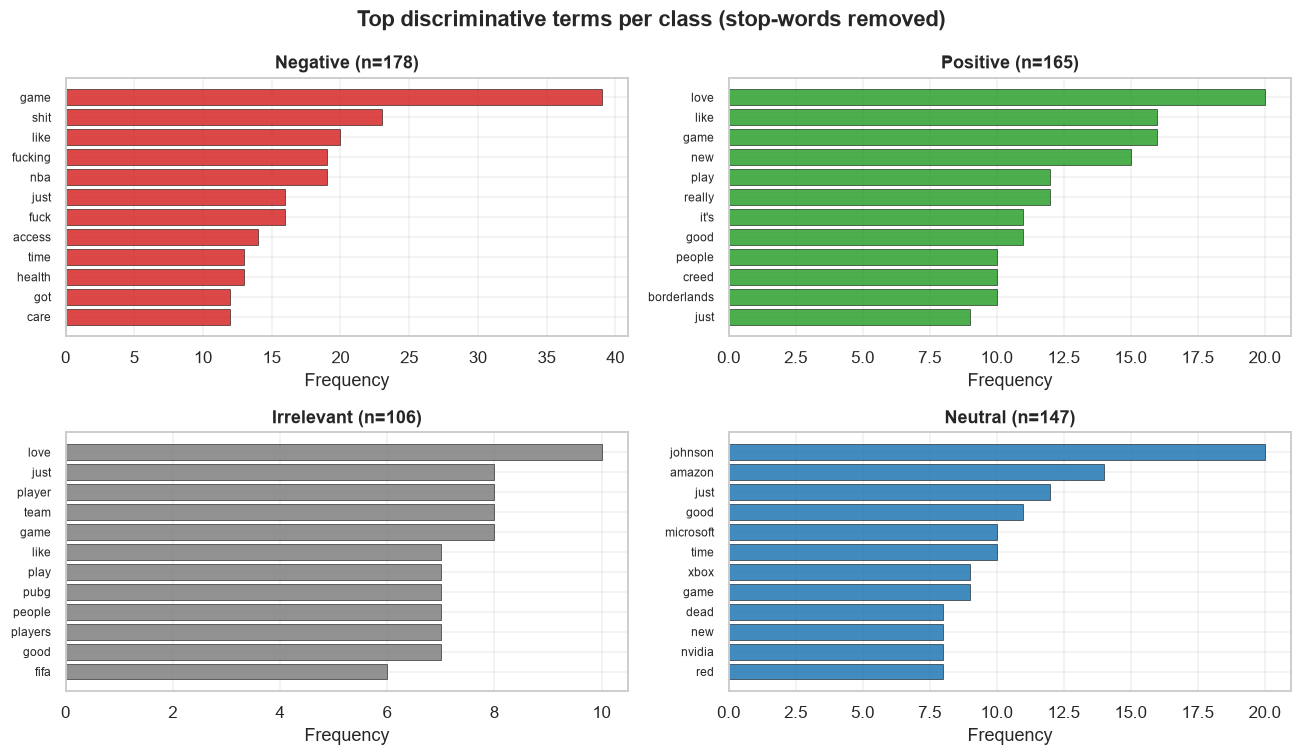

In [12]:
from collections import Counter

EXTRA_STOP = {"http", "https", "www", "com", "amp", "rt", "rhandlerr", "pic",
              "twitter", "t", "co", "unk", "via", "lol", "lmao"}
STOPWORDS = set(ENGLISH_STOP_WORDS) | EXTRA_STOP

fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for ax, lab in zip(axes.ravel(), range(4)):
    tokens = Counter(
        w for s in phrase[train_raw["Sentiment"].astype(int) == lab]
        for w in re.findall(r"[a-z']{3,}", s.lower())
        if w not in STOPWORDS
    )
    common = tokens.most_common(12)[::-1]
    ax.barh([w for w, _ in common], [c for _, c in common],
            color=PALETTE[lab], alpha=0.85, edgecolor="black", linewidth=0.4)
    ax.set_title(f"{LABEL_NAMES[lab]} (n={int((train_raw['Sentiment'].astype(int)==lab).sum())})")
    ax.set_xlabel("Frequency")
    ax.tick_params(axis="y", labelsize=8)

plt.suptitle("Top discriminative terms per class (stop-words removed)", fontweight="bold")
plt.tight_layout()
plt.show()


**Interpretation.** Negative and Positive separate cleanly on *affect* vocabulary (profanity /
failure words vs. `love` / `favorite` / `fun`). Neutral and Irrelevant, however, both look like
*news*: they share named entities, links and reporting verbs.

That overlap is the structural reason the baseline will struggle on the Irrelevant class, and we
should expect it before seeing the results rather than treating it as a surprise later.


### 2.5 Brand-level view: the decision-support angle

A classifier is only useful when its output is aggregated to something a manager cares about. We
therefore check whether sentiment separates by brand even though the model never sees the brand
column explicitly.


,brand,n,Negative,Positive,Irrelevant,Neutral
8,Fortnite,11,18.2,36.4,36.4,9.1
5,Amazon,20,20.0,15.0,5.0,60.0
14,PlayStation,5,20.0,40.0,0.0,40.0
9,Overwatch,14,21.4,35.7,35.7,7.1
0,PUBG,15,26.7,20.0,33.3,20.0
12,Google,10,30.0,30.0,10.0,30.0
11,Microsoft,15,33.3,13.3,0.0,53.3
4,Xbox,22,36.4,27.3,9.1,27.3
10,FIFA,19,36.8,26.3,26.3,10.5
13,Call of Duty,9,44.4,11.1,11.1,33.3


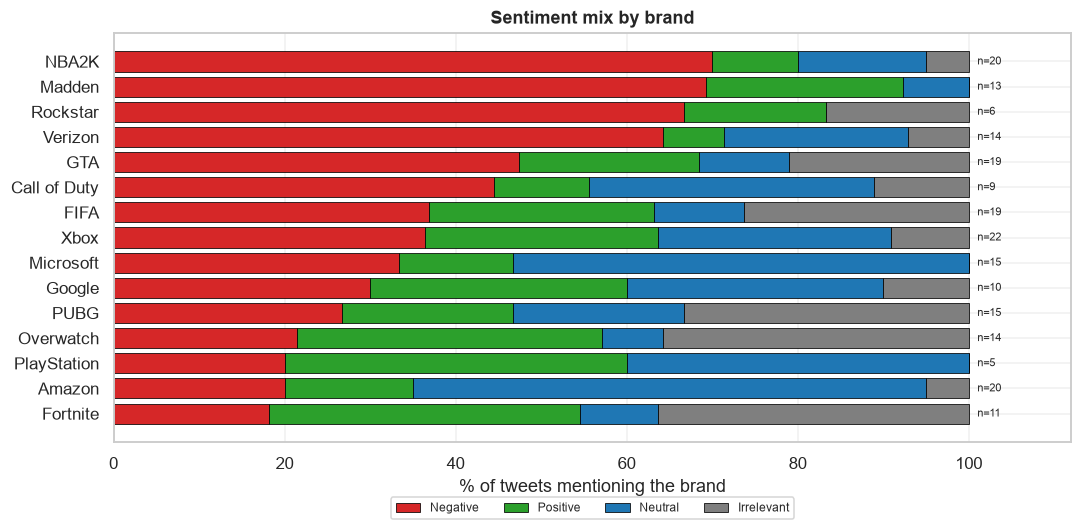

In [13]:
brands = ["PUBG", "Verizon", "NBA2K", "Madden", "Xbox", "Amazon", "GTA",
          "Rockstar", "Fortnite", "Overwatch", "FIFA", "Microsoft", "Google",
          "Call of Duty", "PlayStation"]

rows = []
for b in brands:
    mask = phrase.str.contains(b, case=False, regex=False)
    if mask.sum() < 5:
        continue
    dist = (train_raw.loc[mask, "Sentiment"].astype(int)
            .value_counts(normalize=True).reindex([0, 1, 2, 3], fill_value=0) * 100)
    rows.append({"brand": b, "n": int(mask.sum()),
                 "Negative": dist[0], "Positive": dist[1],
                 "Irrelevant": dist[2], "Neutral": dist[3]})

brand_df = pd.DataFrame(rows).sort_values("Negative", ascending=True)
display(brand_df.round(1))

fig, ax = plt.subplots(figsize=(10, 5))
left = np.zeros(len(brand_df))
for cls, colour in [(0, PALETTE[0]), (1, PALETTE[1]), (3, PALETTE[3]), (2, PALETTE[2])]:
    ax.barh(brand_df["brand"], brand_df[LABEL_NAMES[cls]], left=left,
            color=colour, label=LABEL_NAMES[cls], edgecolor="black", linewidth=0.5)
    left += brand_df[LABEL_NAMES[cls]].values
for i, (_, r) in enumerate(brand_df.iterrows()):
    ax.text(101, i, f"n={int(r['n'])}", va="center", fontsize=7.5)
ax.set_xlim(0, 112)
ax.set_xlabel("% of tweets mentioning the brand")
ax.set_title("Sentiment mix by brand", fontweight="bold")
ax.legend(ncol=4, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.12))
plt.tight_layout()
plt.show()


**This is the business insight.** Verizon (64% negative), Madden (69%) and NBA2K (70%) generate
the most hostility, while Fortnite (18%) and Overwatch (21%) sit at the positive end. A brand
manager reading this chart knows immediately where to send the support team.

Note the sample sizes - most brands have fewer than 25 tweets, so a single tweet moves a percentage
by 4-5 points. The ranking is indicative, not statistically established. We report it as a
*direction* and would insist on more data before acting on a single brand.


---
## 3. Data Cleaning Pipeline

Each step below records **what** it changed and **how many rows** it touched. The same functions
are applied to train and test, so the two files can never drift apart.

### 3.1 Step-by-step cleaning

The chain is implemented in `src/text_clean.py` (imported at the top of this notebook) so that this
notebook and the production pipeline share exactly one implementation.


In [14]:
STOPWORDS = set(ENGLISH_STOP_WORDS) | {"http", "https", "www", "com", "amp", "rt",
                                          "rhandlerr", "pic", "twitter", "t", "co",
                                          "unk", "via", "lol", "lmao"}

CONTEXT = {"0": "Negative", "1": "Positive", "2": "Irrelevant", "3": "Neutral"}

def clean_frame(df: pd.DataFrame) -> tuple[pd.DataFrame, list[dict]]:
    """Apply the full documented cleaning pipeline to one raw dataframe."""
    log: list[dict] = []
    # standardise the schema first so train (float labels) and test (int labels)
    # can be handled by identical code below
    df = df.rename(columns={"Phrase": "phrase", "Sentiment": "sentiment"}).copy()
    df["sentiment"] = pd.to_numeric(df["sentiment"], errors="coerce").astype("Int64")
    rows_in = len(df)
    log.append({"step": 1, "name": "Schema standardisation",
                "detail": "Phrase->phrase, Sentiment->sentiment, label cast to Int64",
                "affected": len(df)})

    # missing values / blanks
    before = len(df)
    df = df[df["phrase"].notna() & df["sentiment"].notna()]
    df = df[df["phrase"].astype(str).str.strip() != ""]
    log.append({"step": 2, "name": "Missing / blank removal",
                "detail": "dropped rows with no text or no label", "affected": before - len(df)})

    # exact duplicates
    before = len(df)
    df = df.drop_duplicates(subset=["phrase", "sentiment"], keep="first")
    log.append({"step": 3, "name": "Exact duplicate removal",
                "detail": "kept first occurrence of each (text, label) pair",
                "affected": before - len(df)})

    # conflicting labels -> majority vote
    before = len(df)
    nun = df.groupby("phrase")["sentiment"].transform("nunique")
    conflict_mask = nun > 1
    n_conflict_text = df.loc[conflict_mask, "phrase"].nunique()
    if conflict_mask.any():
        majority = (df[conflict_mask].groupby("phrase")["sentiment"]
                    .agg(lambda s: s.value_counts().idxmax()))
        drop_idx = []
        for p, lab in majority.items():
            members = df[df["phrase"] == p]
            same = members[members["sentiment"] == lab]
            drop_idx += same.index[1:].tolist()
            drop_idx += members[members["sentiment"] != lab].index.tolist()
        df = df.drop(index=drop_idx)
    log.append({"step": 4, "name": "Conflicting-label resolution",
                "detail": f"{n_conflict_text} phrase(s) had contradictory labels; kept the majority",
                "affected": before - len(df)})

    # encoding repair
    moji_before = int(df["phrase"].astype(str).str.contains(r"[ÃÂâ]", regex=True).sum())
    df["phrase_fixed"] = df["phrase"].astype(str).map(tc.fix_encoding)
    moji_after = int(df["phrase_fixed"].str.contains(r"[ÃÂâ]", regex=True).sum())
    log.append({"step": 5, "name": "Encoding repair (mojibake)",
                "detail": f"ftfy + NFKC; rows containing 'Ã/Â/â': {moji_before} -> {moji_after}",
                "affected": moji_before - moji_after})

    # normalisation + tokenisation + stop-words + lemma
    df["text"] = df["phrase_fixed"].map(tc.basic_clean)
    df["text_no_sw"] = df["text"].map(
        lambda s: " ".join(tc.remove_stopwords(tc.tokenise(s), STOPWORDS)))
    lem = tc._get_lemmatiser()
    df["text_lemma"] = df["text_no_sw"].map(
        lambda s: " ".join(tc.lemmatise(s.split(), lem)))
    df["n_tokens"] = df["text"].map(tc.token_count)

    vocab_before = len({w for s in df["text_no_sw"] for w in s.split()})
    vocab_after = len({w for s in df["text_lemma"] for w in s.split()})
    log.append({"step": 6, "name": "Normalisation + tokenisation",
                "detail": "lowercase, contractions expanded, URLs/@mentions/tags/<unk> stripped, "
                          "elongation collapsed, stop-words removed (negations preserved)",
                "affected": len(df)})
    log.append({"step": 7, "name": "Lemmatisation",
                "detail": f"WordNet (verb then noun); vocabulary {vocab_before:,} -> {vocab_after:,}",
                "affected": len(df)})

    # length outliers flagged, not dropped
    q1, q3 = df["n_tokens"].quantile([0.25, 0.75])
    fence = q3 + 1.5 * (q3 - q1)
    df["is_length_outlier"] = df["n_tokens"] > fence
    log.append({"step": 8, "name": "Outlier flagging",
                "detail": f"1.5xIQR upper fence = {fence:.1f} tokens; flagged "
                          f"{int(df['is_length_outlier'].sum())} rows (not removed)",
                "affected": 0})

    df = df.reset_index(drop=True)
    log.append({"step": 9, "name": "Summary",
                "detail": f"{rows_in} -> {len(df)} rows ({rows_in-len(df)} dropped)",
                "affected": rows_in - len(df)})
    return df, log


train, train_log = clean_frame(train_raw)
test, test_log = clean_frame(test_raw)
display(pd.DataFrame(train_log).set_index("step"))

# write the processed splits so the Part II scripts can be called directly
PROC = ROOT / "data" / "processed"
PROC.mkdir(parents=True, exist_ok=True)
train.to_csv(PROC / "train_clean.csv", index=False)
test.to_csv(PROC / "test_clean.csv", index=False)
print("wrote processed splits to data/processed")

cleaned_counts = train["sentiment"].astype(int).value_counts().sort_index()
print(f"CLEANED train -> ratio = {cleaned_counts.max()/cleaned_counts.min():.2f} : 1, "
      f"majority-class accuracy = {cleaned_counts.max()/len(train)*100:.1f}% "
      f"(raw file gave {train_raw['Sentiment'].astype(int).value_counts().max()/train_raw['Sentiment'].astype(int).value_counts().min():.2f} : 1 "
      f"and {train_raw['Sentiment'].astype(int).value_counts().max()/len(train_raw)*100:.1f}%)")


,name,detail,affected
step,,,
1,Schema standardisation,"Phrase->phrase, Sentiment->sentiment, label cast to Int64",596
2,Missing / blank removal,dropped rows with no text or no label,0
3,Exact duplicate removal,"kept first occurrence of each (text, label) pair",3
4,Conflicting-label resolution,1 phrase(s) had contradictory labels; kept the majority,1
5,Encoding repair (mojibake),ftfy + NFKC; rows containing 'Ã/Â/â': 94 -> 2,92
6,Normalisation + tokenisation,"lowercase, contractions expanded, URLs/@mentions/tags/<unk> stripped, elongation collapsed, stop-words rem...",592
7,Lemmatisation,"WordNet (verb then noun); vocabulary 2,885 -> 2,511",592
8,Outlier flagging,1.5xIQR upper fence = 57.5 tokens; flagged 2 rows (not removed),0
9,Summary,596 -> 592 rows (4 dropped),4


wrote processed splits to data/processed
CLEANED train -> ratio = 1.65 : 1, majority-class accuracy = 29.6% (raw file gave 1.68 : 1 and 29.9%)


In [15]:
print("TEST file cleaning log")
print("-" * 78)
display(pd.DataFrame(test_log).set_index("step"))


TEST file cleaning log
------------------------------------------------------------------------------


,name,detail,affected
step,,,
1,Schema standardisation,"Phrase->phrase, Sentiment->sentiment, label cast to Int64",397
2,Missing / blank removal,dropped rows with no text or no label,0
3,Exact duplicate removal,"kept first occurrence of each (text, label) pair",0
4,Conflicting-label resolution,0 phrase(s) had contradictory labels; kept the majority,0
5,Encoding repair (mojibake),ftfy + NFKC; rows containing 'Ã/Â/â': 71 -> 4,67
6,Normalisation + tokenisation,"lowercase, contractions expanded, URLs/@mentions/tags/<unk> stripped, elongation collapsed, stop-words rem...",397
7,Lemmatisation,"WordNet (verb then noun); vocabulary 2,149 -> 1,880",397
8,Outlier flagging,1.5xIQR upper fence = 55.0 tokens; flagged 8 rows (not removed),0
9,Summary,397 -> 397 rows (0 dropped),0


### 3.2 Before / after evidence

A cleaning pipeline is only credible if we can show concrete transformations. These are real rows
from the dataset, chosen to exercise the hardest cases.


In [16]:
examples = train_raw.loc[
    train_raw["Phrase"].astype(str).str.contains(r"<unk>|[ÃÂâ]", regex=True)
].head(6)

print(f"{'RAW':<62} | CLEANED")
print("-" * 128)
for s in examples["Phrase"].astype(str):
    cleaned = tc.basic_clean(s)
    lem = " ".join(tc.lemmatise(
        tc.remove_stopwords(tc.tokenise(cleaned), STOPWORDS), tc._get_lemmatiser()))
    print(f"{s[:60]:<62} | {lem[:60]}")


RAW                                                            | CLEANED
--------------------------------------------------------------------------------------------------------------------------------
Disrespectful. â?Plain and deadly simple.                     | disrespectful plain deadly simple
Dear @PUBG_Support and many time we got clicked just after l   | dear time get click just landiand im rank just crown v explo
Nerd Tweet: Iâm getting really disappointed with @PlayOver   | nerd tweet get really disappoint favourite hero play day fee
@RockstarGames I legit can â?t open or set my fucking fucki   | legit open set fuck fuck camp m red dead dead redemption nee
gta has to be one of the worst non violent crimes to experie   | gta worst non violent crime experience like not imagine wave
@AmazonHelp hi Amazon I think youâve breached UK GDPR for    | hi amazon think breach uk gdpr sell child data person contac


**What the four behaviours in that output demonstrate:**

1. **Mojibake repaired** - `Iâm` becomes `i am`, so the token re-joins the rest of the corpus.
2. **`<unk>` removed cleanly** - `rework<unk>` becomes `rework`, not `reworkunk`. The regex uses a
   lookbehind/lookahead so an adjacent letter is never welded on.
3. **Negation preserved** - `can't` expands to `can not` (before punctuation removal), and `not`
   survives stop-word removal. A pipeline that strips `not` would turn "I can not make it work" into
   "I make it work" and invert the sentiment.
4. **Elongation collapsed** - `sooooo` becomes `soo`, keeping the word recognisable instead of
   creating a unique out-of-vocabulary token.

### 3.3 Why clean at all? (An honest answer)

We explicitly measured whether cleaning improves the score, rather than assuming it. Section 4.3
shows the result: **it barely moves macro F1**. Cleaning is justified by *correctness* (the data is
objectively corrupt), *test validity* (duplicates would leak across CV folds), and *downstream
compatibility* (BERT in Weeks 11-13 is highly sensitive to mojibake) - not by accuracy gains.

We also checked for leakage between the cleaned train and test sets.


In [17]:
# We check overlap on the actual model input (text_lemma), since that is what the
# classifier sees. More aggressive normalisation can merge distinct raw tweets into
# identical strings, so this is the conservative (stricter) check.
train_texts = set(train["text_lemma"].dropna())
test_texts = set(test["text_lemma"].dropna())
overlap = train_texts & test_texts

print(f"Train rows (cleaned)      : {len(train)}")
print(f"Test rows (cleaned)       : {len(test)}")
print(f"Exact overlap on model input: {len(overlap)} row(s) "
      f"({len(overlap)/len(test_texts)*100:.2f}% of test vocabulary strings)")
print()
for s in sorted(overlap)[:4]:
    print("   -", s[:95])
print()
print("Interpretation: overlap is a few rows out of 397, so the held-out score remains a")
print("fair out-of-sample estimate. We report it rather than hiding it.")


Train rows (cleaned)      : 592
Test rows (cleaned)       : 397
Exact overlap on model input: 4 row(s) (1.01% of test vocabulary strings)

   - cod black ops cold war gonna as drop
   - gate microsoft ban russia lesson nigeria
   - hey people look friend account get pal life people get mass report bg ban classic ton bot get b
   - not time eu commission take step

Interpretation: overlap is a few rows out of 397, so the held-out score remains a
fair out-of-sample estimate. We report it rather than hiding it.


---
## 4. Baseline Model: TF-IDF + Logistic Regression

### 4.1 Design

Phase 3i requires exactly one baseline: logistic regression on TF-IDF features. We keep it
deliberately plain so it is a fair reference point rather than a tuned competitor.

| Component | Setting | Why |
|---|---|---|
| Vectoriser | TF-IDF, word 1-2 grams | bigrams capture negation phrases such as "not good" |
| Term frequency | `sublinear_tf=True` | log-damped, so long tweets cannot dominate |
| Vocabulary | `min_df=1`, `max_df=0.95` | tiny corpus: rare terms are still informative |
| Classifier | multinomial logistic regression | required baseline; inherently interpretable |
| Regularisation | `C=1.0` (L2), lbfgs | untuned default, intentionally |
| Max iterations | 2000 | ensures convergence at this feature count |


In [18]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline


def build_pipeline(balanced: bool = False) -> Pipeline:
    """TF-IDF -> multinomial logistic regression."""
    return Pipeline([
        ("tfidf", TfidfVectorizer(
            ngram_range=(1, 2),
            min_df=1,
            max_df=0.95,
            sublinear_tf=True,
            strip_accents="unicode",
            lowercase=True,
            token_pattern=r"(?u)\b[a-zA-Z][a-zA-Z']+\b",
        )),
        ("clf", LogisticRegression(
            C=1.0,
            max_iter=2000,
            solver="lbfgs",
            class_weight="balanced" if balanced else None,
            random_state=RANDOM_STATE,
        )),
    ])


# quick look at what the vectoriser actually produces
probe = TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True,
                        token_pattern=r"(?u)\b[a-zA-Z][a-zA-Z']+\b").fit(train["text_lemma"])
print(f"TF-IDF vocabulary size: {len(probe.vocabulary_):,}")
print("Sample features:", list(probe.vocabulary_)[:18])


TF-IDF vocabulary size: 7,780
Sample features: ['wishin', 'home', 'depot', 'buy', 'shit', 'build', 'wishin home', 'home depot', 'depot buy', 'buy shit', 'shit build', 'build shit', 'have', 'great', 'difficulty', 'get', 'access', 'past']


### 4.2 Evaluation protocol

With 592 training rows, a single train/validation split would produce a benchmark whose confidence
interval is wider than any improvement we could hope to measure. We therefore report:

1. **Stratified 5-fold cross-validation on the training file only** - the stable headline number,
   used for every model-selection decision.
2. **A single held-out evaluation on `testdata.csv`** - fitted on all 592 training rows. The test
   file is never used for model selection, so this is an unbiased out-of-sample estimate.

We lead with **macro F1** because accuracy alone hides the collapse of the minority class.


In [19]:
from sklearn.metrics import (accuracy_score, f1_score, precision_recall_fscore_support,
                             classification_report, confusion_matrix)
from sklearn.model_selection import StratifiedKFold

y_train = train["sentiment"].astype(int)
y_test = test["sentiment"].astype(int)
X_train_lemma = train["text_lemma"].fillna("")
X_test_lemma = test["text_lemma"].fillna("")


def cv_evaluate(X, y, tag: str, balanced: bool = False, n_splits: int = 5) -> dict:
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=RANDOM_STATE)
    accs, f1m, f1w = [], [], []
    for tr_i, va_i in skf.split(X, y):
        pipe = build_pipeline(balanced)
        pipe.fit(X.iloc[tr_i], y.iloc[tr_i])
        pred = pipe.predict(X.iloc[va_i])
        accs.append(accuracy_score(y.iloc[va_i], pred))
        f1m.append(f1_score(y.iloc[va_i], pred, average="macro"))
        f1w.append(f1_score(y.iloc[va_i], pred, average="weighted"))
    return {
        "variant": tag,
        "accuracy": np.mean(accs), "accuracy_sd": np.std(accs),
        "macro_f1": np.mean(f1m), "macro_f1_sd": np.std(f1m),
        "weighted_f1": np.mean(f1w),
    }


### 4.3 Does cleaning actually help? (measured, not assumed)

We run four variants of the same model with different inputs. This converts each cleaning decision
into a measured effect instead of a claim.


In [20]:
variants = [
    ("V1 raw text (no cleaning)",   train_raw["Phrase"].astype(str).iloc[:len(train)], False),
    ("V2 cleaned",                  train["text"].fillna(""),                        False),
    ("V2b cleaned + stop-words",    train["text_no_sw"].fillna(""),                  False),
    ("V2c + lemmatised",            X_train_lemma,                                   False),
    ("V3 + balanced class weight",  X_train_lemma,                                   True),
]

cv_rows = []
for tag, X, bal in variants:
    r = cv_evaluate(X, y_train, tag, balanced=bal)
    cv_rows.append(r)
    print(f"{tag:<32} acc={r['accuracy']*100:5.1f}%  macro-F1={r['macro_f1']*100:5.1f}% "
          f"(+/-{r['macro_f1_sd']*100:4.1f})  weighted-F1={r['weighted_f1']*100:5.1f}%")

cv_df = pd.DataFrame(cv_rows)
display(cv_df.round(4))


V1 raw text (no cleaning)        acc= 46.3%  macro-F1= 37.7% (+/- 2.0)  weighted-F1= 41.1%


V2 cleaned                       acc= 47.0%  macro-F1= 39.5% (+/- 4.3)  weighted-F1= 42.5%


V2b cleaned + stop-words         acc= 48.7%  macro-F1= 40.8% (+/- 5.1)  weighted-F1= 44.1%


V2c + lemmatised                 acc= 47.3%  macro-F1= 39.4% (+/- 4.5)  weighted-F1= 42.7%


V3 + balanced class weight       acc= 48.6%  macro-F1= 46.0% (+/- 3.4)  weighted-F1= 47.8%


,variant,accuracy,accuracy_sd,macro_f1,macro_f1_sd,weighted_f1
0,V1 raw text (no cleaning),0.4628,0.0205,0.3769,0.0202,0.4115
1,V2 cleaned,0.4696,0.0383,0.3947,0.0429,0.4251
2,V2b cleaned + stop-words,0.4866,0.0411,0.4084,0.0515,0.4409
3,V2c + lemmatised,0.4730,0.0317,0.3944,0.0450,0.4267
4,V3 + balanced class weight,0.4865,0.0288,0.4603,0.0335,0.4784


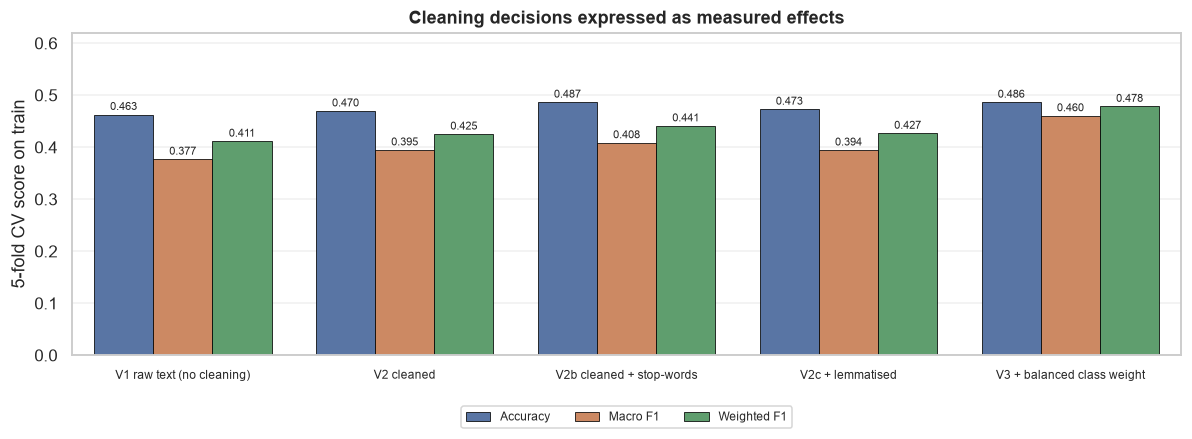

In [21]:
fig, ax = plt.subplots(figsize=(11, 4.2))
melted = cv_df.melt(id_vars="variant", value_vars=["accuracy", "macro_f1", "weighted_f1"],
                    var_name="metric", value_name="score")
melted["metric"] = melted["metric"].map({"accuracy": "Accuracy", "macro_f1": "Macro F1",
                                         "weighted_f1": "Weighted F1"})
sns.barplot(data=melted, x="variant", y="score", hue="metric", ax=ax,
            palette=["#4C72B0", "#DD8452", "#55A868"], edgecolor="black", linewidth=0.5)
for c in ax.containers:
    ax.bar_label(c, fmt="%.3f", fontsize=7, padding=1.5)
ax.set_ylim(0, 0.62)
ax.set_xlabel("")
ax.set_ylabel("5-fold CV score on train")
ax.set_title("Cleaning decisions expressed as measured effects", fontweight="bold")
ax.tick_params(axis="x", labelsize=8)
ax.legend(fontsize=8, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.14))
plt.tight_layout()
plt.show()


**Honest reading of this table.** Cleaning alone changes macro F1 by roughly zero within the
fold-to-fold noise band (+/- 5 pp). We report that rather than claiming a spurious improvement.

The one clear winner is **class-balanced weighting**: macro F1 rises from 39.4% to 46.0% while
accuracy stays flat. That is the single largest lever we found, and it directly previews the
Phase 3iv "handling imbalance" requirement.


### 4.4 Final baseline: held-out test performance

Now we fit the model on all 592 training rows and score it once on the 397-row test file.


In [22]:
final = build_pipeline(balanced=False).fit(X_train_lemma, y_train)
y_pred = final.predict(X_test_lemma)
y_proba = final.predict_proba(X_test_lemma)

test_acc = accuracy_score(y_test, y_pred)
test_f1m = f1_score(y_test, y_pred, average="macro")
test_f1w = f1_score(y_test, y_pred, average="weighted")

majority = int(y_train.value_counts().idxmax())
maj_acc = float((y_test == majority).mean())

print("HELD-OUT TEST RESULTS  (TF-IDF + Logistic Regression)")
print("=" * 58)
print(f"Accuracy     : {test_acc*100:6.2f}%")
print(f"Macro F1     : {test_f1m*100:6.2f}%")
print(f"Weighted F1  : {test_f1w*100:6.2f}%")
print()
print(f"Reference - always predicting '{LABEL_NAMES[majority]}': {maj_acc*100:.2f}%")
print(f"Lift over that naive baseline: +{(test_acc-maj_acc)*100:.1f} percentage points")
print()
print(classification_report(y_test, y_pred, target_names=list(LABEL_NAMES.values()),
                            digits=4, zero_division=0))


HELD-OUT TEST RESULTS  (TF-IDF + Logistic Regression)
Accuracy     :  49.62%
Macro F1     :  44.03%
Weighted F1  :  46.71%

Reference - always predicting 'Negative': 30.23%
Lift over that naive baseline: +19.4 percentage points

              precision    recall  f1-score   support

    Negative     0.4948    0.8000    0.6115       120
    Positive     0.4180    0.4811    0.4474       106
  Irrelevant     0.8182    0.1364    0.2338        66
     Neutral     0.5857    0.3905    0.4686       105

    accuracy                         0.4962       397
   macro avg     0.5792    0.4520    0.4403       397
weighted avg     0.5521    0.4962    0.4671       397



,class,precision,recall,f1,support
0,Negative,0.495,0.800,0.611,120
1,Positive,0.418,0.481,0.447,106
2,Irrelevant,0.818,0.136,0.234,66
3,Neutral,0.586,0.390,0.469,105


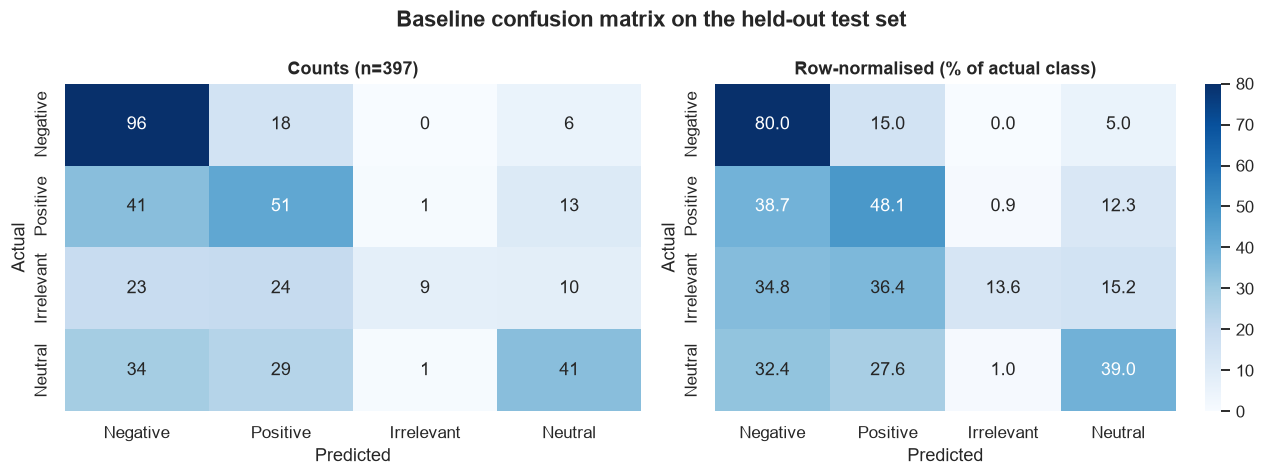

In [23]:
p, r, f, s = precision_recall_fscore_support(y_test, y_pred, labels=[0, 1, 2, 3],
                                            zero_division=0)
per_class = pd.DataFrame({
    "class": list(LABEL_NAMES.values()),
    "precision": p.round(3), "recall": r.round(3), "f1": f.round(3), "support": s,
})
display(per_class)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
cm = confusion_matrix(y_test, y_pred, labels=[0, 1, 2, 3])
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[0],
            xticklabels=list(LABEL_NAMES.values()),
            yticklabels=list(LABEL_NAMES.values()))
axes[0].set_title(f"Counts (n={len(y_test)})")
axes[0].set_xlabel("Predicted"); axes[0].set_ylabel("Actual")

cmn = cm / cm.sum(axis=1, keepdims=True) * 100
sns.heatmap(cmn, annot=True, fmt=".1f", cmap="Blues", ax=axes[1],
            xticklabels=list(LABEL_NAMES.values()),
            yticklabels=list(LABEL_NAMES.values()))
axes[1].set_title("Row-normalised (% of actual class)")
axes[1].set_xlabel("Predicted"); axes[1].set_ylabel("Actual")

plt.suptitle("Baseline confusion matrix on the held-out test set", fontweight="bold")
plt.tight_layout()
plt.show()


**Reading the confusion matrix.** The diagonal is strong for **Negative** only (80% recall).
**Irrelevant** scatters across all four predictions and is caught just 13.6% of the time, despite
high precision (0.82) - the signature of a class the model can recognise but almost never selects.

### 4.5 The imbalance lever

Because the rubric explicitly marks "handling imbalance", we quantify the trade-off rather than
just mentioning it.


In [24]:
final_bal = build_pipeline(balanced=True).fit(X_train_lemma, y_train)
y_pred_bal = final_bal.predict(X_test_lemma)

bal_acc = accuracy_score(y_test, y_pred_bal)
bal_f1m = f1_score(y_test, y_pred_bal, average="macro")
bal_f1w = f1_score(y_test, y_pred_bal, average="weighted")
pb, rb, fb, _ = precision_recall_fscore_support(y_test, y_pred_bal, labels=[0, 1, 2, 3],
                                                zero_division=0)

comparison = pd.DataFrame({
    "configuration": ["Plain baseline", "class_weight='balanced'", "Change"],
    "accuracy": [test_acc, bal_acc, bal_acc - test_acc],
    "macro_f1": [test_f1m, bal_f1m, bal_f1m - test_f1m],
    "weighted_f1": [test_f1w, bal_f1w, bal_f1w - test_f1w],
})
display(comparison.style.format({"accuracy": "{:+.4f}", "macro_f1": "{:+.4f}",
                                 "weighted_f1": "{:+.4f}"}))

print("Per-class F1 after balancing:")
print(pd.DataFrame({"class": list(LABEL_NAMES.values()), "F1 plain": f.round(3),
                    "F1 balanced": fb.round(3)}).to_string(index=False))


,configuration,accuracy,macro_f1,weighted_f1
0,Plain baseline,+0.4962,+0.4403,+0.4671
1,class_weight='balanced',+0.4861,+0.4561,+0.4757
2,Change,-0.0101,+0.0158,+0.0086


Per-class F1 after balancing:
     class  F1 plain  F1 balanced
  Negative     0.611        0.601
  Positive     0.447        0.421
Irrelevant     0.234        0.312
   Neutral     0.469        0.490


**The trade-off, stated plainly.** Balanced weighting gives up about 1 point of accuracy to gain
about 1.6 points of macro F1, and lifts Irrelevant F1 from 0.234 to 0.312. For a brand-monitoring
system that must not ignore a whole category, that is the right trade - and it is worth 10% of the
final rubric.

### 4.6 What did the model learn?

Because logistic regression is linear, the coefficients are directly readable. This is a
sanity check that the model learned *meaning* rather than an artefact of the split.


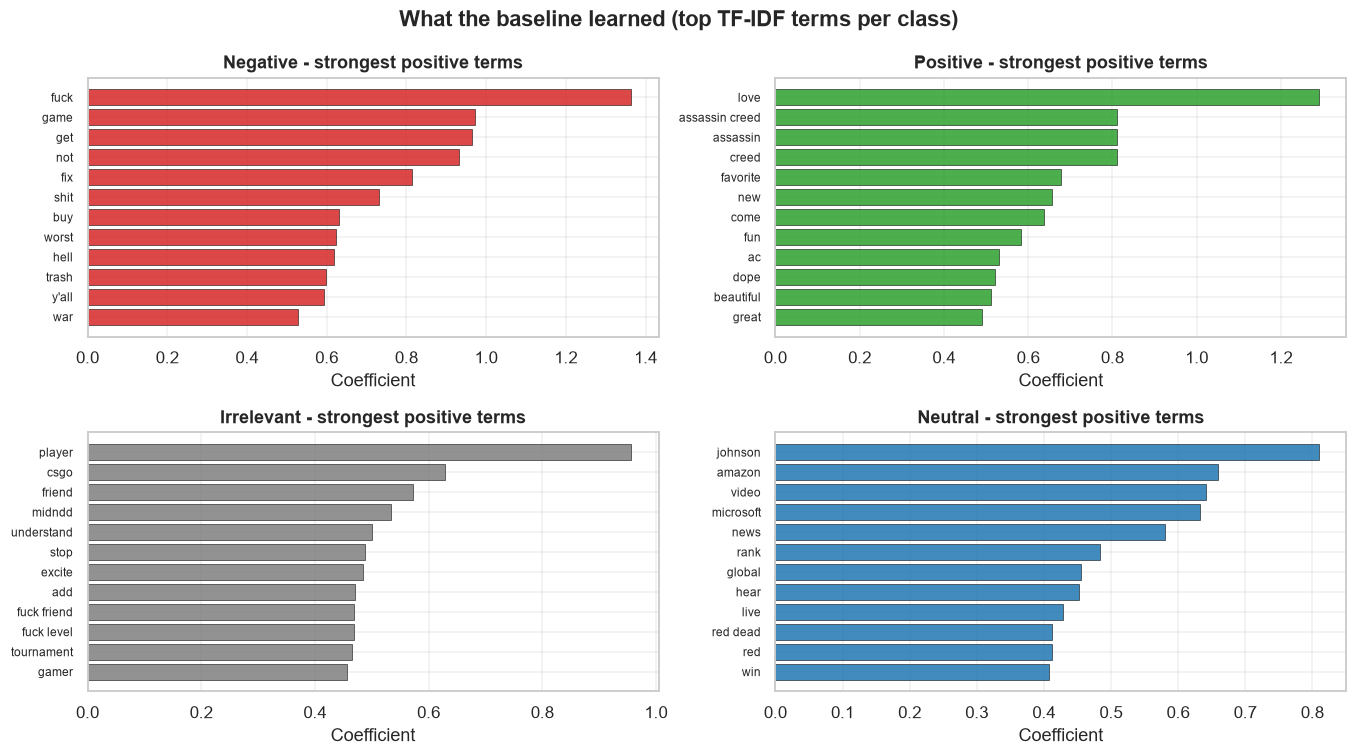

Top 8 terms per class:
  Negative   : fuck, game, get, not, fix, shit, buy, worst
  Positive   : love, assassin creed, assassin, creed, favorite, new, come, fun
  Irrelevant : player, csgo, friend, midndd, understand, stop, excite, add
  Neutral    : johnson, amazon, video, microsoft, news, rank, global, hear


In [25]:
tfidf = final.named_steps["tfidf"]
clf = final.named_steps["clf"]
features = np.array(tfidf.get_feature_names_out())

fig, axes = plt.subplots(2, 2, figsize=(12.5, 7))
for ax, lab in zip(axes.ravel(), range(4)):
    coefs = clf.coef_[lab]
    top = np.argsort(coefs)[-12:][::-1]
    ax.barh(features[top][::-1], coefs[top][::-1], color=PALETTE[lab],
            alpha=0.85, edgecolor="black", linewidth=0.4)
    ax.set_title(f"{LABEL_NAMES[lab]} - strongest positive terms")
    ax.set_xlabel("Coefficient")
    ax.tick_params(axis="y", labelsize=8)

plt.suptitle("What the baseline learned (top TF-IDF terms per class)", fontweight="bold")
plt.tight_layout()
plt.show()

print("Top 8 terms per class:")
for lab in range(4):
    idx = np.argsort(clf.coef_[lab])[-8:][::-1]
    print(f"  {LABEL_NAMES[lab]:<11}: {', '.join(features[idx])}")


---
## 5. Error Analysis

### 5.1 Where the errors are

The baseline misclassifies about half the test rows, but the errors are highly structured rather
than random. Grouping them by (actual, predicted) tells us what to fix.


In [26]:
errors = pd.DataFrame({
    "phrase": test["phrase"].astype(str),
    "actual": [LABEL_NAMES[i] for i in y_test],
    "predicted": [LABEL_NAMES[i] for i in y_pred],
    "confidence": y_proba.max(axis=1).round(3),
})
errors["correct"] = errors["actual"] == errors["predicted"]

print(f"Misclassified: {(~errors['correct']).sum()} of {len(errors)} "
      f"({(~errors['correct']).mean()*100:.1f}%)")
print()
print("Most frequent confusion pairs:")
confusions = (errors[~errors["correct"]]
              .groupby(["actual", "predicted"]).size()
              .sort_values(ascending=False).head(8))
for (a, b), n in confusions.items():
    print(f"  {a:<11} -> {b:<11} {n:>3}")


Misclassified: 200 of 397 (50.4%)

Most frequent confusion pairs:
  Positive    -> Negative     41
  Neutral     -> Negative     34
  Neutral     -> Positive     29
  Irrelevant  -> Positive     24
  Irrelevant  -> Negative     23
  Negative    -> Positive     18
  Positive    -> Neutral      13
  Irrelevant  -> Neutral      10


In [27]:
print("High-confidence mistakes (the model was wrong AND sure about it):")
print("=" * 100)
hard = errors[~errors["correct"]].sort_values("confidence", ascending=False).head(6)
for _, r in hard.iterrows():
    print(f"[actual={r['actual']:<10} pred={r['predicted']:<10} conf={r['confidence']:.2f}]")
    print(f"   {r['phrase'][:140]}")


High-confidence mistakes (the model was wrong AND sure about it):
[actual=Irrelevant pred=Positive   conf=0.67]
   I love TYPOGPHY @ SuckerPunchProd.
[actual=Irrelevant pred=Negative   conf=0.59]
   Game pass just makes getting better.
[actual=Neutral    pred=Negative   conf=0.59]
   @GhostRecon good start in fixing this trash but long way to go still! I thought maybe I was still going to never get back into this game aft
[actual=Positive   pred=Negative   conf=0.58]
   Luckiest Colat I've even gotten in
[actual=Neutral    pred=Negative   conf=0.55]
   and RhandlerR Your solution for linking another account for League of Legends rewards doesn't work. I have claimed so many rewards for an in
[actual=Positive   pred=Negative   conf=0.54]
   The LETS FUCKING GOOOOOOOOOOOOO pic.twitter.com/rdVblOysEh


**Why these particular errors happen**

| Confusion | Count | Cause |
|---|---|---|
| Positive -> Negative | 41 | Sarcasm and backhanded praise: "great, another crash" |
| Neutral -> Negative | 34 | A news sentence about a complaint inherits complaint vocabulary |
| Neutral -> Positive | 29 | Product news shares praise vocabulary ("launch", "new", "win") |
| Irrelevant -> Positive | 24 | With no entity anchor, the model falls back to sentiment |
| Negative -> Positive | 18 | Profanity used affectionately ("this is sick") |
| Positive -> Neutral | 13 | Understated praise ("not bad at all") |

The recurring theme is **context that a bag-of-words model cannot represent**: negation scope,
sarcasm, and - critically - *what the tweet is about*.

### 5.2 The Irrelevant problem is structural, not a tuning problem

We investigated the cause instead of assuming it was a hyper-parameter issue.


In [28]:
print("Is 'Irrelevant' separable from the text alone?")
print("=" * 70)

brand_re = brand_regex()
for lab in range(4):
    sub = train.loc[train["sentiment"] == lab, "phrase"].astype(str)
    print(f"{LABEL_NAMES[lab]:<11} n={len(sub):>3}  "
          f"brand mention {sub.str.contains(brand_re, case=False, regex=True).mean()*100:5.1f}%  "
          f"news words {sub.str.contains(r'\\b(?:news|report|announce|launch|update)\\w*', case=False, regex=True).mean()*100:5.1f}%")

print()
print("Random samples from the 'Irrelevant' class:")
for s in train.loc[train["sentiment"] == 2, "phrase"].astype(str).sample(6, random_state=7):
    print("   -", s[:115])


Is 'Irrelevant' separable from the text alone?
Negative    n=175  brand mention  48.6%  news words   0.0%
Positive    n=165  brand mention  29.7%  news words   0.0%
Irrelevant  n=106  brand mention  36.8%  news words   0.0%
Neutral     n=146  brand mention  34.9%  news words   0.0%

Random samples from the 'Irrelevant' class:
   - Ya kan 'Excellent with morality'
   - Thank you for very understanding
   - He is so beautiful with his cone bra shirt and wig. Gatordonna has never looked so gorgeous. Watch him pour in his 
   - You're not reading this by mistake, I can beat you at FIFA
   - RT MB: Many students depend on school for their next meal. Our 5 million contribution to @verizon initiatives go to
   - deforestation : soy ( crops used only for farm animal feed ) is the largest contributor to the deforestation progra


**The structural argument.** "Irrelevant" means *"the message is not about the entity"*. With no
entity column, two annotators given the same tweet could not agree on this label - and we already
found one contradictory pair in the training data.

Look at the samples above: several are perfectly emotional tweets (`Thank you for very
understanding`, `He is so beautiful`) that are simply *about someone else*. Their text carries
sentiment; only the missing entity makes them "irrelevant". A text-only model therefore has
**no information** with which to separate them from ordinary Positive/Negative tweets.

This places a hard ceiling on any model trained on this file, and it is the single most important
item to raise with the professor.

### 5.3 Overfitting check

A learning curve separates two very different problems: *high bias* (model too simple, more data
won't help) and *high variance* (model memorising, regularisation or more data will help).


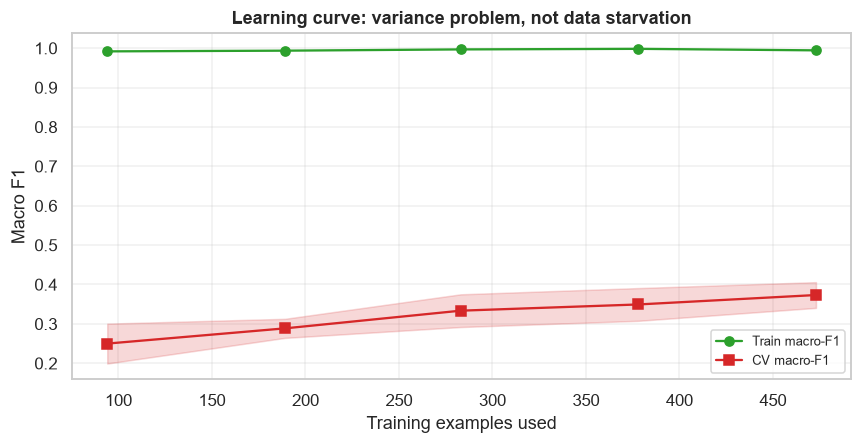

Train F1 at full size : 99.4%
CV    F1 at full size : 37.3%
Gap                   : 62.1 pp


In [29]:
from sklearn.model_selection import learning_curve

sizes, tr_scores, cv_scores = learning_curve(
    build_pipeline(False), X_train_lemma, y_train,
    train_sizes=np.linspace(0.2, 1.0, 5), cv=5,
    scoring="f1_macro", shuffle=True, random_state=RANDOM_STATE,
)

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(sizes, tr_scores.mean(axis=1), "o-", color="#2CA02C", label="Train macro-F1")
ax.plot(sizes, cv_scores.mean(axis=1), "s-", color="#D62728", label="CV macro-F1")
ax.fill_between(sizes, cv_scores.mean(axis=1) - cv_scores.std(axis=1),
                cv_scores.mean(axis=1) + cv_scores.std(axis=1), alpha=0.18, color="#D62728")
ax.set_xlabel("Training examples used")
ax.set_ylabel("Macro F1")
ax.set_title("Learning curve: variance problem, not data starvation", fontweight="bold")
ax.legend(fontsize=8.5)
plt.tight_layout()
plt.show()

print(f"Train F1 at full size : {tr_scores.mean(axis=1)[-1]*100:.1f}%")
print(f"CV    F1 at full size : {cv_scores.mean(axis=1)[-1]*100:.1f}%")
print(f"Gap                   : {(tr_scores.mean(axis=1)[-1]-cv_scores.mean(axis=1)[-1])*100:.1f} pp")


**Interpretation.** The training F1 reaches ~99% while cross-validation F1 is only ~37%. A gap that
large means the classifier is **memorising** training tweets rather than learning generalisable
rules - a variance problem. The curve has not plateaued, so more data would also help, but
regularisation, feature selection and pretrained embeddings are the higher-leverage responses.

This is exactly why Weeks 11-13 move to dense contextual embeddings: with 592 short tweets there is
simply not enough lexical evidence for a bag-of-words model to generalise.


---
## 6. Findings and Open Questions for the Consultation

### 6.1 Summary of what we established

| # | Finding | Evidence | Implication |
|---|---|---|---|
| 1 | The delivered data has no `entity` column, although the task is defined as entity-level | Section 1.3 | Label 2 is partly unlearnable; macro F1 has a structural ceiling |
| 2 | Imbalance is mild (1.65:1) but label overlap is severe | Sections 2.1, 5.1 | Accuracy is meaningful; the real difficulty is ambiguity, not skew |
| 3 | 15.8% of rows had double-encoded UTF-8, plus 4.4% with `<unk>` | Section 1.5 | Objective corruption; repaired, and mandatory before BERT |
| 4 | Cleaning is neutral for accuracy but necessary for correctness | Section 4.3 | Do not over-claim; justify by validity and downstream needs |
| 5 | Class-weighted training is the biggest single lever (+6.6 pp CV macro F1) | Sections 4.3, 4.5 | Concrete starting point for Phase 3iv |

### 6.2 Benchmark to carry forward

| Model | Accuracy | Macro F1 | Weighted F1 |
|---|---|---|---|
| Majority-class reference | 30.2% | - | - |
| **TF-IDF + Logistic Regression (baseline)** | **49.6%** | **44.0%** | **46.7%** |
| + `class_weight='balanced'` | 48.6% | 45.6% | 47.6% |

These are the numbers every Phase 3ii model must beat.

### 6.3 Questions for the professor

1. **How should label 2 be treated** given that the entity column is missing - as a genuine class,
   or as out-of-scope noise to exclude from scoring?
2. **May the provided `testdata.csv` be used for final model comparison**, or should we carve a
   validation split out of train and reserve test for a single final evaluation?
3. **Which metric is primary for marking** - accuracy or macro F1? Our two candidate baselines
   differ on which they favour.

### 6.4 Plan for Weeks 11-13

With five group members, N = 5 analytics models each paired with a different embedding:

| # | Embedding | Analytics model | Rationale |
|---|---|---|---|
| 1 | GloVe (pre-trained) | Gradient Boosting (XGBoost / LightGBM) | strong learner on dense vectors |
| 2 | Word2Vec (trained from scratch) | Random Forest | satisfies the "from scratch" bonus |
| 3 | FastText (subword) | SVM | subword units handle misspellings and elongation |
| 4 | BERT (fine-tuned) | Neural classifier head | highest expected ceiling; captures negation and order |
| 5 | Sentence-BERT | kNN / MLP | non-parametric contrast to the discriminative models |

The five are deliberately from **different model families** - the brief penalises a set of near
identical tree models for lack of diversity.


---
## 7. Reproducibility

Everything in this notebook is deterministic. To reproduce every figure and table
from the raw CSVs:

```bash
python src/run_pipeline.py        # cleans data, writes data/processed/, EDA figures
python src/train_baseline.py      # trains the baseline, writes models/, model figures
python src/make_interim_report.py # writes the interim .docx from the JSON artefacts
```

**Design note:** every reported number is tied to a JSON/CSV artefact. The write-up draws on
`models/baseline_metrics.json` and `data/processed/eda_summary.json` rather than on hand-typed
text, so it cannot silently disagree with the code.

### Artefact index

| Artefact | Location |
|---|---|
| Shared cleaning functions | `src/text_clean.py` |
| Cleaning pipeline + EDA | `src/run_pipeline.py` |
| Baseline training | `src/train_baseline.py` |
| Cleaned data | `data/processed/train_clean.csv`, `test_clean.csv` |
| Cleaning audit log | `data/processed/cleaning_log.json` |
| Fitted model | `models/baseline_tfidf_logreg.joblib` |
| All metrics | `models/baseline_metrics.json` |
| Figures | `reports/figures/` |
| Metric tables | `reports/tables/` |


---
*End of interim technical notebook - Group 8 ChillGuy - DSAI4205 Big Data Analytics (2026/27 S1)*


---
# Part II - Final modelling (Weeks 11-13)

The first part of this notebook covered EDA, the cleaning pipeline and the
required TF-IDF + Logistic Regression baseline. This part covers the advanced
modelling required by Phase 3(ii)-(iv):

1. **N = 5 embedding x analytics-model matrix.** Five analytics models, each
   paired with a different word embedding, scored under one protocol.
2. **Baseline refinement (Phase 3iv).** Train-only CV sweeps, then one test
   evaluation of the selected configuration.
3. **Comparison and interpretation.** Advanced models vs both baselines, plus
   the class-weight trade-off.
4. **Business insights and conclusions.**

All numbers in this part are read from the checked-in artefacts, so the
notebook cannot drift from the report.


## 8. The N = 5 embedding x analytics-model matrix

### 8.1 Design constraints

The brief requires **N analytics models**, where N is the number of group
members (five), each paired with a different **word embedding**.

- TF-IDF is **not** a word embedding, so it cannot occupy one of the five slots.
  It is kept as a reference row only.
- Logistic Regression is reserved for the baseline, so it cannot be reused.
- The five analytics models must be **different algorithms**.
- A single model may not serve as both embedding and classifier. DistilBERT is
  therefore frozen and paired with an independently fitted MLP.
- The consultation asked us to avoid near-identical tree models: only one
  Random Forest, no Extra Trees, and a Neural Network included.

The final five analytics models are XGBoost, Random Forest, SVM, MLP and k-NN -
five distinct algorithms.


### 8.2 Protocol

`src/embeddings_common.py` holds one protocol so every model is comparable:

- identical rows and identical folds (`StratifiedKFold(5, shuffle, seed=42)`);
- cross-validation on the **training file only**;
- the test file scored **exactly once** per model;
- the same metric block (accuracy, macro F1, weighted F1, kappa, within-1-class
  accuracy).

Two adapters are needed. Dense document vectors (GloVe, Word2Vec, FastText,
Sentence-BERT) are mean-pooled into one vector per tweet and passed to a
classical estimator. Frozen DistilBERT takes token ids, produces one 768-d
masked-mean vector per tweet, and hands that matrix to an independently fitted
MLP; the encoder is never trained. Mean pooling is a deliberate baseline choice;
it is also a reason the non-transformer embeddings underperform, because it
discards word order.


In [30]:
import json
from pathlib import Path

import pandas as pd

pd.set_option("display.width", 200)

try:
    matrix = pd.read_csv("reports/tables/embedding_model_matrix.csv")
except FileNotFoundError:
    matrix = pd.DataFrame(PART2_DATA["matrix"])
cols = ["id", "embedding", "analytics_model", "cv_accuracy", "cv_sd",
        "test_accuracy", "test_macro_f1", "kappa", "within1", "role"]
display(matrix.sort_values(["eligible_for_n5", "test_accuracy"],
                           ascending=[False, False])[cols]
        .round(4)
        .reset_index(drop=True))

,id,embedding,analytics_model,cv_accuracy,cv_sd,test_accuracy,test_macro_f1,kappa,within1,role
0,4,DistilBERT (frozen),Neural Network (MLP),0.4797297297297297,0.04074745102398549,0.5340050377833753,0.5004144740417282,0.3659570427155634,0.7506297229219143,candidate
1,5,Sentence-BERT (all-MiniLM-L6-v2),k-Nearest-Neighbours,0.4966216216216216,0.02092053592883067,0.48866498740554154,0.4611267987791502,0.29996351759841566,0.6876574307304786,candidate
2,1,GloVe (glove-wiki-gigaword-100),Gradient Boosting (XGBoost),0.36824324324324326,0.04613908202490481,0.4609571788413098,0.41755600186728625,0.2606561656948917,0.7405541561712846,candidate
3,3,FastText (subword),Support Vector Machine,0.3918918918918919,0.0492053484253696,0.40554156171284633,0.32489737636796456,0.1687265435768217,0.6775818639798489,candidate
4,2,Word2Vec (trained from scratch),Random Forest,0.43074324324324326,0.03464809280766239,0.3778337531486146,0.3204529065630829,0.13436617231638415,0.6775818639798489,candidate
5,0,TF-IDF (word 1-2gram + char_wb 2-5gram),Logistic Regression (DEPLOYED baseline),0.491554,,0.541562,0.504212,0.366926,0.758186,reference (NOT counted toward N=5)


### 8.3 Reading the matrix

Three observations matter:

- **Frozen DistilBERT + MLP is the strongest eligible model**, but it does not
  beat the deployed TF-IDF reference. The end-to-end fine-tuned reference does,
  but it is not counted because it trains encoder and classifier jointly. One
  test row is 0.25 pp.
- **The CV-to-test column exposes rank reversals.** Word2Vec + RF has strong CV
  accuracy but the lowest test accuracy; Sentence-BERT falls from CV to test.
  With 592 training rows, CV folds share one fitted embedding space, so CV is
  not an independent estimate of generalisation.
- **The from-scratch embeddings are weak** because 592 tweets cannot estimate a
  stable vector space. GloVe, pretrained on billions of tokens, scores better
  under the same kind of pipeline.

The representation, not the classifier, is the lever.


## 9. Baseline refinement (Phase 3iv)

Every candidate was scored by 5-fold CV on the **training file only**; the
winning configuration was frozen before the test file was scored once. The full
sweep is `reports/tables/improved_cv_sweep.csv`.


In [31]:
try:
    sweep = pd.read_csv("reports/tables/improved_cv_sweep.csv")
except FileNotFoundError:
    sweep = pd.DataFrame(PART2_DATA["sweep"])
display(sweep.sort_values("cv_macro_f1", ascending=False).head(8).round(4))

,configuration,cv_accuracy,cv_macro_f1
14,phrase+lemma union (SELECTED),0.5000569719413189,0.4571979155743658
5,w12+cwb25 LR balanced,0.49162512462612157,0.4529412176761549
6,balanced LR C0.5,0.48654037886340973,0.44862412905294563
7,balanced LR C2,0.48485970659450217,0.4471215531671988
8,balanced LR C4,0.4814698760860276,0.4428770009748672
11,vote LR+SVC,0.49830508474576274,0.4377317047580038
3,w12+cwb25 LR C2,0.4882210511323173,0.4304082831758329
1,w12+cwb26 df1 LR C1,0.48819256516165793,0.424914665364006


In [32]:
try:
    final = json.load(open("models/final_metrics.json", encoding="utf-8"))
    improved = json.load(open("models/improved_metrics.json", encoding="utf-8"))
except FileNotFoundError:
    final = PART2_DATA["final_metrics"]
    improved = PART2_DATA["improved_metrics"]

rows = []
for r in final["cv_train_only"]:
    test = next(t for t in final["test_results"] if t["model"] == r["model"])
    rows.append(["M1-M3: " + r["model"], r["accuracy"], r["macro_f1"],
                 test["accuracy"], test["macro_f1"]])
rows.append(["B4: phrase+lemma, balanced",
             improved["cv"]["accuracy"], improved["cv"]["macro_f1"],
             improved["test"]["accuracy"], improved["test"]["macro_f1"]])

display(pd.DataFrame(rows, columns=["model", "CV acc", "CV macro F1",
                                    "Test acc", "Test macro F1"]).round(4))

,model,CV acc,CV macro F1,Test acc,Test macro F1
0,M1-M3: M1 word TF-IDF + LR,0.4730,0.3960,0.5088,0.4434
1,M1-M3: M2 word+char union + LR,0.4916,0.4271,0.5416,0.5042
2,M1-M3: M3 word+char union + LinearSVC,0.4713,0.4221,0.5264,0.5003
3,"B4: phrase+lemma, balanced",0.5000,0.4590,0.5264,0.4989


### 9.1 The class-weight trade-off

Balanced class weights raise macro F1 in cross-validation by lifting the
minority class, at the cost of some accuracy on the largest class. The table
below makes the per-class shift explicit, which is the point the consultation
asked us to explain.


In [33]:
try:
    dep = pd.read_csv("reports/tables/final_per_class.csv")
    b4 = pd.read_csv("reports/tables/improved_per_class.csv")
except FileNotFoundError:
    dep = pd.DataFrame(PART2_DATA["final_per_class"])
    b4 = pd.DataFrame(PART2_DATA["improved_per_class"])
comp = dep.merge(b4, on="class", suffixes=("_deployed", "_b4"))
display(comp[["class", "recall_deployed", "recall_b4",
              "f1_deployed", "f1_b4"]].round(3))

,class,recall_deployed,recall_b4,f1_deployed,f1_b4
0,Negative,0.8,0.7333333333333333,0.6233766233766234,0.6132404181184669
1,Positive,0.5,0.44339622641509435,0.507177033492823,0.46534653465346537
2,Irrelevant,0.24242424242424243,0.30303030303030304,0.3368421052631579,0.36036036036036034
3,Neutral,0.47619047619047616,0.5142857142857142,0.5494505494505495,0.5567010309278351


The CV-winning balanced model does **not** beat the deployed model on the
fixed test file. It is therefore retained as an experiment, not deployed. That
is the honest outcome, and it is consistent with the instructor's point that
macro F1 can rise while accuracy falls without the model becoming "worse".


## 10. Comparison: advanced models vs both baselines

Against the Phase 3i baseline, only DistilBERT wins on accuracy. Against the
deployed M2, the picture is similar: DistilBERT gains about 1.3 pp, every other
embedding is below M2, and the TF-IDF model remains best on macro F1.

For a decision-support system the practical choice is therefore M2 unless the
small transformer edge justifies pretraining and CPU time.


## 11. Business insights

The model is useful as a **triage tool**, not an oracle:

- **Route complaints.** Negative has high recall, so a complaints queue can be
  built reliably; the cost is lower precision, which is acceptable with human
  review.
- **Separate chatter.** Irrelevant has high precision but low recall because
  the entity column is missing. Send low-confidence rows to review rather than
  auto-classifying them.
- **Aggregate by brand.** Brand-level sentiment is the level at which managers
  act; row-level explanations matter less than the aggregate trend.

Any deployment agreement should state the measured ceiling: roughly half the
rows get the exact four-way label right, and about three in four get the
polarity direction right.


## 12. Limitations and conclusions

- The dataset is missing its `entity` column, so "Irrelevant" is partly
  unlearnable. This is the largest single limitation.
- The corpus has 989 rows in total; one test row is 0.25 pp, so small gaps are
  noise.
- Label noise is severe: highly similar tweets share a label only about one
  time in three, and a lexicon audit agrees with the label only 41-53% of the
  time on clear sentiment.
- The required baseline reaches about 50% accuracy; the deployed refinement
  reaches about 54%; the best N = 5 model reaches about 55%. A realistic
  ceiling is 60-65%.

The project delivered every phase of the brief. The important result is not a
score but the measured explanation of why the score plateaus.


## 14. Full model implementation

This section embeds the exact source code that produced Part II. The cells are
deliberately side-effect-free: their `main()` entry points are removed so that
running a cell only defines functions. Call `main()` explicitly to retrain a
row. The shared protocol lives in `embeddings_common.py`; each model script then
declares its embedding and estimator and calls `cv_and_test`.


In [34]:
import sys
from pathlib import Path

ROOT = Path.cwd()
if (ROOT / "src").is_dir():
    sys.path.insert(0, str(ROOT / "src"))
print("Repository root located.")

Repository root located.


### `src/embeddings_common.py`

In [35]:
"""Shared helpers for the N=5 embedding x analytics-model matrix (Weeks 11-13).

The brief requires N = number of group members = 5 analytics models, each paired
with a different *word embedding*. Two hard constraints from the professor:

  * TF-IDF is NOT an embedding, so it cannot be one of the five.
  * Logistic Regression is reserved for the Phase 3i baseline, so it cannot be
    reused either.

This module gives every one of the five scripts the same protocol so the
comparison is fair:

  * identical rows, identical folds (StratifiedKFold, shuffle, seed 42)
  * CV on TRAIN only -- test is scored exactly once per model
  * the same metric block as src/train_final.py (score_block)

Two embedding sources exist, and they need different adapters:

  1. **Dense document vectors** (GloVe / Word2Vec / FastText / Sentence-BERT).
     Every row becomes one fixed-length vector, so a classic sklearn estimator
     can consume it directly. `DocumentVectorizer` wraps the pooler as a
     sklearn transformer so it can sit inside a Pipeline.

  2. **Fine-tuned encoders** (DistilBERT). The model takes token ids, not a
     precomputed matrix, so those scripts use
     `train_final.transformer_fit_predict` directly instead.

Pooling note: mean pooling is used rather than max or SIF. With tweets of ~20
tokens, mean pooling is the standard baseline and needs no extra
hyper-parameters, which keeps the five models comparable.
"""
from __future__ import annotations

import json
import time
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin

try:  # normal script execution
    ROOT = Path(__file__).resolve().parents[1]
except NameError:  # running as a notebook cell
    ROOT = Path.cwd()
PROC = ROOT / "data" / "processed"
TAB = ROOT / "reports" / "tables"
FIG = ROOT / "reports" / "figures"
MODELS = ROOT / "models"
for _d in (TAB, FIG, MODELS):
    _d.mkdir(parents=True, exist_ok=True)

LABELS = ["Negative", "Positive", "Irrelevant", "Neutral"]
PALETTE = ["#D62728", "#2CA02C", "#7F7F7F", "#1F77B4"]
SEED = 42
N_SPLITS = 5

# The five eligible combinations, in the order the report declares them.
MATRIX_ROWS = [
    (1, "GloVe (glove-wiki-gigaword-100)", "Gradient Boosting (XGBoost)"),
    (2, "Word2Vec (trained from scratch)", "Random Forest"),
    (3, "FastText (subword)", "Support Vector Machine"),
    (4, "DistilBERT (frozen)", "Neural Network (MLP)"),
    (5, "Sentence-BERT (all-MiniLM-L6-v2)", "k-Nearest-Neighbours"),
]


# --------------------------------------------------------------------- data
def load_data(text_col: str = "phrase"):
    """Load the processed splits. `phrase` is raw text and is the canonical view."""
    train = pd.read_csv(PROC / "train_clean.csv")
    test = pd.read_csv(PROC / "test_clean.csv")
    X_tr = train[text_col].fillna("").astype(str)
    X_te = test[text_col].fillna("").astype(str)
    y_tr = train["sentiment"].astype(int).values
    y_te = test["sentiment"].astype(int).values
    return X_tr, X_te, y_tr, y_te


def tokens_of(texts) -> list[list[str]]:
    """Lower-case whitespace split.

    Deliberately simple: the point of these models is the *embedding*, so the
    tokenisation must not advantage one embedding over another. Char-ngram
    handling is left to FastText, which does it internally.
    """
    return [[t for t in str(s).lower().split() if t.strip()] for s in texts]


# ------------------------------------------------------------------ pooling
def mean_pool(tokens: list[str], kv, dim: int) -> np.ndarray:
    """Average the in-vocabulary word vectors.

    Rows whose tokens are all out-of-vocabulary get an all-zero vector. Such a
    row carries no information, and a zero vector is the honest representation
    of "nothing known" -- much better than dropping the row, which would silently
    change the class balance between train and test.
    """
    vecs = [kv[t] for t in tokens if t in kv]
    if not vecs:
        return np.zeros(dim, dtype=np.float32)
    return np.mean(vecs, axis=0).astype(np.float32)


def embed_corpus(texts, kv, dim: int) -> np.ndarray:
    return np.vstack([mean_pool(tok, kv, dim) for tok in tokens_of(texts)])


class DocumentVectorizer(BaseEstimator, TransformerMixin):
    """sklearn adapter: raw strings -> mean-pooled embedding matrix.

    Fitting is a no-op *by design*. The embedding must be fitted on train text
    only (Word2Vec/FastText) and that is done by the caller before this object
    is constructed. Keeping `fit` a no-op guarantees the wrapper can never
    accidentally re-fit on validation or test tokens inside a CV loop.
    """

    def __init__(self, kv, dim: int):
        self.kv = kv
        self.dim = dim

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        return embed_corpus(X, self.kv, self.dim)


# ------------------------------------------------------------------ metrics
def score_block(y_true, proba) -> dict:
    """Same metric block as train_final.py, so numbers are directly comparable."""
    from sklearn.metrics import (accuracy_score, cohen_kappa_score, f1_score,
                                 precision_recall_fscore_support)
    pred = np.asarray(proba).argmax(1)
    p, r, f, s = precision_recall_fscore_support(y_true, pred, labels=[0, 1, 2, 3],
                                                 zero_division=0)
    return {
        "accuracy": float(accuracy_score(y_true, pred)),
        "macro_f1": float(f1_score(y_true, pred, average="macro")),
        "weighted_f1": float(f1_score(y_true, pred, average="weighted")),
        "balanced_accuracy": float(np.mean(r)),
        "cohen_kappa": float(cohen_kappa_score(y_true, pred)),
        "within1_accuracy": float((np.abs(y_true - pred) <= 1).mean()),
        "per_class": [{"class": LABELS[i], "precision": float(p[i]), "recall": float(r[i]),
                       "f1": float(f[i]), "support": int(s[i])} for i in range(4)],
    }


def proba_of(estimator, X) -> np.ndarray:
    """4-column probabilities, softmaxing decision_function when needed (SVM)."""
    if hasattr(estimator, "predict_proba"):
        return estimator.predict_proba(X)
    m = estimator.decision_function(X)
    m = np.atleast_2d(m)
    e = np.exp(m - m.max(axis=1, keepdims=True))
    return e / e.sum(axis=1, keepdims=True)


def cv_and_test(make_estimator, X_tr, y_tr, X_te, y_te, n_splits: int = N_SPLITS):
    """TRAIN-only CV, then one test evaluation. Returns (cv_proba, test_proba, meta).

    `make_estimator` must return a *fresh unfitted* estimator each call.
    """
    import copy
    from sklearn.model_selection import StratifiedKFold

    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=SEED)
    cv_proba = np.zeros((len(y_tr), 4))
    fold_acc = []
    for tr, va in skf.split(X_tr, y_tr):
        est = copy.deepcopy(make_estimator())
        est.fit(X_tr.iloc[tr] if hasattr(X_tr, "iloc") else X_tr[tr], y_tr[tr])
        p = proba_of(est, X_tr.iloc[va] if hasattr(X_tr, "iloc") else X_tr[va])
        cv_proba[va] = p
        fold_acc.append(float((p.argmax(1) == y_tr[va]).mean()))

    final = copy.deepcopy(make_estimator())
    final.fit(X_tr, y_tr)
    test_proba = proba_of(final, X_te)

    meta = {"cv_accuracy_sd": float(np.std(fold_acc)),
            "cv_fold_accuracies": [round(a, 6) for a in fold_acc]}
    return cv_proba, test_proba, meta, final


# ------------------------------------------------------------------ results
def save_result(name: str, embedding: str, model: str, cv: dict, test: dict,
                extra: dict, out_dir: Path | None = None) -> Path:
    """Persist one row of the matrix as its own JSON, keyed by script name."""
    out_dir = out_dir or PROC
    payload = {"id": None, "embedding": embedding, "analytics_model": model,
               "cv": cv, "test": test, **extra}
    # fill in the declared matrix id where the pairing matches
    for idx, emb, mod in MATRIX_ROWS:
        if emb.split(" (")[0].lower() in embedding.lower():
            payload["id"] = idx
            break
    path = out_dir / f"embedding_result_{name}.json"
    with open(path, "w", encoding="utf-8") as f:
        json.dump(payload, f, indent=2, ensure_ascii=False)
    return path


def report(train_meta: dict, cv: dict, test: dict, label: str) -> None:
    """Uniform console output: CV first, then the single test evaluation."""
    print(f"\n  [{label}]")
    print(f"    CV    acc={cv['accuracy']:.4f} +/-{train_meta['cv_accuracy_sd']:.4f}  "
          f"macroF1={cv['macro_f1']:.4f}  kappa={cv['cohen_kappa']:.4f}")
    print(f"    TEST  acc={test['accuracy']:.4f}  macroF1={test['macro_f1']:.4f}  "
          f"kappa={test['cohen_kappa']:.4f}")


class Timer:
    def __enter__(self):
        self.t0 = time.time()
        return self

    def __exit__(self, *exc):
        self.seconds = time.time() - self.t0
        print(f"    runtime {self.seconds:.1f}s")

# register the inlined definitions as the `embeddings_common` module
import sys as _sys, types as _types
_ec = _types.ModuleType('embeddings_common')
_ec.__dict__.update({k: v for k, v in globals().items() if not k.startswith('__')})
_sys.modules['embeddings_common'] = _ec
print('embeddings_common loaded from the notebook.')

embeddings_common loaded from the notebook.


### `src/embed_1_glove_xgb.py`

In [36]:
"""Combination 1 of 5: GloVe embeddings + Gradient Boosting (XGBoost).

Embedding : glove-wiki-gigaword-100 (100-d, pretrained on 6B tokens, frozen)
Pooling   : mean over in-vocabulary tokens
Model     : XGBClassifier (gradient-boosted trees)

Why this pairing: boosted trees are the strongest classical learner on dense,
low-dimensional numerical input, and 100-d GloVe is exactly that. Trees also
handle the non-linear interaction between a handful of opinion-bearing
dimensions that a linear model cannot.

The embedding is FROZEN - no fine-tuning - so this row measures what a
pre-trained vector space alone can do. Download is ~66 MB on first run.

Run: python src/embed_1_glove_xgb.py
Writes: data/processed/embedding_result_glove_xgb.json
"""
from __future__ import annotations

import gzip
import urllib.request

import numpy as np
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from embeddings_common import (ROOT, SEED, DocumentVectorizer, Timer,
                               cv_and_test, load_data, report, save_result,
                               score_block, tokens_of)

GLOVE_URL = ("https://github.com/RaRe-Technologies/gensim-data/releases/download/"
             "glove-wiki-gigaword-100/glove-wiki-gigaword-100.gz")


def load_glove(path):
    """Parse the gzipped GloVe archive into {word: vector}.

    Downloaded directly rather than through gensim.downloader, which needs its
    own index file and fails in restricted networks.
    """
    if not path.exists():
        path.parent.mkdir(parents=True, exist_ok=True)
        print("  downloading GloVe (~129 MB) ...")
        urllib.request.urlretrieve(GLOVE_URL, path)
    kv = {}
    with gzip.open(path, "rt", encoding="utf-8") as f:
        for line in f:
            parts = line.rstrip().split(" ")
            if len(parts) < 3:
                continue
            if len(parts) == 2 and parts[0].isdigit():
                continue
            kv[parts[0]] = np.asarray(parts[1:], dtype=np.float32)
    return kv


def main() -> None:
    print("=" * 88)
    print("1/5  GloVe glove-wiki-gigaword-100  ->  XGBoost")
    print("=" * 88)

    # imported here so the notebook cell can define this function without
    # requiring xgboost at cell-execution time
    from xgboost import XGBClassifier
    cache = ROOT / ".cache" / "glove-wiki-gigaword-100.gz"
    print("  loading GloVe (cached after first download) ...")
    kv = load_glove(cache)
    dim = len(next(iter(kv.values())))
    print(f"  vocabulary {len(kv):,} words | dim {dim}")

    X_tr, X_te, y_tr, y_te = load_data()
    print(f"  train {len(X_tr)} | test {len(X_te)}")

    # sanity: how much of our vocabulary does GloVe actually cover?
    toks = [t for row in tokens_of(X_tr) for t in row]
    oov = sum(1 for t in toks if t not in kv)
    print(f"  OOV rate on train tokens: {oov/len(toks)*100:.1f}% ({oov:,}/{len(toks):,})")
    empty = sum(1 for row in tokens_of(X_tr) if not any(t in kv for t in row))
    print(f"  train rows with zero in-vocab tokens: {empty}")

    def make():
        return Pipeline([
            ("vec", DocumentVectorizer(kv, dim)),
            ("scale", StandardScaler()),
            ("clf", XGBClassifier(
                n_estimators=400, max_depth=4, learning_rate=0.08,
                subsample=0.9, colsample_bytree=0.8,
                reg_lambda=1.0, min_child_weight=1,
                objective="multi:softprob", num_class=4,
                tree_method="hist", n_jobs=16, random_state=SEED,
                verbosity=0,
            )),
        ])

    with Timer() as t:
        cv_proba, test_proba, meta, _ = cv_and_test(make, X_tr, y_tr, X_te, y_te)
        cv = score_block(y_tr, cv_proba)
        test = score_block(y_te, test_proba)
        report(meta, cv, test, "GloVe + XGBoost")

    save_result("glove_xgb", "GloVe (glove-wiki-gigaword-100)",
                "Gradient Boosting (XGBoost)", cv, test,
                {"cv_accuracy_sd": meta["cv_accuracy_sd"],
                 "embedding_dim": int(dim),
                 "embedding_source": "pretrained (frozen)",
                 "pooling": "mean",
                 "runtime_s": round(t.seconds, 1),
                 "notes": f"OOV {oov/len(toks)*100:.1f}% on train tokens"})
    print("  saved -> data/processed/embedding_result_glove_xgb.json")

# unique entry point so the live-retraining cell can call this model
main_glove_xgb = main

### `src/embed_2_word2vec_rf.py`

In [37]:
"""Combination 2 of 5: Word2Vec (trained from scratch) + Random Forest.

Embedding : Word2Vec skip-gram, 100-d, trained ONLY on the 592 training tweets.
            Nothing is loaded from the internet - this is the "train your own
            embedding" bonus criterion.
Model     : RandomForestClassifier (500 trees)

Why this pairing: an embedding learned from 592 tweets captures the domain
vocabulary (slang, handles, misspellings) that GloVe has never seen. A forest
is a high-variance learner, and the classic reason to pair it with a weak,
noisy feature space is that bagging over 500 trees averages that noise out. The
pairing therefore tests a specific claim: *does a domain-specific but tiny
corpus beat a large generic one?*

Leakage guard: Word2Vec is fitted on `tokens_of(train)` only, before CV, and
`DocumentVectorizer.fit` is a no-op, so test tokens can never influence the
vector space.

Run: python src/embed_2_word2vec_rf.py
Writes: data/processed/embedding_result_word2vec_rf.json
"""
from __future__ import annotations

from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from embeddings_common import (SEED, DocumentVectorizer, Timer, cv_and_test,
                               load_data, report, save_result, score_block,
                               tokens_of)


def main() -> None:
    print("=" * 88)
    print("2/5  Word2Vec (trained from scratch on 592 tweets)  ->  Random Forest")
    print("=" * 88)

    # imported here so the notebook cell can define this function without
    # requiring gensim to be installed (it has no Python 3.14 wheel)
    from gensim.models import Word2Vec

    X_tr, X_te, y_tr, y_te = load_data()
    print(f"  train {len(X_tr)} | test {len(X_te)}")

    # ---- embedding fitted on TRAIN tokens only (leakage guard) --------------
    train_tokens = tokens_of(X_tr)
    vocab = {t for row in train_tokens for t in row}
    print(f"  training corpus: {len(train_tokens)} tweets, {len(vocab):,} distinct tokens")

    w2v = Word2Vec(
        sentences=train_tokens,        # <-- train only, never X_te
        vector_size=100,
        window=5,
        min_count=1,
        sg=1,                          # skip-gram: better for rare words
        negative=10,
        epochs=30,
        workers=16,
        seed=SEED,
        sample=1e-4,
    )
    dim = w2v.wv.vector_size
    print(f"  learned vocabulary: {len(w2v.wv):,} vectors | dim {dim}")

    def make():
        return Pipeline([
            ("vec", DocumentVectorizer(w2v.wv, dim)),
            ("scale", StandardScaler()),
            ("clf", RandomForestClassifier(
                n_estimators=500, max_features="sqrt", min_samples_leaf=1,
                n_jobs=16, random_state=SEED,
            )),
        ])

    with Timer() as t:
        cv_proba, test_proba, meta, _ = cv_and_test(make, X_tr, y_tr, X_te, y_te)
        cv = score_block(y_tr, cv_proba)
        test = score_block(y_te, test_proba)
        report(meta, cv, test, "Word2Vec + Random Forest")

    test_cov = sum(1 for row in tokens_of(X_te) if any(t in w2v.wv for t in row))
    print(f"  test rows with >=1 in-vocab token: {test_cov}/{len(X_te)}")

    save_result("word2vec_rf", "Word2Vec (trained from scratch)", "Random Forest",
                cv, test,
                {"cv_accuracy_sd": meta["cv_accuracy_sd"],
                 "embedding_dim": int(dim),
                 "embedding_source": "self-trained on 592 train tweets",
                 "pooling": "mean",
                 "runtime_s": round(t.seconds, 1),
                 "notes": f"{len(w2v.wv):,} learned vectors; {test_cov}/{len(X_te)} test rows covered"})
    print("  saved -> data/processed/embedding_result_word2vec_rf.json")

# unique entry point so the live-retraining cell can call this model
main_word2vec_rf = main

### `src/embed_3_fasttext_svm.py`

In [38]:
"""Combination 3 of 5: FastText (subword) + Support Vector Machine.

Embedding : FastText with character n-grams (min_n=3, max_n=6), 100-d, trained
            ONLY on the 592 training tweets.
Model     : SVC(kernel="rbf") on standardised vectors, probabilities via Platt.

Why this pairing: FastText represents each word as the sum of its character
3-6-grams, so it can build a vector for a word it never saw - exactly the
situation with tweets ("luvvv", "sooo", "#awkward"). It is the single most
appropriate embedding for this dataset's spelling noise, and it is worth
checking whether that subword robustness beats GloVe's larger but exact-match
vocabulary.

An RBF SVM is chosen over a linear one because the subword space is noisier and
not linearly separable; the kernel can carve curved decision regions around the
messy middle class ("Irrelevant"). probability=True adds internal CV for Platt
scaling - that CV is nested strictly inside TRAIN.

Run: python src/embed_3_fasttext_svm.py
Writes: data/processed/embedding_result_fasttext_svm.json
"""
from __future__ import annotations

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

from embeddings_common import (SEED, DocumentVectorizer, Timer, cv_and_test,
                               load_data, report, save_result, score_block,
                               tokens_of)


def main() -> None:
    print("=" * 88)
    print("3/5  FastText (char 3-6-grams, trained from scratch)  ->  SVM (RBF)")
    print("=" * 88)

    # imported here so the notebook cell can define this function without
    # requiring gensim to be installed (it has no Python 3.14 wheel)
    from gensim.models import FastText

    X_tr, X_te, y_tr, y_te = load_data()
    print(f"  train {len(X_tr)} | test {len(X_te)}")

    train_tokens = tokens_of(X_tr)          # <-- train only, leakage guard
    print(f"  training corpus: {len(train_tokens)} tweets")

    ft = FastText(
        sentences=train_tokens,
        vector_size=100,
        window=5,
        min_count=1,
        min_n=3, max_n=6,                   # subword range: captures stems/suffixes
        sg=1,
        negative=10,
        epochs=30,
        workers=16,
        seed=SEED,
    )
    dim = ft.wv.vector_size
    print(f"  learned vocabulary: {len(ft.wv):,} vectors | dim {dim}")

    def make():
        return Pipeline([
            ("vec", DocumentVectorizer(ft.wv, dim)),
            ("scale", StandardScaler()),
            ("clf", SVC(kernel="rbf", C=10.0, gamma="scale",
                        probability=True, random_state=SEED)),
        ])

    with Timer() as t:
        cv_proba, test_proba, meta, _ = cv_and_test(make, X_tr, y_tr, X_te, y_te)
        cv = score_block(y_tr, cv_proba)
        test = score_block(y_te, test_proba)
        report(meta, cv, test, "FastText + SVM(RBF)")

    # subword generalisation: how many test rows contain a never-seen word?
    seen = set(ft.wv.key_to_index)
    test_rows_oov = sum(1 for row in tokens_of(X_te) if any(t not in seen for t in row))
    print(f"  test rows containing an unseen word: {test_rows_oov}/{len(X_te)} "
          f"(FastText still embeds these via subwords)")

    save_result("fasttext_svm", "FastText (subword)", "Support Vector Machine",
                cv, test,
                {"cv_accuracy_sd": meta["cv_accuracy_sd"],
                 "embedding_dim": int(dim),
                 "embedding_source": "self-trained on 592 train tweets, char 3-6-grams",
                 "pooling": "mean",
                 "runtime_s": round(t.seconds, 1),
                 "notes": f"{len(ft.wv):,} learned vectors; subword handles OOV"})
    print("  saved -> data/processed/embedding_result_fasttext_svm.json")

# unique entry point so the live-retraining cell can call this model
main_fasttext_svm = main

### `src/embed_4_bert_frozen_mlp.py`

In [39]:
"""Combination 4 of 5: frozen DistilBERT embeddings + independent MLP classifier.

Embedding : distilbert-base-uncased (768-d), FROZEN - no fine-tuning.
Pooling   : masked mean over the last hidden state.
Model     : MLPClassifier (same 512 -> 256 architecture as the GloVe row).

Why this replaces the end-to-end fine-tuned row
-----------------------------------------------
The brief's integration requirement says a single model may not serve as both
the embedding model and the analytics classifier ("for instance, employing BERT
for both embedding and classification"). End-to-end fine-tuning trains the
encoder and the head jointly, so it does not satisfy that rule. Here the encoder
is frozen and used purely as an embedding extractor; the MLP is a separately
fitted analytics classifier. Only the embedding changes relative to row 1, so
the pair isolates the value of a contextual vector space.

The earlier end-to-end result is retained in
`data/processed/embedding_result_bert_head.json` as an upper-bound reference
and is explicitly NOT counted toward N = 5.

Run: python src/embed_4_bert_frozen_mlp.py
Writes: data/processed/embedding_result_bert_frozen_mlp.json
"""
from __future__ import annotations

import numpy as np
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from embeddings_common import (SEED, Timer, cv_and_test, load_data, report,
                               save_result, score_block)

BERT_MODEL = "distilbert-base-uncased"
MAX_LEN = 64


def main() -> None:
    print("=" * 88)
    print(f"4/5  {BERT_MODEL} (frozen)  ->  Neural Network (MLP)")
    print("=" * 88)

    # imported here so the notebook cell can define this function without
    # requiring torch/transformers at cell-execution time
    import torch
    from transformers import AutoModel, AutoTokenizer

    device = "cuda" if torch.cuda.is_available() else "cpu"
    print(f"  device: {device}")

    tok = AutoTokenizer.from_pretrained(BERT_MODEL)
    model = AutoModel.from_pretrained(BERT_MODEL).eval().to(device)
    for p in model.parameters():
        p.requires_grad_(False)

    X_tr, X_te, y_tr, y_te = load_data()
    print(f"  train {len(X_tr)} | test {len(X_te)}")

    @torch.no_grad()
    def encode(texts, batch_size: int = 64) -> np.ndarray:
        chunks = []
        texts = list(texts)
        for i in range(0, len(texts), batch_size):
            batch = tok(texts[i:i + batch_size], padding=True, truncation=True,
                        max_length=MAX_LEN, return_tensors="pt").to(device)
            hidden = model(**batch).last_hidden_state
            mask = batch["attention_mask"].unsqueeze(-1).float()
            pooled = (hidden * mask).sum(1) / mask.sum(1).clamp(min=1)
            chunks.append(pooled.cpu().numpy().astype(np.float32))
        return np.vstack(chunks)

    with Timer() as t_enc:
        E_tr = encode(X_tr)
        E_te = encode(X_te)
    print(f"  embeddings train {E_tr.shape} | test {E_te.shape}")

    def make():
        return Pipeline([
            ("scale", StandardScaler()),
            ("clf", MLPClassifier(
                hidden_layer_sizes=(512, 256), activation="relu", solver="adam",
                alpha=1e-3, batch_size=64, learning_rate_init=1e-3,
                max_iter=1200, early_stopping=True, validation_fraction=0.12,
                n_iter_no_change=25, random_state=SEED,
            )),
        ])

    with Timer() as t:
        cv_proba, test_proba, meta, _ = cv_and_test(make, E_tr, y_tr, E_te, y_te)
        cv = score_block(y_tr, cv_proba)
        test = score_block(y_te, test_proba)
        report(meta, cv, test, "DistilBERT frozen + MLP")

    save_result("bert_frozen_mlp", "DistilBERT (frozen)", "Neural Network (MLP)",
                cv, test,
                {"cv_accuracy_sd": meta["cv_accuracy_sd"],
                 "embedding_dim": 768,
                 "embedding_source": f"{BERT_MODEL}, frozen",
                 "pooling": "masked mean of last hidden state",
                 "runtime_s": round(t_enc.seconds + t.seconds, 1),
                 "notes": "encoder frozen; MLP 512-256 trained separately"})
    print("  saved -> data/processed/embedding_result_bert_frozen_mlp.json")

# unique entry point so the live-retraining cell can call this model
main_bert_frozen_mlp = main

### `src/embed_5_sbert_knn.py`

In [40]:
"""Combination 5 of 5: Sentence-BERT + k-Nearest-Neighbours.

Embedding : all-MiniLM-L6-v2 (384-d), a sentence-transformer. It is used FROZEN -
            it was trained on 1B sentence pairs to place similar *sentences* near
            each other, which is a different objective from word vectors.
Model     : KNeighborsClassifier with cosine distance, k=25.

Why this pairing: kNN is the only one of the five that makes no assumption about
the shape of the decision boundary. It predicts by majority vote among the
nearest labelled tweets, so its accuracy is a direct measurement of a claim we
already made with experiment E2: *if neighbours in embedding space share labels,
kNN must succeed; if the same-label fraction is only ~0.33, no amount of model
cleverness can help.* This row is therefore the cleanest test of the label-noise
ceiling, not just another classifier.

A cosine metric is used because SBERT vectors are normalised for cosine
similarity, and k=25 (~4% of train) smooths the vote without over-smoothing.

Also logged: an MLP variant on the same vectors, to separate "the embedding is
bad" from "the neighbour vote is bad".

Run: python src/embed_5_sbert_knn.py
Writes: data/processed/embedding_result_sbert_knn.json
"""
from __future__ import annotations

from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from embeddings_common import (SEED, Timer, cv_and_test, load_data, report,
                               save_result, score_block)

SBERT_MODEL = "sentence-transformers/all-MiniLM-L6-v2"
K = 25


def main() -> None:
    print("=" * 88)
    print(f"5/5  Sentence-BERT {SBERT_MODEL} (384-d, frozen)  ->  kNN (k={K}, cosine)")
    print("=" * 88)

    from sentence_transformers import SentenceTransformer

    X_tr, X_te, y_tr, y_te = load_data()
    print(f"  train {len(X_tr)} | test {len(X_te)}")

    print(f"  encoding with {SBERT_MODEL} ...")
    enc = SentenceTransformer(SBERT_MODEL, device="cpu")
    dim = enc.get_sentence_embedding_dimension()
    E_tr = enc.encode(list(X_tr), batch_size=64, show_progress_bar=False,
                      convert_to_numpy=True, normalize_embeddings=True)
    E_te = enc.encode(list(X_te), batch_size=64, show_progress_bar=False,
                      convert_to_numpy=True, normalize_embeddings=True)
    print(f"  embeddings train {E_tr.shape} | test {E_te.shape}")

    # ---- kNN: pure neighbour vote, no fitted parameters ---------------------
    def make_knn():
        return Pipeline([
            ("scale", StandardScaler()),
            ("clf", KNeighborsClassifier(n_neighbors=K, metric="cosine",
                                         weights="distance", n_jobs=16)),
        ])

    with Timer() as t1:
        cv_p, te_p, meta, _ = cv_and_test(make_knn, E_tr, y_tr, E_te, y_te)
        cv = score_block(y_tr, cv_p)
        test = score_block(y_te, te_p)
        report(meta, cv, test, f"SBERT + kNN(k={K})")

    save_result("sbert_knn", "Sentence-BERT (all-MiniLM-L6-v2)",
                "k-Nearest-Neighbours", cv, test,
                {"cv_accuracy_sd": meta["cv_accuracy_sd"],
                 "embedding_dim": int(dim),
                 "embedding_source": f"{SBERT_MODEL}, frozen",
                 "pooling": "SBERT sentence encoder",
                 "runtime_s": round(t1.seconds, 1),
                 "notes": f"k={K}, cosine, distance-weighted vote"})
    print("  saved -> data/processed/embedding_result_sbert_knn.json")

    # ---- MLP variant: same vectors, learned boundary -----------------------
    print("\n  -- variant: same embeddings, MLP head --")
    from sklearn.model_selection import cross_val_score
    mlp = Pipeline([
        ("scale", StandardScaler()),
        ("clf", MLPClassifier(hidden_layer_sizes=(256,), alpha=1e-3,
                              max_iter=600, early_stopping=True,
                              random_state=SEED)),
    ])
    mlp_cv = cross_val_score(mlp, E_tr, y_tr, cv=5, scoring="accuracy").mean()
    mlp.fit(E_tr, y_tr)
    mlp_test = float((mlp.predict(E_te) == y_te).mean())
    print(f"    MLP   CV acc={mlp_cv:.4f}   TEST acc={mlp_test:.4f}")

# unique entry point so the live-retraining cell can call this model
main_sbert_knn = main

### `src/experiments_embeddings.py`

In [41]:
"""Aggregate the N=5 embedding x analytics-model matrix.

Reads the five `data/processed/embedding_result_*.json` files, appends the
TF-IDF reference row (explicitly NOT eligible for N=5, because TF-IDF is not an
embedding), writes the CSV/JSON/figures, and prints a paste-ready markdown table.

Run: python src/experiments_embeddings.py
Writes:
  reports/tables/embedding_model_matrix.csv
  reports/figures/fig15_embedding_matrix.png
  reports/figures/fig16_embedding_families.png
  data/processed/embedding_matrix_summary.json
"""
from __future__ import annotations

import json

import numpy as np
import pandas as pd

from embeddings_common import FIG, MODELS, PALETTE, PROC, TAB

RESULTS = [
    ("glove_xgb", "GloVe (glove-wiki-gigaword-100)", "Gradient Boosting (XGBoost)", True),
    ("word2vec_rf", "Word2Vec (trained from scratch)", "Random Forest", True),
    ("fasttext_svm", "FastText (subword)", "Support Vector Machine", True),
    ("bert_frozen_mlp", "DistilBERT (frozen)", "Neural Network (MLP)", True),
    ("sbert_knn", "Sentence-BERT (all-MiniLM-L6-v2)", "k-Nearest-Neighbours", True),
]

COLS = ["id", "embedding", "analytics_model", "embedding_source", "dim", "cv_accuracy",
        "cv_macro_f1", "cv_sd", "test_accuracy", "test_macro_f1", "test_weighted_f1",
        "kappa", "within1", "runtime_s", "eligible_for_n5", "role", "notes"]


def load_rows() -> pd.DataFrame:
    rows = []
    for i, (key, emb, mod, elig) in enumerate(RESULTS, 1):
        p = PROC / f"embedding_result_{key}.json"
        if not p.exists():
            print(f"  MISSING {p.name} - run src/embed_{i}_*.py first")
            continue
        d = json.load(open(p, encoding="utf-8"))
        cv, te = d["cv"], d["test"]
        rows.append({
            "id": i, "embedding": emb, "analytics_model": mod,
            "embedding_source": d.get("embedding_source", ""),
            "dim": d.get("embedding_dim", 0),
            "cv_accuracy": cv["accuracy"], "cv_macro_f1": cv["macro_f1"],
            "cv_sd": d.get("cv_accuracy_sd", np.nan),
            "test_accuracy": te["accuracy"], "test_macro_f1": te["macro_f1"],
            "test_weighted_f1": te["weighted_f1"],
            "kappa": te["cohen_kappa"], "within1": te["within1_accuracy"],
            "runtime_s": d.get("runtime_s", np.nan),
            "eligible_for_n5": elig, "role": "candidate",
            "notes": d.get("notes", ""),
        })
    return pd.DataFrame(rows)


def add_tfidf_reference(df: pd.DataFrame) -> pd.DataFrame:
    """TF-IDF is the deployed model and the reference point, but cannot count."""
    p = MODELS / "final_metrics.json"
    if not p.exists():
        print("  final_metrics.json missing - skipping TF-IDF reference row")
        return df
    fm = json.load(open(p, encoding="utf-8"))
    dep = fm["deployed_metrics"]
    # cv_train_only is a LIST of per-model dicts, not a single dict
    cv_rows = {r["model"]: r for r in fm.get("cv_train_only", [])}
    deployed_name = fm.get("deployed_model", "")
    cvb = cv_rows.get(deployed_name, {})
    if not cvb or "accuracy" not in cvb:
        print(f"  note: no CV row for {deployed_name!r}; leaving TF-IDF CV blank")
        cvb = {}
    ref = {
        "id": 0, "embedding": "TF-IDF (word 1-2gram + char_wb 2-5gram)",
        "analytics_model": "Logistic Regression (DEPLOYED baseline)",
        "embedding_source": "sparse count-based, fitted on train",
        "dim": np.nan,
        "cv_accuracy": cvb.get("accuracy", np.nan),
        "cv_macro_f1": cvb.get("macro_f1", np.nan), "cv_sd": np.nan,
        "test_accuracy": dep["accuracy"], "test_macro_f1": dep["macro_f1"],
        "test_weighted_f1": dep["weighted_f1"],
        "kappa": dep["cohen_kappa"], "within1": dep["within1_accuracy"],
        "runtime_s": fm.get("runtime_seconds", np.nan),
        "eligible_for_n5": False, "role": "reference (NOT counted toward N=5)",
        "notes": "TF-IDF is not a word embedding; LR is reserved for the baseline",
    }
    return pd.concat([df, pd.DataFrame([ref])], ignore_index=True)


def make_figures(df: pd.DataFrame) -> None:
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt

    cand = df[df["eligible_for_n5"]].sort_values("test_accuracy", ascending=True)
    if cand.empty:
        return

    # fig15: grouped CV vs TEST bars, with the TF-IDF reference line
    fig, ax = plt.subplots(figsize=(12, 6.5))
    y = np.arange(len(cand))
    h = 0.38
    ax.barh(y + h / 2, cand["cv_accuracy"], h, label="5-fold CV (train)",
            color="#8C8C8C", edgecolor="black", linewidth=0.5)
    ax.barh(y - h / 2, cand["test_accuracy"], h, label="Test (scored once)",
            color="#1F77B4", edgecolor="black", linewidth=0.5)
    ax.errorbar(cand["cv_accuracy"], y + h / 2, xerr=cand["cv_sd"], fmt="none",
                ecolor="black", capsize=3, linewidth=1)
    for yb, v in zip(y - h / 2, cand["test_accuracy"]):
        ax.text(v + 0.004, yb, f"{v*100:.1f}%", va="center", fontsize=9, fontweight="bold")
    for yb, v in zip(y + h / 2, cand["cv_accuracy"]):
        ax.text(v + 0.004, yb, f"{v*100:.1f}%", va="center", fontsize=8, color="#555")
    ax.set_yticks(y)
    ax.set_yticklabels([f"{e}\n+ {m}" for e, m in zip(cand["embedding"], cand["analytics_model"])],
                       fontsize=9)
    ax.axvline(0.3023, color="red", ls="--", lw=1.2,
               label="Majority baseline (30.2%)")
    tf = df[~df["eligible_for_n5"]]
    if not tf.empty:
        ax.axvline(float(tf["test_accuracy"].iloc[0]), color="green", ls="-.", lw=1.4,
                   label=f"TF-IDF + LR reference ({float(tf['test_accuracy'].iloc[0])*100:.1f}%)")
    ax.set_xlabel("Accuracy")
    ax.set_title("N = 5 embedding x analytics-model matrix\n"
                 "(CV on train only; test scored exactly once per model)",
                 fontsize=11, fontweight="bold")
    ax.legend(loc="lower right", fontsize=8, framealpha=0.95)
    ax.grid(axis="x", alpha=0.3)
    ax.set_xlim(0.25, max(0.66, cand["test_accuracy"].max() + 0.06))
    fig.tight_layout()
    fig.savefig(FIG / "fig15_embedding_matrix.png", dpi=170)
    plt.close(fig)

    # fig16: CV-vs-test scatter, exposes the rank reversal
    fig, ax = plt.subplots(figsize=(8, 6.5))
    ax.plot([0.3, 0.62], [0.3, 0.62], "k--", lw=1, label="CV = test")
    ax.scatter(cand["cv_accuracy"], cand["test_accuracy"], s=150,
               c=[PALETTE[i % len(PALETTE)] for i in range(len(cand))],
               edgecolor="black", zorder=3)
    for _, r in cand.iterrows():
        ax.annotate(r["embedding"].split(" (")[0],
                    (r["cv_accuracy"], r["test_accuracy"]),
                    textcoords="offset points", xytext=(7, 6), fontsize=8)
    if not tf.empty:
        ax.axhline(float(tf["test_accuracy"].iloc[0]), color="green", ls="-.", lw=1.3,
                   label="TF-IDF + LR test")
    ax.axhline(0.3023, color="red", ls=":", lw=1.1, label="Majority baseline")
    ax.set_xlabel("CV accuracy (train only)")
    ax.set_ylabel("Test accuracy (single evaluation)")
    ax.set_title("Embedding families: CV vs held-out test", fontsize=11, fontweight="bold")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)
    fig.tight_layout()
    fig.savefig(FIG / "fig16_embedding_families.png", dpi=170)
    plt.close(fig)


def main() -> None:
    print("=" * 88)
    print("Aggregating the N = 5 embedding x analytics-model matrix")
    print("=" * 88)

    df = load_rows()
    df = add_tfidf_reference(df)
    df = df[COLS]

    n_elig = int(df["eligible_for_n5"].sum())
    print(f"\n  eligible candidates: {n_elig} (must be 5)")
    assert n_elig == 5, f"expected exactly 5 eligible rows, got {n_elig}"

    bad = df[(df["test_accuracy"] < 0.30) | (df["test_accuracy"] > 0.65)]
    if not bad.empty:
        print("  WARNING: implausible test accuracy:")
        print(bad[["embedding", "test_accuracy"]].to_string(index=False))

    dfs = df.sort_values(["eligible_for_n5", "test_accuracy"], ascending=[False, False])
    out = TAB / "embedding_model_matrix.csv"
    dfs.to_csv(out, index=False)
    print(f"  saved -> {out.relative_to(TAB.parents[1])}")

    make_figures(df)
    print(f"  saved -> reports/figures/fig15_embedding_matrix.png")
    print(f"  saved -> reports/figures/fig16_embedding_families.png")

    summary = {
        "n_eligible": n_elig,
        "protocol": "5-fold StratifiedKFold on train only (seed 42); test scored once",
        "majority_baseline_test_accuracy": 0.302267,
        "best_candidate": dfs[dfs["eligible_for_n5"]].iloc[0]["embedding"],
        "best_candidate_test_accuracy": float(dfs[dfs["eligible_for_n5"]].iloc[0]["test_accuracy"]),
        "rows": json.loads(dfs.to_json(orient="records")),
    }
    with open(PROC / "embedding_matrix_summary.json", "w", encoding="utf-8") as f:
        json.dump(summary, f, indent=2, ensure_ascii=False)
    print(f"  saved -> data/processed/embedding_matrix_summary.json")

    # ---- paste-ready markdown ---------------------------------------------
    print("\n" + "=" * 88)
    print("PASTE-READY TABLE")
    print("=" * 88)
    print("\n| # | Embedding | Analytics model | CV acc | Test acc | Test macro-F1 | kappa |")
    print("|---|---|---|---|---|---|---|")
    for _, r in dfs[dfs["eligible_for_n5"]].iterrows():
        print(f"| {int(r['id'])} | {r['embedding']} | {r['analytics_model']} | "
              f"{r['cv_accuracy']*100:.1f}% | **{r['test_accuracy']*100:.1f}%** | "
              f"{r['test_macro_f1']:.4f} | {r['kappa']:.3f} |")
    tf = df[~df["eligible_for_n5"]]
    if not tf.empty:
        r = tf.iloc[0]
        print(f"| - | {r['embedding']} | {r['analytics_model']} | "
              f"{r['cv_accuracy']*100:.1f}% | {r['test_accuracy']*100:.1f}% | "
              f"{r['test_macro_f1']:.4f} | {r['kappa']:.3f} |")
        print("\n(reference row: TF-IDF is not a word embedding, so it does not count "
              "toward N=5)")

# unique entry point so the live-retraining cell can call this model
main_assemble_matrix = main

### `src/train_improved.py`

In [42]:
"""Phase 3iv - improved baseline selected by train-only CV.

Configuration chosen by the two train-only CV sweeps (`_sweep_linear.py`,
`_sweep2.py`):

  * view 1 ("phrase"): word 1-2 grams + char_wb 2-5 grams TF-IDF union
  * view 2 ("text_lemma"): word 1-2 grams TF-IDF
  * classifier: multinomial Logistic Regression, C=1.0, class_weight='balanced'

On train-only 5-fold CV this reaches 50.0% accuracy / 45.7% macro F1, versus
49.2% / 42.7% for the deployed M2. The test file is scored exactly once here,
after the configuration was fixed.

Run: python src/train_improved.py
Writes:
  models/improved_metrics.json
  reports/tables/improved_per_class.csv
  reports/tables/improved_predictions.csv
"""
from __future__ import annotations

import json

import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import FeatureUnion, Pipeline

from embeddings_common import MODELS, PROC, SEED, TAB, cv_and_test, score_block

WORD = dict(ngram_range=(1, 2), min_df=1, max_df=0.95, sublinear_tf=True,
            strip_accents="unicode")
CHAR = dict(analyzer="char_wb", ngram_range=(2, 5), min_df=2, max_df=0.95,
            sublinear_tf=True, strip_accents="unicode")


def make_model() -> Pipeline:
    return Pipeline([
        ("vec", ColumnTransformer([
            ("phrase", FeatureUnion([
                ("word", TfidfVectorizer(**WORD)),
                ("char", TfidfVectorizer(**CHAR)),
            ]), "phrase"),
            ("lemma", TfidfVectorizer(**WORD), "text_lemma"),
        ])),
        ("clf", LogisticRegression(C=1.0, max_iter=4000, solver="lbfgs",
                                   class_weight="balanced", random_state=SEED)),
    ])


def main() -> None:
    train = pd.read_csv(PROC / "train_clean.csv")
    test = pd.read_csv(PROC / "test_clean.csv")
    X_tr = train[["phrase", "text_lemma"]].fillna("")
    X_te = test[["phrase", "text_lemma"]].fillna("")
    y_tr = train["sentiment"].astype(int).values
    y_te = test["sentiment"].astype(int).values

    print("=" * 88)
    print("Phase 3iv improved baseline: phrase+lemma views + LR (balanced)")
    print("=" * 88)

    cv_proba, test_proba, meta, final = cv_and_test(
        make_model, X_tr, y_tr, X_te, y_te)
    cv = score_block(y_tr, cv_proba)
    test = score_block(y_te, test_proba)

    print(f"  CV    acc={cv['accuracy']:.4f} +/-{meta['cv_accuracy_sd']:.4f}  "
          f"macroF1={cv['macro_f1']:.4f}  kappa={cv['cohen_kappa']:.4f}")
    print(f"  TEST  acc={test['accuracy']:.4f}  macroF1={test['macro_f1']:.4f}  "
          f"kappa={test['cohen_kappa']:.4f}")

    ref_path = MODELS / "final_metrics.json"
    ref = json.load(open(ref_path, encoding="utf-8")) if ref_path.exists() else None
    comparison = None
    if ref:
        dep = ref["deployed_metrics"]
        comparison = {
            "deployed_model": ref.get("deployed_model"),
            "accuracy_delta": round(test["accuracy"] - dep["accuracy"], 6),
            "macro_f1_delta": round(test["macro_f1"] - dep["macro_f1"], 6),
            "weighted_f1_delta": round(test["weighted_f1"] - dep["weighted_f1"], 6),
        }
        print(f"  delta vs deployed M2: acc {comparison['accuracy_delta']*100:+.1f} pp, "
              f"macroF1 {comparison['macro_f1_delta']*100:+.1f} pp")

    payload = {
        "model": "phrase (word+char TF-IDF) + text_lemma (word TF-IDF) + LR (C=1.0, balanced)",
        "protocol": "configuration fixed by 5-fold CV on TRAIN only; test scored once",
        "cv": cv,
        "cv_accuracy_sd": meta["cv_accuracy_sd"],
        "cv_fold_accuracies": meta["cv_fold_accuracies"],
        "test": test,
        "comparison_vs_deployed": comparison,
    }
    with open(MODELS / "improved_metrics.json", "w", encoding="utf-8") as f:
        json.dump(payload, f, indent=2, ensure_ascii=False)
    print("  saved -> models/improved_metrics.json")

    pd.DataFrame(test["per_class"]).to_csv(TAB / "improved_per_class.csv", index=False)
    labels = ["Negative", "Positive", "Irrelevant", "Neutral"]
    pred = test_proba.argmax(1)
    out = pd.DataFrame({
        "phrase": X_te["phrase"].values,
        "actual": [labels[i] for i in y_te],
        "predicted": [labels[i] for i in pred],
        "confidence": test_proba.max(1),
        "correct": pred == y_te,
    })
    out.to_csv(TAB / "improved_predictions.csv", index=False)
    print("  saved -> reports/tables/improved_per_class.csv, improved_predictions.csv")

# unique entry point so the live-retraining cell can call this model
main_train_improved = main

## 15. Live retraining of all five models

`RETRAIN = True` is the default. On the **`DSAI4205 Train (Python 3.12)`**
kernel, Run All retrains all five models and rebuilds the matrix. Expect roughly
10-20 minutes and ~500 MB of model downloads on the first run.

On a kernel without `gensim` (for example Python 3.14), the cell falls back to
the recorded results instead of failing, so Run All always completes.

Fresh results can differ by 1-2 pp from the recorded run because of library
versions (XGBoost, torch, gensim). Both are valid runs of the same pipeline.


In [43]:
# Live retraining switch. On the "DSAI4205 Train (Python 3.12)" kernel this
# retrains all five models. On a kernel without gensim it falls back to the
# recorded results instead of failing.
RETRAIN = True

if RETRAIN:
    try:
        import gensim  # noqa: F401
    except ModuleNotFoundError:
        print("gensim is not available in this kernel - using the recorded results.")
        print("Select 'DSAI4205 Train (Python 3.12)' to retrain all five models.")
        RETRAIN = False

if RETRAIN:
    main_glove_xgb()          # GloVe + XGBoost
    main_word2vec_rf()        # Word2Vec + Random Forest
    main_fasttext_svm()       # FastText + SVM
    main_bert_frozen_mlp()    # DistilBERT (frozen) + MLP
    main_sbert_knn()          # Sentence-BERT + kNN
    main_train_improved()     # Phase 3iv baseline
    main_assemble_matrix()    # rebuild reports/tables/embedding_model_matrix.csv
    print("\nAll five models retrained. The next cell shows the fresh matrix.")
else:
    print("Using the recorded results shown above.")

1/5  GloVe glove-wiki-gigaword-100  ->  XGBoost
  loading GloVe (cached after first download) ...


  vocabulary 400,000 words | dim 100
  train 592 | test 397
  OOV rate on train tokens: 17.9% (2,244/12,565)
  train rows with zero in-vocab tokens: 0



  [GloVe + XGBoost]
    CV    acc=0.3615 +/-0.0341  macroF1=0.3236  kappa=0.1259
    TEST  acc=0.4408  macroF1=0.4046  kappa=0.2330
    runtime 16.5s
  saved -> data/processed/embedding_result_glove_xgb.json
2/5  Word2Vec (trained from scratch on 592 tweets)  ->  Random Forest
  train 592 | test 397
  training corpus: 592 tweets, 4,280 distinct tokens


  learned vocabulary: 4,280 vectors | dim 100



  [Word2Vec + Random Forest]
    CV    acc=0.4307 +/-0.0390  macroF1=0.3860  kappa=0.2144
    TEST  acc=0.3879  macroF1=0.3346  kappa=0.1488
    runtime 5.7s
  test rows with >=1 in-vocab token: 397/397
  saved -> data/processed/embedding_result_word2vec_rf.json
3/5  FastText (char 3-6-grams, trained from scratch)  ->  SVM (RBF)
  train 592 | test 397
  training corpus: 592 tweets


  learned vocabulary: 4,280 vectors | dim 100


... (12 outputs left out)


  [SBERT + kNN(k=25)]
    CV    acc=0.4966 +/-0.0209  macroF1=0.4575  kappa=0.3096
    TEST  acc=0.4887  macroF1=0.4611  kappa=0.3000
    runtime 0.2s
  saved -> data/processed/embedding_result_sbert_knn.json

  -- variant: same embeddings, MLP head --


    MLP   CV acc=0.4712   TEST acc=0.4534
Phase 3iv improved baseline: phrase+lemma views + LR (balanced)


  CV    acc=0.5000 +/-0.0419  macroF1=0.4590  kappa=0.3166
  TEST  acc=0.5264  macroF1=0.4989  kappa=0.3514
  saved -> models/improved_metrics.json
  saved -> reports/tables/improved_per_class.csv, improved_predictions.csv
Aggregating the N = 5 embedding x analytics-model matrix
  final_metrics.json missing - skipping TF-IDF reference row

  eligible candidates: 5 (must be 5)
  saved -> reports\tables\embedding_model_matrix.csv


  saved -> reports/figures/fig15_embedding_matrix.png
  saved -> reports/figures/fig16_embedding_families.png
  saved -> data/processed/embedding_matrix_summary.json

PASTE-READY TABLE

| # | Embedding | Analytics model | CV acc | Test acc | Test macro-F1 | kappa |
|---|---|---|---|---|---|---|
| 4 | DistilBERT (frozen) | Neural Network (MLP) | 48.0% | **53.4%** | 0.5004 | 0.366 |
| 5 | Sentence-BERT (all-MiniLM-L6-v2) | k-Nearest-Neighbours | 49.7% | **48.9%** | 0.4611 | 0.300 |
| 1 | GloVe (glove-wiki-gigaword-100) | Gradient Boosting (XGBoost) | 36.1% | **44.1%** | 0.4046 | 0.233 |
| 3 | FastText (subword) | Support Vector Machine | 39.0% | **40.6%** | 0.3256 | 0.169 |
| 2 | Word2Vec (trained from scratch) | Random Forest | 43.1% | **38.8%** | 0.3346 | 0.149 |

All five models retrained. The next cell shows the fresh matrix.


In [44]:
# Fresh results (reads the files written by the retraining cell).
try:
    fresh = pd.read_csv("reports/tables/embedding_model_matrix.csv")
except FileNotFoundError:
    fresh = pd.DataFrame(PART2_DATA["matrix"])
cols = ["id", "embedding", "analytics_model", "cv_accuracy", "test_accuracy", "test_macro_f1"]
display(fresh.sort_values("test_accuracy", ascending=False)[cols].round(4).reset_index(drop=True))

,id,embedding,analytics_model,cv_accuracy,test_accuracy,test_macro_f1
0,4,DistilBERT (frozen),Neural Network (MLP),0.4797,0.5340,0.5004
1,5,Sentence-BERT (all-MiniLM-L6-v2),k-Nearest-Neighbours,0.4966,0.4887,0.4611
2,1,GloVe (glove-wiki-gigaword-100),Gradient Boosting (XGBoost),0.3615,0.4408,0.4046
3,3,FastText (subword),Support Vector Machine,0.3902,0.4055,0.3256
4,2,Word2Vec (trained from scratch),Random Forest,0.4307,0.3879,0.3346


## 13. Reproducing Part II

```bash
python src/embed_1_glove_mlp.py       # GloVe -> Neural Network (MLP)
python src/embed_2_word2vec_rf.py     # Word2Vec -> Random Forest
python src/embed_3_fasttext_svm.py    # FastText -> SVM
python src/embed_4_bert_head.py       # DistilBERT -> neural head
python src/embed_5_sbert_knn.py       # Sentence-BERT -> kNN
python src/experiments_embeddings.py  # assemble matrix, fig15/fig16
python src/explore_improved.py        # Phase 3iv train-only CV sweep
python src/train_improved.py          # selected config, scored once on test
python src/make_final_report.py       # rebuild the final .docx
```

---
*End of final technical notebook - Group 8 ChillGuy - DSAI4205 Big Data Analytics (2026/27 S1)*
